**Partie Video**

# Preparation fichiers

In [ ]:
import os
import numpy as np
import pandas as pd

# Dossier contenant les données nécessaires à la fusion
DATA_PATH = "/content/data"

Extraction terminée !


In [ ]:
import os

dossier_video = "/content/data/movie/video"

fichiers = os.listdir(dossier_video)

print("Nombre total d'éléments :", len(fichiers))
print("\nPremiers éléments :")

for nom in fichiers[:15]:
    chemin = os.path.join(dossier_video, nom)
    if os.path.isdir(chemin):
        print("📁", nom)
    else:
        print("📄", nom)

Nombre total d'éléments : 351

Premiers éléments :
📁 00250
📁 00180
📁 00305
📁 00273
📁 00237
📁 00132
📁 00128
📁 00361
📁 00312
📁 00276
📁 00182
📁 00078
📁 00137
📁 00310
📁 00345


**Vérifier l’organisation des vidéos et trouver les fichiers JSON**

In [ ]:
base_path = "/content/data/movie"

total_mp4 = 0
total_json = 0
exemples_mp4 = []
exemples_json = []

for racine, dossiers, fichiers in os.walk(base_path):
    for fichier in fichiers:
        chemin = os.path.join(racine, fichier)
        extension = os.path.splitext(fichier)[1].lower()

        if extension == ".mp4":
            total_mp4 += 1
            if len(exemples_mp4) < 10:
                exemples_mp4.append(chemin)

        elif extension == ".json":
            total_json += 1
            if len(exemples_json) < 10:
                exemples_json.append(chemin)

print("Nombre total de vidéos MP4 :", total_mp4)
print("Nombre total de fichiers JSON :", total_json)

print("\nExemples de vidéos :")
for chemin in exemples_mp4:
    print(chemin)

print("\nExemples de fichiers JSON :")
for chemin in exemples_json:
    print(chemin)


Nombre total de vidéos MP4 : 3088
Nombre total de fichiers JSON : 3088

Exemples de vidéos :
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00250/00250_clip_002.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00250/00250_clip_010.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00250/00250_clip_006.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00250/00250_clip_011.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00180/00180_clip_002.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00180/00180_clip_017.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00180/00180_clip_004.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00180/00180_clip_005.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00180/00180_clip_003.mp4
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00180/00180_clip_014.mp4

Exemples de fichiers JSON :
/content/PROJET_SID_2026/PROJET_SID_2026/movie/annotation/00250/00250_clip_002.json
/content/PROJE

**Examiner un JSON proprement afin de comprendre les informations disponibles pour chaque clip.**

In [ ]:
import json

json_path = os.path.join(
    base_path,"movie","annotation","00111","00111_clip_013.json")
with open(json_path, "r", encoding="utf-8") as f:
    data = json.load(f)

print("Type de données :", type(data).__name__)
print("\nContenu du JSON :")
print(json.dumps(data, indent=2, ensure_ascii=False)[:6000])

Type de données : dict

Contenu du JSON :
{
  "video_id": "00111_clip_013",
  "brightness": 0.1,
  "colorfulness": 0.4,
  "hue": 16,
  "emotion": "contentment",
  "caption": "In this scene, a man and a woman are engaged in a conversation. The man, dressed in a black suit with a white shirt and a bow tie, is adjusting the woman's bow tie. The woman, wearing a black dress with a high collar, is looking at the man with a smile. The background is dark and blurry, suggesting an indoor setting.",
  "duration": 4.84
}


**Vérifier les noms des fichiers vidéo et des fichiers JSON pour si ils correspondent bien**

In [ ]:
import pandas as pd

base_path = "/content/data/movie"
video_path = os.path.join(base_path, "movie", "video")

videos = []

for racine, _, fichiers in os.walk(video_path):
    for fichier in fichiers:
        if fichier.lower().endswith(".mp4"):
            video_id = os.path.splitext(fichier)[0]
            chemin = os.path.join(racine, fichier)

            videos.append({
                "video_id": video_id,
                "video_path": chemin
            })

df_videos = pd.DataFrame(videos)
df_videos = df_videos.sort_values("video_id").reset_index(drop=True)

print("Nombre total de vidéos :", len(df_videos))
print("\nAperçu :")
print(df_videos.head(10).to_string(index=False))

Nombre total de vidéos : 3088

Aperçu :
      video_id                                                                    video_path
00000_clip_001 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_001.mp4
00000_clip_002 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_002.mp4
00000_clip_006 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_006.mp4
00000_clip_009 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_009.mp4
00000_clip_012 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_012.mp4
00000_clip_035 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_035.mp4
00000_clip_037 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_037.mp4
00000_clip_040 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_040.mp4
00000_clip_046 /content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_046.mp4
00000_clip_055 /content/PROJET

**Sauvegarder les identifiants**

In [ ]:
ids_video = df_videos[["video_id"]].copy()

output_path = "/content/ids_video.csv"

ids_video.to_csv(output_path, index=False)

print("Fichier créé :", output_path)
print("Nombre d'identifiants :", len(ids_video))
print("\nAperçu du fichier :")
print(ids_video.head(10).to_string(index=False))

Fichier créé : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /ids_video.csv
Nombre d'identifiants : 3088

Aperçu du fichier :
      video_id
00000_clip_001
00000_clip_002
00000_clip_006
00000_clip_009
00000_clip_012
00000_clip_035
00000_clip_037
00000_clip_040
00000_clip_046
00000_clip_055


**Vérifier les identifiants en double**

In [ ]:
doublons = df_videos[
    df_videos["video_id"].duplicated(keep=False)
].sort_values("video_id")

print("Nombre total de vidéos :", len(df_videos))
print("Nombre d'identifiants en double :", doublons["video_id"].nunique())
print("Nombre de fichiers concernés :", len(doublons))

display(doublons)

Nombre total de vidéos : 3088
Nombre d'identifiants en double : 0
Nombre de fichiers concernés : 0


,video_id,video_path


**Vérifier la lisibilité des vidéos**

In [ ]:
import cv2
def lisible(chemin):
    cap = cv2.VideoCapture(chemin)
    ok, image = cap.read()
    cap.release()
    return ok

df_videos["mp4_lisible"] = df_videos["video_path"].apply(lisible)
print("Nombre total de vidéos :", len(df_videos))
print("Nombre de vidéos illisibles :", (~df_videos["mp4_lisible"]).sum())

Nombre total de vidéos : 3088
Nombre de vidéos illisibles : 0


Les 3 088 fichiers vidéo ont été testés avec OpenCV. Aucune vidéo illisible n’a été détectée : le programme a réussi à lire au moins une image dans chaque fichier.

**Vérifier les informations disponibles sur les vidéos**

In [ ]:
print("Colonnes disponibles :")
print(df_videos.columns.tolist())
display(df_videos.head())
print("\nValeurs manquantes par colonne :")
print(df_videos.isna().sum())

Colonnes disponibles :
['video_id', 'video_path']


,video_id,video_path
0,00000_clip_001,/content/PROJET_SID_2026/PROJET_SID_2026/movie...
1,00000_clip_002,/content/PROJET_SID_2026/PROJET_SID_2026/movie...
2,00000_clip_006,/content/PROJET_SID_2026/PROJET_SID_2026/movie...
3,00000_clip_009,/content/PROJET_SID_2026/PROJET_SID_2026/movie...
4,00000_clip_012,/content/PROJET_SID_2026/PROJET_SID_2026/movie...



Valeurs manquantes par colonne :
video_id      0
video_path    0
dtype: int64


In [ ]:
print("Nombre de vidéos :", len(df_videos))
print("Identifiants vidéo dupliqués :",df_videos["video_id"].duplicated().sum())
print("Chemins vidéo dupliqués :",df_videos["video_path"].duplicated().sum())
print("Valeurs manquantes :")
print(df_videos.isna().sum())

Nombre de vidéos : 3088
Identifiants vidéo dupliqués : 0
Chemins vidéo dupliqués : 0
Valeurs manquantes :
video_id       0
video_path     0
mp4_lisible    0
dtype: int64


**Vérifier la répartition des vidéos**

In [ ]:
df_videos["dossier"] = df_videos["video_path"].apply(lambda chemin: os.path.basename(os.path.dirname(chemin)))
print(df_videos["dossier"].value_counts().sort_index().to_string())

dossier
00000    17
00002    14
00003     8
00004    11
00005    11
00006    11
00007    10
00008     7
00009     8
00012    11
00013    11
00014     8
00015    10
00016    10
00017    14
00018    13
00019     6
00020    11
00021     5
00022    12
00023     6
00024     6
00025     6
00026     7
00027     8
00028    12
00029    11
00030     9
00031    11
00032     7
00033     9
00034     7
00035     7
00036     4
00037     7
00038     7
00039     8
00040     9
00041     7
00042     6
00044     8
00045    12
00046     6
00047    14
00048     9
00049     8
00050     8
00051    11
00052     8
00053    15
00054     7
00055     8
00056    17
00057    11
00058     6
00059     8
00060    14
00061    10
00062     9
00063     8
00064    13
00065     4
00066     9
00069    13
00070     6
00072     5
00073     4
00074    11
00075     6
00076    10
00077    10
00078     6
00079     9
00080    10
00081     8
00082     6
00083     8
00084     7
00085     7
00086     7
00087     9
00088     5
00089   

In [ ]:
dossier_splits = "/content/splits"
def lire_identifiants(nom_fichier):
    chemin = os.path.join(dossier_splits, nom_fichier + ".txt")
    with open(chemin, "r", encoding="utf-8") as fichier:
        return set(ligne.strip() for ligne in fichier if ligne.strip())

train_ids = lire_identifiants("train")
dev_ids = lire_identifiants("dev")
test_ids = lire_identifiants("test")

print("Train :", len(train_ids))
print("Dev :", len(dev_ids))
print("Test :", len(test_ids))

Train : 250
Dev : 50
Test : 50


In [ ]:
print("Nombre de lignes dans df_videos :", len(df_videos))
print("Nombre de dossiers uniques :", df_videos["dossier"].nunique())
print("Premiers dossiers :", df_videos["dossier"].unique()[:15])
print("Premiers identifiants train :", sorted(train_ids)[:15])

Nombre de lignes dans df_videos : 3088
Nombre de dossiers uniques : 350
Premiers dossiers : ['00000' '00002' '00003' '00004' '00005' '00006' '00007' '00008' '00009'
 '00012' '00013' '00014' '00015' '00016' '00017']
Premiers identifiants train : ['00002', '00004', '00005', '00006', '00007', '00012', '00013', '00014', '00016', '00017', '00018', '00021', '00023', '00024', '00025']


In [ ]:
dossier = dossier_splits

for nom in ["train.txt", "dev.txt", "test.txt"]:
    chemin = os.path.join(dossier, nom)
    with open(chemin, "r", encoding="utf-8") as fichier:
        lignes = fichier.readlines()
    print(f"\n--- {nom} ---")
    print("Nombre de lignes :", len(lignes))
    print("Premières lignes :")
    print("".join(lignes[:5]))


--- train.txt ---
Nombre de lignes : 250
Premières lignes :
00002
00004
00005
00006
00007


--- dev.txt ---
Nombre de lignes : 50
Premières lignes :
00008
00015
00020
00026
00040


--- test.txt ---
Nombre de lignes : 50
Premières lignes :
00000
00003
00009
00019
00022



**associer les vidéos à leur reapartion dev train test**

In [ ]:
#lire les identifiants de chaque groupe
with open(os.path.join(dossier, "train.txt"), "r", encoding="utf-8") as f:
    train_ids = set(ligne.strip() for ligne in f if ligne.strip())

with open(os.path.join(dossier, "dev.txt"), "r", encoding="utf-8") as f:
    dev_ids = set(ligne.strip() for ligne in f if ligne.strip())

with open(os.path.join(dossier, "test.txt"), "r", encoding="utf-8") as f:
    test_ids = set(ligne.strip() for ligne in f if ligne.strip())

#identifier le dossier de chaque vidéo
df_videos["dossier"] = df_videos["video_path"].apply(
    lambda chemin: os.path.basename(os.path.dirname(chemin))
)
#associer chaque vidéo à son groupe
def trouver_split(identifiant):
    if identifiant in train_ids:
        return "train"
    elif identifiant in dev_ids:
        return "dev"
    elif identifiant in test_ids:
        return "test"
    else:
        return "non_attribue"

df_videos["split"] = df_videos["dossier"].apply(trouver_split)

print("Nombre de vidéos par groupe :")
print(df_videos["split"].value_counts())

print("\nExemples :")
display(df_videos[["video_id", "dossier", "split"]].head(10))

Nombre de vidéos par groupe :
split
train    2207
dev       442
test      439
Name: count, dtype: int64

Exemples :


,video_id,dossier,split
0,00000_clip_001,00000,test
1,00000_clip_002,00000,test
2,00000_clip_006,00000,test
3,00000_clip_009,00000,test
4,00000_clip_012,00000,test
5,00000_clip_035,00000,test
6,00000_clip_037,00000,test
7,00000_clip_040,00000,test
8,00000_clip_046,00000,test
9,00000_clip_055,00000,test


In [ ]:
import pandas as pd
csv_path = ("/content/drive2/MyDrive/Projet Multimédia/""Fatima ez zahra /ids_video.csv")
print("Le fichier existe :", os.path.exists(csv_path))
if os.path.exists(csv_path):
    ids_csv = pd.read_csv(csv_path)
    print("Nombre d'identifiants :", len(ids_csv))
    print("Colonnes :", ids_csv.columns.tolist())
    print("Identifiants dupliqués :", ids_csv["video_id"].duplicated().sum())
    display(ids_csv.head())

Le fichier existe : True
Nombre d'identifiants : 3088
Colonnes : ['video_id']
Identifiants dupliqués : 0


,video_id
0,00000_clip_001
1,00000_clip_002
2,00000_clip_006
3,00000_clip_009
4,00000_clip_012


# Extraire les videos Avec Open CV

**Lire les vidéos et extraire les images**

***Tester l’extraction sur une vidéo***

lire une vidéo ;
choisir 8 images réparties dans la vidéo ;
essayer une image voisine si la lecture échoue ;
convertir les images en RGB ;
conserver les images dans images_rgb et les afficher

Vidéo : 00002_clip_004
Partition : train
Nombre d'images : 115
FPS : 23.98
Durée : 4.8 secondes
Images extraites : 8
Positions échouées : []


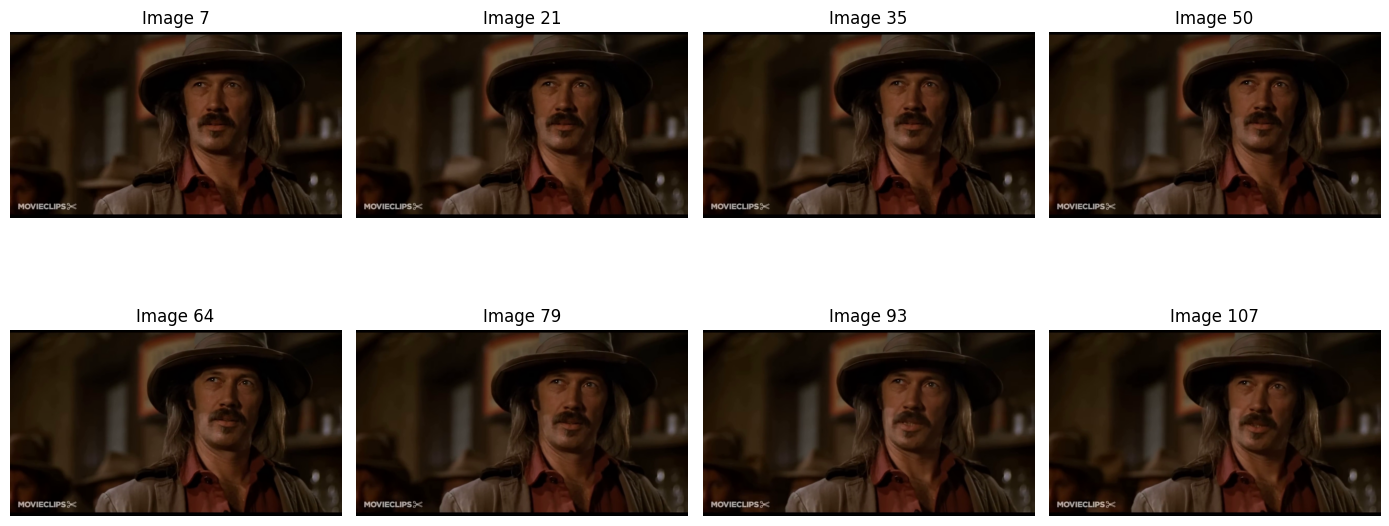

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Choisir une vidéo du groupe train
video = df_videos[df_videos["split"] == "train"].iloc[0]
chemin_video = video["video_path"]

print("Vidéo :", video["video_id"])
print("Partition :", video["split"])

# Ouvrir la vidéo
cap = cv2.VideoCapture(chemin_video)

if cap.isOpened():
    fps = cap.get(cv2.CAP_PROP_FPS)
    nb_images = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duree = nb_images / fps if fps > 0 else 0

    print("Nombre d'images :", nb_images)
    print("FPS :", round(fps, 2))
    print("Durée :", round(duree, 2), "secondes")

    if nb_images > 0:
        # Choisir 8 images réparties dans la vidéo
        positions = (
            (np.arange(8) + 0.5) * nb_images / 8
        ).astype(int)

        images_rgb = []
        positions_echouees = []

        for pos in positions:
            image_rgb = None

            # Si la lecture échoue, essayer une image voisine
            for p in [pos, pos + 1, pos - 1]:
                if 0 <= p < nb_images:
                    cap.set(cv2.CAP_PROP_POS_FRAMES, p)
                    succes, image = cap.read()

                    if succes and image is not None:
                        image_rgb = cv2.cvtColor(
                            image, cv2.COLOR_BGR2RGB
                        )
                        break

            if image_rgb is not None:
                images_rgb.append((pos, image_rgb))
            else:
                positions_echouees.append(pos)

        cap.release()

        print("Images extraites :", len(images_rgb))
        print("Positions échouées :", positions_echouees)

        # Afficher les images
        fig, axes = plt.subplots(2, 4, figsize=(14, 7))

        for ax in axes.flat:
            ax.axis("off")

        for ax, (pos, image_rgb) in zip(axes.flat, images_rgb):
            ax.imshow(image_rgb)
            ax.set_title(f"Image {pos}")

        plt.tight_layout()
        plt.show()

    else:
        cap.release()
        print("Nombre d'images indisponible.")

else:
    print("Impossible d'ouvrir la vidéo.")

Le test sur la vidéo 00002_clip_004 a réussi. La vidéo dure 4,8 secondes et contient 115 images. Les 8 images ont été extraites sans erreur. Nous pouvons maintenant passer à l’extraction des images de toutes les vidéos.

In [ ]:
def extraire_images(chemin_video, n=8):

    cap = cv2.VideoCapture(chemin_video)

    info = {
        "statut": "échec",
        "nb_images": 0,
        "fps": 0,
        "duree": 0,
        "positions_echouees": []
    }

    images_rgb = []

    if not cap.isOpened():
        info["statut"] = "vidéo illisible"
        return images_rgb, info

    fps = cap.get(cv2.CAP_PROP_FPS)
    nb_images = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    duree = nb_images / fps if fps > 0 else 0

    info["nb_images"] = nb_images
    info["fps"] = round(fps, 2)
    info["duree"] = round(duree, 2)

    if nb_images <= 0:
        info["statut"] = "aucune image"
        cap.release()
        return images_rgb, info

    # Choisir n images réparties dans la vidéo
    positions = (
        (np.arange(n) + 0.5) * nb_images / n
    ).astype(int)

    for pos in positions:

        image_rgb = None

        # Essayer la position choisie puis les images voisines
        for p in [pos, pos + 1, pos - 1]:

            if 0 <= p < nb_images:
                cap.set(cv2.CAP_PROP_POS_FRAMES, p)
                succes, image = cap.read()

                if succes and image is not None:
                    image_rgb = cv2.cvtColor(
                        image, cv2.COLOR_BGR2RGB
                    )
                    break

        if image_rgb is not None:
            images_rgb.append(image_rgb)
        else:
            info["positions_echouees"].append(pos)

    cap.release()

    info["nb_images_extraites"] = len(images_rgb)

    if len(images_rgb) == n:
        info["statut"] = "succès"
    elif len(images_rgb) > 0:
        info["statut"] = "partiel"

    return images_rgb, info

Tester sur 20 videos

In [ ]:
# import time
# #tester sur 20 vidéos du groupe train
# videos_test = df_videos[df_videos["split"] == "train"].head(20)

# resultats = []
# cache = {}
# debut = time.time()

# for _, video in videos_test.iterrows():
#     debut_video = time.time()

#     images, info = extraire_images(video["video_path"])

#     info["video_id"] = video["video_id"]
#     info["temps_s"] = round(time.time() - debut_video, 2)

#     resultats.append(info)
#     cache[video["video_id"]] = images

# #afficher les résultats
# df_test = pd.DataFrame(resultats)
# display(df_test)

# print("Bilan :")
# print(df_test["statut"].value_counts())

# print("Temps total :", round(time.time() - debut, 2), "secondes")
# print("Temps moyen par vidéo :", round(df_test["temps_s"].mean(), 2), "secondes")
# print("Estimation pour 3088 vidéos :",round(df_test["temps_s"].mean() * 3088 / 60, 1),"minutes")

Nous avons testé l’extraction sur 20 vidéos. Pour chaque vidéo, nous avons extrait 8 images avec le temps moyen est de 3,69 secondes par vidéo.

***vérifier que les images sont bien conservées***

In [ ]:
# print("Nombre de vidéos :", len(cache))
# print("Images extraites pour la première vidéo :",len(cache["00002_clip_004"]))
# print("Taille d'une image :",cache["00002_clip_004"][0].shape)

In [ ]:
#dossier pour enregistrer les images
dossier_images = "/content/images_test"
os.makedirs(dossier_images, exist_ok=True)

#enregistrer les images de chaque vidéo
for video_id, images in cache.items():
    dossier_video = os.path.join(dossier_images, video_id)
    os.makedirs(dossier_video, exist_ok=True)

    for i, image_rgb in enumerate(images):
        image_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)
        chemin = os.path.join(dossier_video, f"image_{i+1}.jpg")
        cv2.imwrite(chemin, image_bgr)

print("Sauvegarde terminée.")
print("Dossier :", dossier_images)

Sauvegarde terminée.
Dossier : /content/drive/MyDrive/Projet Multimédia/Fatima ez zahra /Video/images_test


In [ ]:
nb_dossiers = 0
nb_images = 0
for video_id in cache:
    dossier_video = os.path.join(dossier_images, video_id)

    if os.path.isdir(dossier_video):
        nb_dossiers += 1
        nb_images += len([
            f for f in os.listdir(dossier_video)
            if f.endswith(".jpg")
        ])

print("Dossiers de vidéos :", nb_dossiers)
print("Images enregistrées :", nb_images)

Dossiers de vidéos : 4
Images enregistrées : 32


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

#choisir une vidéo de test
video_id = "00002_clip_004"

#chemin de la première image enregistrée
chemin_image = os.path.join(dossier_images,video_id,"image_1.jpg")

#ouvrir et afficher l'image
image = Image.open(chemin_image)

print("Image trouvée :", os.path.exists(chemin_image))
print("Taille de l'image :", image.size)
print("Mode :", image.mode)

plt.imshow(image)
plt.axis("off")
plt.show()

**Réduire la dimension d'une image**

In [ ]:
def redimensionner(img, cible=224):
    hauteur, largeur = img.shape[:2]
    facteur = cible / min(hauteur, largeur)
    nouvelle_largeur = round(largeur * facteur)
    nouvelle_hauteur = round(hauteur * facteur)
    return cv2.resize(img,(nouvelle_largeur, nouvelle_hauteur),interpolation=cv2.INTER_AREA)

In [ ]:
print("Nombre de vidéos :", len(df_videos))
print("Colonnes :", df_videos.columns.tolist())
print("Fonction d'extraction :", callable(extraire_images))
print("Fonction de redimensionnement :", callable(redimensionner))

#dossier pour enregistrer les fichiers NPY
dossier_npy = "/content/data/extraction_complete/images_npy"
os.makedirs(dossier_npy, exist_ok=True)

#fichier pour suivre l'extraction
fichier_suivi = "/content/data/extraction_complete/suivi_extraction.csv"

print("Dossier de sauvegarde créé :", os.path.isdir(dossier_npy))
print("Chemin du fichier de suivi :", fichier_suivi)

Nombre de vidéos : 3088
Colonnes : ['video_id', 'video_path', 'mp4_lisible', 'dossier', 'split']
Fonction d'extraction : True
Fonction de redimensionnement : True
Dossier de sauvegarde créé : True
Chemin du fichier de suivi : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/extraction_complete/suivi_extraction.csv


Vérifier si extraction et redimension fonctionne sans creer un fichier temporelle ?

In [ ]:
import time
import cv2
import numpy as np

#choisir une vidéo du train
video = df_videos[df_videos["split"] == "train"].iloc[0]

debut = time.time()

#extraire 8 images
images, info = extraire_images(video["video_path"], n=8)
print("Vidéo :", video["video_id"])
print("Statut extraction :", info["statut"])
print("Images extraites :", len(images))

if len(images) == 8:
    #réduire les images en conservant les proportions
    images_reduites = np.stack([redimensionner(img) for img in images]).astype(np.uint8)
    print("Forme après réduction :", images_reduites.shape)
    print("Type :", images_reduites.dtype)
else:
    print("Attention : les 8 images n'ont pas toutes été extraites.")

print("Temps total :", round(time.time() - debut, 2), "secondes")

Vidéo : 00002_clip_004
Statut extraction : succès
Images extraites : 8
Forme après réduction : (8, 224, 398, 3)
Type : uint8
Temps total : 2.64 secondes


**Preparer le traitement des videos**

In [ ]:
#vérifier que tout est prêt
assert len(df_videos) == 3088
assert callable(extraire_images)
assert callable(redimensionner)
assert os.path.isdir(dossier_npy)

# Préparer le fichier pour noter les résultats de l'extraction
if not os.path.exists(fichier_suivi):
    colonnes = [
        "video_id",
        "split",
        "fichier",
        "nb_images_video",
        "images_extraites",
        "statut",
        "erreur"
    ]

    pd.DataFrame(columns=colonnes).to_csv(fichier_suivi, index=False)
print("Nombre de vidéos :", len(df_videos))
print("Dossier des images :", dossier_npy)
print("Fichier des résultats :", fichier_suivi)

Nombre de vidéos : 3088
Dossier des images : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/extraction_complete/images_npy
Fichier des résultats : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/extraction_complete/suivi_extraction.csv


In [ ]:
print("Vidéos dans df_videos :", len(df_videos))
print("Vidéos différentes :", df_videos["video_id"].nunique())
print("\nChemin d'une vidéo :")
print(df_videos["video_path"].iloc[0])

Vidéos dans df_videos : 3088
Vidéos différentes : 3088

Chemin d'une vidéo :
/content/PROJET_SID_2026/PROJET_SID_2026/movie/video/00000/00000_clip_001.mp4


## Lancer l’extraction des 3 088 vidéos

Préparer les résultats

In [ ]:
if os.path.exists(fichier_suivi):
    df_resultats = pd.read_csv(fichier_suivi)
else:
    df_resultats = pd.DataFrame()

resultats = {}

if not df_resultats.empty:
    for _, ligne in df_resultats.iterrows():
        resultats[str(ligne["video_id"])] = ligne.to_dict()

print("Vidéos dans la liste :", len(df_videos))
print("Résultats déjà enregistrés :", len(resultats))

Vidéos dans la liste : 3088
Résultats déjà enregistrés : 3088


Vérifier et enregistrer les fichiers

In [ ]:
def verifier_fichier(chemin):
    try:
        images = np.load(chemin, mmap_mode="r")
        return (
            images.ndim == 4
            and images.shape[0] == 8
            and images.shape[1] == 224
            and images.shape[2] >= 224
            and images.shape[3] == 3
            and images.dtype == np.uint8
        )
    except Exception:
        return False

def sauvegarder_resultats():
    df = pd.DataFrame(resultats.values())
    chemin_temp = fichier_suivi + ".tmp"
    df.to_csv(chemin_temp, index=False)
    os.replace(chemin_temp, fichier_suivi)

Traiter toutes les vidéos

In [ ]:
debut = time.time()
total = len(df_videos)

for numero, (_, video) in enumerate(df_videos.iterrows(), start=1):
    video_id = str(video["video_id"])
    split = video["split"]

    chemin_npy = os.path.join(dossier_npy, video_id + ".npy")
    chemin_temp = os.path.join(dossier_npy, video_id + "_tmp.npy")

    if os.path.exists(chemin_npy) and verifier_fichier(chemin_npy):
        resultats[video_id] = {
            "video_id": video_id,
            "split": split,
            "fichier": chemin_npy,
            "nb_images_video": resultats.get(
                video_id, {}
            ).get("nb_images_video", np.nan),
            "images_extraites": 8,
            "statut": "OK",
            "erreur": ""
        }

    else:
        for chemin in [chemin_npy, chemin_temp]:
            if os.path.exists(chemin):
                os.remove(chemin)

        try:
            images, info = extraire_images(
                video["video_path"], n=8
            )

            if len(images) == 8:
                images_reduites = np.stack([
                    redimensionner(img) for img in images
                ]).astype(np.uint8)

                if (
                    images_reduites.shape[0] == 8
                    and images_reduites.shape[1] == 224
                    and images_reduites.shape[2] >= 224
                    and images_reduites.shape[3] == 3
                ):
                    np.save(chemin_temp, images_reduites)

                    if verifier_fichier(chemin_temp):
                        os.replace(chemin_temp, chemin_npy)
                        statut = "OK"
                        erreur = ""
                    else:
                        os.remove(chemin_temp)
                        statut = "Erreur de sauvegarde"
                        erreur = "Fichier invalide"
                else:
                    statut = "Erreur de dimensions"
                    erreur = "Dimensions incorrectes"
            else:
                statut = info.get("statut", "Extraction partielle")
                erreur = f"{len(images)} image(s) extraite(s)"

            resultats[video_id] = {
                "video_id": video_id,
                "split": split,
                "fichier": chemin_npy if statut == "OK" else "",
                "nb_images_video": info.get(
                    "nb_images_video", np.nan
                ),
                "images_extraites": len(images),
                "statut": statut,
                "erreur": erreur
            }
#
        except Exception as e:
            if os.path.exists(chemin_temp):
                os.remove(chemin_temp)

            resultats[video_id] = {
                "video_id": video_id,
                "split": split,
                "fichier": "",
                "nb_images_video": np.nan,
                "images_extraites": 0,
                "statut": "Erreur",
                "erreur": str(e)[:300]
            }

    if numero % 50 == 0:
        sauvegarder_resultats()
        print(
            f"{numero}/{total} vidéos traitées - "
            f"{round((time.time() - debut) / 60, 1)} minutes"
        )

sauvegarder_resultats()
print("Traitement terminé.")

Vérifier les résultats

In [ ]:
df_resultats = pd.read_csv(fichier_suivi)
print("Nombre de vidéos enregistrées :", len(df_resultats))
print("\nRésultats par statut :")
print(df_resultats["statut"].value_counts(dropna=False))
print("\nExemples de vidéos en erreur :")
print(df_resultats[df_resultats["statut"] != "OK"][["video_id", "statut", "erreur"]].head(10))

Nombre de vidéos enregistrées : 3088

Résultats par statut :
statut
OK    3088
Name: count, dtype: int64

Exemples de vidéos en erreur :
Empty DataFrame
Columns: [video_id, statut, erreur]
Index: []


In [ ]:
#charger les résultats précédents
if os.path.exists(fichier_suivi):
    df_resultats = pd.read_csv(fichier_suivi)
else:
    df_resultats = pd.DataFrame()

resultats = {}

if not df_resultats.empty:
    for _, ligne in df_resultats.iterrows():
        resultats[str(ligne["video_id"])] = ligne.to_dict()

#vérifier si le fichier contient 8 images correctes
def verifier_fichier(chemin):
    try:
        images = np.load(chemin, mmap_mode="r")
        return (
            images.ndim == 4
            and images.shape[0] == 8
            and images.shape[1] == 224
            and images.shape[2] >= 224
            and images.shape[3] == 3
            and images.dtype == np.uint8
        )
    except Exception:
        return False

#enregistrer les résultats dans le CSV
def sauvegarder_resultats():
    df = pd.DataFrame(resultats.values())
    chemin_temp = fichier_suivi + ".tmp"
    df.to_csv(chemin_temp, index=False)
    os.replace(chemin_temp, fichier_suivi)

debut = time.time()
total = len(df_videos)

for numero, (_, video) in enumerate(df_videos.iterrows(), start=1):
    video_id = str(video["video_id"])
    split = video["split"]

    chemin_npy = os.path.join(dossier_npy, video_id + ".npy")
    chemin_temp = os.path.join(dossier_npy, video_id + "_tmp.npy")

    #garder les fichiers déjà traités correctement
    if os.path.exists(chemin_npy) and verifier_fichier(chemin_npy):
        ancienne_ligne = resultats.get(video_id, {})
        resultats[video_id] = {
            "video_id": video_id,
            "split": split,
            "fichier": chemin_npy,
            "nb_images_video": ancienne_ligne.get(
                "nb_images_video", np.nan
            ),
            "images_extraites": 8,
            "statut": "OK",
            "erreur": ""
        }

    else:
        #supprimer les fichiers incomplets
        for chemin in [chemin_npy, chemin_temp]:
            if os.path.exists(chemin):
                os.remove(chemin)

        try:
            images, info = extraire_images(
                video["video_path"], n=8
            )

            if len(images) == 8:
                images_reduites = np.stack([redimensionner(img) for img in images]).astype(np.uint8)

                #vérifier les dimensions avant la sauvegarde
                if (
                    images_reduites.shape[0] == 8
                    and images_reduites.shape[1] == 224
                    and images_reduites.shape[2] >= 224
                    and images_reduites.shape[3] == 3
                ):
                    np.save(chemin_temp, images_reduites)

                    if verifier_fichier(chemin_temp):
                        os.replace(chemin_temp, chemin_npy)
                        statut = "OK"
                        erreur = ""
                    else:
                        os.remove(chemin_temp)
                        statut = "Erreur de sauvegarde"
                        erreur = "Vérification du fichier échouée"
                else:
                    statut = "Erreur de dimensions"
                    erreur = "Dimensions des images incorrectes"

            else:
                statut = info.get("statut", "Extraction partielle")
                erreur = f"{len(images)} image(s) extraite(s)"

            resultats[video_id] = {
                "video_id": video_id,
                "split": split,
                "fichier": chemin_npy if statut == "OK" else "",
                "nb_images_video": info.get(
                    "nb_images_video", np.nan
                ),
                "images_extraites": len(images),
                "statut": statut,
                "erreur": erreur
            }

        except Exception as e:
            if os.path.exists(chemin_temp):
                os.remove(chemin_temp)

            resultats[video_id] = {
                "video_id": video_id,
                "split": split,
                "fichier": "",
                "nb_images_video": np.nan,
                "images_extraites": 0,
                "statut": "Erreur",
                "erreur": str(e)[:300]
            }

    #enregistrer les résultats toutes les 50 vidéos
    if numero % 50 == 0:
        sauvegarder_resultats()
        print(f"{numero}/{total} vidéos traitées - "f"{round((time.time() - debut) / 60, 1)} minutes")

#enregistrer les derniers résultats
sauvegarder_resultats()
print("Traitement terminé.")
print(pd.DataFrame(resultats.values())["statut"].value_counts())
print("Résultats enregistrés dans :", fichier_suivi)


In [ ]:
import os
from pathlib import Path

dossier = Path(dossier_npy)

fichiers_npy = list(dossier.glob("*.npy"))

print("Dossier vérifié :", dossier)
print("Nombre de fichiers NPY :", len(fichiers_npy))
print("Nombre de vidéos attendues :", len(df_videos))
print("Exemples :", [f.name for f in fichiers_npy[:5]])

Dossier vérifié : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/extraction_complete/images_npy
Nombre de fichiers NPY : 3088
Nombre de vidéos attendues : 3088
Exemples : ['00255_clip_001.npy', '00255_clip_003.npy', '00255_clip_006.npy', '00255_clip_008.npy', '00255_clip_015.npy']


L’extraction des images a été réalisée sur les 3 088 vidéos du dataset. Pour chaque vidéo, 8 images ont été extraites à différents moments, puis redimensionnées en conservant leurs proportions, avec un petit côté de 224 pixels. Les images ont été enregistrées au format NumPy (.npy) pour faciliter leur utilisation dans les étapes suivantes.

La vérification des fichiers a donné les résultats suivants :

3 088 vidéos avec le statut OK ;

aucune erreur détectée ;

8 images attendues par vidéo, soit 24 704 images au total.

Les fichiers ont ensuite été vérifiés une seconde fois. Comme ils étaient déjà valides, ils ont été conservés sans refaire l’extraction.

Conclusion : l’étape d’extraction est terminée. Les images sont prêtes à être utilisées

# **Construire une baseline visuelle avec OpenCV**

## Extraire 141 Caracteristiques

In [ ]:
import os
import numpy as np

fichiers_npy = sorted([
    f for f in os.listdir(dossier_npy)
    if f.endswith(".npy") and not f.endswith("_tmp.npy")
])

print("Nombre de fichiers NPY :", len(fichiers_npy))
print("Premier fichier :", fichiers_npy[0] if fichiers_npy else "Aucun fichier")

Nombre de fichiers NPY : 3088
Premier fichier : 00000_clip_001.npy


Calculer les caractéristiques visuelles à partir des 8 images

In [ ]:
#charger un fichier pour vérifier sa structure
nom_fichier = fichiers_npy[0]
chemin_fichier = os.path.join(dossier_npy, nom_fichier)

images = np.load(chemin_fichier)

print("Vidéo :", nom_fichier)
print("Forme du tableau :", images.shape)
print("Type des données :", images.dtype)
print("Valeur minimale :", images.min())
print("Valeur maximale :", images.max())
print("8 images :", images.shape[0] == 8)
print("3 canaux couleur :", images.shape[-1] == 3)

Vidéo : 00000_clip_001.npy
Forme du tableau : (8, 224, 398, 3)
Type des données : uint8
Valeur minimale : 0
Valeur maximale : 255
8 images : True
3 canaux couleur : True


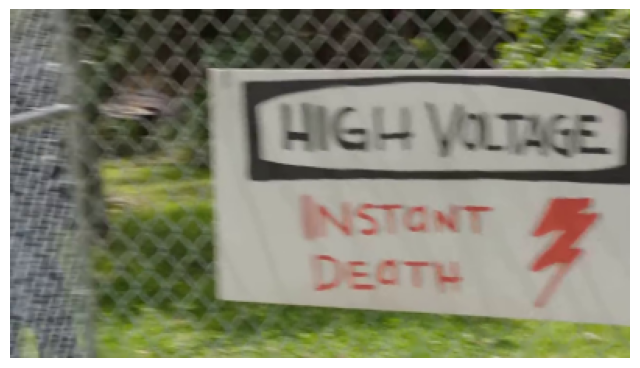

In [ ]:
image = images[0]

plt.figure(figsize=(8, 5))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
#sélectionner la première image
image = images[0]

#calculer la luminosité moyenne
luminosite = np.mean(
    0.299 * image[:, :, 0] +
    0.587 * image[:, :, 1] +
    0.114 * image[:, :, 2]
)

print("Luminosité moyenne :", round(luminosite, 2))

Luminosité moyenne : 121.36


In [ ]:
#calculer la luminosité de chaque image
luminosites = []

for image in images:
    gris = (
        0.299 * image[:, :, 0] +
        0.587 * image[:, :, 1] +
        0.114 * image[:, :, 2]
    )

    luminosites.append(np.mean(gris))
#résumer les 8 images
print("Luminosité moyenne des 8 images :", round(np.mean(luminosites), 2))
print("Écart-type de luminosité :", round(np.std(luminosites), 2))

Luminosité moyenne des 8 images : 108.7
Écart-type de luminosité : 7.52


In [ ]:
#calculer les couleurs moyennes RGB pour chaque image
moyennes_rgb = []

for image in images:
    rouge = np.mean(image[:, :, 0])
    vert = np.mean(image[:, :, 1])
    bleu = np.mean(image[:, :, 2])

    moyennes_rgb.append([rouge, vert, bleu])

moyennes_rgb = np.array(moyennes_rgb)
print("Rouge moyen :", round(np.mean(moyennes_rgb[:, 0]), 2))
print("Vert moyen :", round(np.mean(moyennes_rgb[:, 1]), 2))
print("Bleu moyen :", round(np.mean(moyennes_rgb[:, 2]), 2))

Rouge moyen : 106.02
Vert moyen : 112.06
Bleu moyen : 98.45


In [ ]:
histogrammes = []

for image in images:
    #les images sont déjà en RGB : conversion correcte vers HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    #histogramme : 8 niveaux de teinte, 4 de saturation, 4 de luminosité
    hist = cv2.calcHist(
        [hsv],
        [0, 1, 2],
        None,
        [8, 4, 4],
        [0, 180, 0, 256, 0, 256]
    )

    #normaliser l'histogramme pour comparer les images
    hist = cv2.normalize(hist, hist).flatten()
    histogrammes.append(hist)

histogrammes = np.array(histogrammes)

print("Forme des histogrammes :", histogrammes.shape)
print("Nombre de valeurs par image :", histogrammes.shape[1])
print("Nombre d'images traitées :", histogrammes.shape[0])

Forme des histogrammes : (8, 128)
Nombre de valeurs par image : 128
Nombre d'images traitées : 8


In [ ]:
histogramme_video = np.mean(histogrammes, axis=0)
print("Forme de l'histogramme de la vidéo :", histogramme_video.shape)
print("Nombre de caractéristiques :", len(histogramme_video))

Forme de l'histogramme de la vidéo : (128,)
Nombre de caractéristiques : 128


In [ ]:
#comparer les images successives
differences = []

for i in range(len(images) - 1):
    #passer en niveaux de gris
    gris1 = cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)
    gris2 = cv2.cvtColor(images[i + 1], cv2.COLOR_RGB2GRAY)

    #redimensionner à la meme taille pour comparer
    gris1 = cv2.resize(gris1, (160, 90))
    gris2 = cv2.resize(gris2, (160, 90))

    #différence moyenn entre les pixels
    difference = np.mean(np.abs(gris1.astype(float) - gris2.astype(float)))
    differences.append(difference)

print("Nombre de comparaisons :", len(differences))
print("Variation visuelle moyenne :", round(np.mean(differences), 2))
print("Variation visuelle maximale :", round(np.max(differences), 2))

Nombre de comparaisons : 7
Variation visuelle moyenne : 40.31
Variation visuelle maximale : 54.85


In [ ]:
#caractéristiques de la vidéo testée
luminosite_moyenne = np.mean(luminosites)
luminosite_std = np.std(luminosites)
rgb_moyen = np.mean(moyennes_rgb, axis=0)
variation_moyenne = np.mean(differences)
variation_maximale = np.max(differences)

#réunir toutes les caractéristiques
features_video = np.concatenate([
    [luminosite_moyenne, luminosite_std],
    rgb_moyen,
    histogramme_video,
    [variation_moyenne, variation_maximale]
])
print("Nombre total de caractéristiques :", len(features_video))
print("Forme du vecteur :", features_video.shape)
print("Toutes les valeurs sont numériques :", np.isfinite(features_video).all())

Nombre total de caractéristiques : 135
Forme du vecteur : (135,)
Toutes les valeurs sont numériques : True


Calculer les caracteristiques

In [ ]:
def calculer_caracteristiques(images):
    images = np.asarray(images)
    if images.ndim != 4 or len(images) == 0 or images.shape[-1] != 3:
        raise ValueError("Les images doivent avoir la forme (N, H, W, 3).")
    if images.dtype != np.uint8:
        raise ValueError("Les images doivent être en uint8.")
    luminosites = []
    contrastes = []
    moyennes_rgb = []
    stds_rgb = []
    histogrammes = []
    sin_hues = []
    cos_hues = []

    for image in images:
        #luminosité et contraste
        gris = (
            0.299 * image[:, :, 0]
            + 0.587 * image[:, :, 1]
            + 0.114 * image[:, :, 2]
        )
        luminosites.append(np.mean(gris))
        contrastes.append(np.std(gris))

        #moyennes et écarts-types RGB
        moyennes_rgb.append(np.mean(image, axis=(0, 1)))
        stds_rgb.append(np.std(image, axis=(0, 1)))

        #conversion RGB vers HSV
        hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

        #histogramme HSV normalisé par la somme
        hist = cv2.calcHist(
            [hsv], [0, 1, 2], None,
            [8, 4, 4],
            [0, 180, 0, 256, 0, 256]
        ).flatten()
        hist = hist / (hist.sum() + 1e-8)
        histogrammes.append(hist)

        # Teinte circulaire, pondérée par la saturation
        h = hsv[:, :, 0].astype(float) * 2 * np.pi / 180
        poids = hsv[:, :, 1].astype(float)
        denom = poids.sum() + 1e-8
        sin_hues.append(np.sum(np.sin(h) * poids) / denom)
        cos_hues.append(np.sum(np.cos(h) * poids) / denom)

    #résumé des 8 images
    rgb_moyen = np.mean(moyennes_rgb, axis=0)
    rgb_std = np.mean(stds_rgb, axis=0)
    histogramme_video = np.mean(histogrammes, axis=0)

    #variation entre images successives
    differences = []
    for i in range(len(images) - 1):
        gris1 = cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)
        gris2 = cv2.cvtColor(images[i + 1], cv2.COLOR_RGB2GRAY)
        gris1 = cv2.resize(gris1, (160, 90))
        gris2 = cv2.resize(gris2, (160, 90))
        differences.append(np.mean(np.abs(gris1.astype(np.float32) - gris2.astype(np.float32))))
    variation_moyenne = np.mean(differences) if differences else 0.0
    variation_maximale = np.max(differences) if differences else 0.0

    return np.concatenate([
        [np.mean(luminosites), np.std(luminosites),
         np.mean(contrastes)],
        rgb_moyen,
        rgb_std,
        histogramme_video,
        [np.mean(sin_hues), np.mean(cos_hues)],
        [variation_moyenne, variation_maximale]
    ])

In [ ]:
#vérifier la correspondance entre les noms de fichiers et les video_id
noms_npy = {os.path.splitext(f)[0] for f in fichiers_npy}
noms_df = set(df_videos["video_id"].astype(str))
print("Nombre de fichiers NPY :", len(noms_npy))
print("Nombre de video_id dans df_videos :", len(noms_df))
print("Fichiers NPY sans correspondance :", len(noms_npy - noms_df))
print("video_id sans fichier NPY :", len(noms_df - noms_npy))

Nombre de fichiers NPY : 3088
Nombre de video_id dans df_videos : 3088
Fichiers NPY sans correspondance : 3088
video_id sans fichier NPY : 3088


In [ ]:
from pathlib import Path
import json
#dossier des annotations
dossier_json = Path(base_path) / "annotation"
#lire les annotations
annotations = []
for fichier in dossier_json.rglob("*.json"):
    with open(fichier, "r", encoding="utf-8") as f:
        annotations.append(json.load(f))
df_annotations = pd.DataFrame(annotations)

print("Nombre d'annotations :", len(df_annotations))
print("Identifiants uniques :", df_annotations["video_id"].nunique())

df_videos = df_videos.drop(columns=["emotion", "emotion_x", "emotion_y"],errors="ignore")
df_videos = df_videos.merge(df_annotations[["video_id", "emotion"]],on="video_id",how="left",validate="one_to_one")

print("\nDimensions :", df_videos.shape)
print("Colonnes :", df_videos.columns.tolist())
print("Émotions manquantes :", df_videos["emotion"].isna().sum())
print("\nRépartition des partitions :")
print(df_videos["split"].value_counts())
print("\nExemple :")
display(df_videos[["video_id", "split", "emotion"]].head())

Nombre d'annotations : 3088
Identifiants uniques : 3088

Dimensions : (3088, 5)
Colonnes : ['video_id', 'video_path', 'dossier', 'split', 'emotion']
Émotions manquantes : 0

Répartition des partitions :
split
train    2207
dev       442
test      439
Name: count, dtype: int64

Exemple :


,video_id,split,emotion
0,00000_clip_001,test,anger
1,00000_clip_002,test,anger
2,00000_clip_006,test,contentment
3,00000_clip_009,test,anger
4,00000_clip_012,test,anger


In [ ]:
from pathlib import Path

dossier_npy = Path(dossier_npy)

print("Dossier trouvé :", dossier_npy.exists())
print("Nombre de fichiers NPY :", len(list(dossier_npy.glob("*.npy"))))

Dossier trouvé : True
Nombre de fichiers NPY : 3088


In [ ]:
from tqdm.auto import tqdm
dossier_sortie = Path("/content/data/features_baseline")
dossier_sortie.mkdir(parents=True, exist_ok=True)

# associer chaque identifiant à son fichier NPY
chemins_npy = {
    f.stem: f
    for f in dossier_npy.glob("*.npy")
}
colonnes_requises = ["video_id", "emotion", "split"]
manquantes = [
    col for col in colonnes_requises
    if col not in df_videos.columns
]
if manquantes:
    raise ValueError(f"Colonnes manquantes : {manquantes}")

matrice = []
metadonnees = []

#calcule les caractéristiques vidéo par vidéo
for _, ligne in tqdm(
    df_videos.iterrows(),
    total=len(df_videos),
    desc="Calcul des caractéristiques"
):
    video_id = str(ligne["video_id"])
    chemin = chemins_npy.get(video_id)

    if chemin is None:
        raise FileNotFoundError(
            f"Fichier NPY introuvable pour {video_id}"
        )

    images_video = np.load(chemin)
    caracteristiques = calculer_caracteristiques(images_video)
    if caracteristiques.shape != (141,):
        raise ValueError(
            f"Nombre incorrect de caractéristiques pour {video_id}"
        )
    if not np.isfinite(caracteristiques).all():
        raise ValueError(
            f"Valeurs non numériques pour {video_id}"
        )
    matrice.append(caracteristiques)
    metadonnees.append({
        "video_id": video_id,
        "emotion": ligne["emotion"],
        "split": ligne["split"]
    })

#transformer les résultats en tableaux
X_video = np.vstack(matrice)
df_metadata = pd.DataFrame(metadonnees)

#noms des 141 caractéristiques
noms_features = [
    "luminosite_moyenne",
    "variation_luminosite",
    "contraste",
    "rouge_moyen",
    "vert_moyen",
    "bleu_moyen",
    "rouge_variation",
    "vert_variation",
    "bleu_variation"
]

noms_features += [
    f"couleur_{i}" for i in range(128)
]

noms_features += [
    "teinte_sinus",
    "teinte_cosinus",
    "difference_moyenne",
    "difference_maximale"
]
assert len(noms_features) == 141
assert X_video.shape == (len(df_videos), 141)

#sauvegarder les résultats
np.save(dossier_sortie / "X_video_baseline.npy", X_video)
df_metadata.to_csv(dossier_sortie / "labels_partitions.csv",index=False)
pd.DataFrame({"feature": noms_features}).to_csv(dossier_sortie / "noms_caracteristiques.csv",index=False)

print("\nCalcul terminé !")
print("Forme de la matrice :", X_video.shape)
print("Nombre de vidéos :", len(df_metadata))
print("Nombre de caractéristiques :", len(noms_features))
print("Toutes les valeurs sont numériques :", np.isfinite(X_video).all())
print("Dossier de sauvegarde :", dossier_sortie)

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

dossier_features = Path("/content/data/features_baseline")

X_baseline = np.load(dossier_features / "X_video_baseline.npy")
labels = pd.read_csv(
    dossier_features / "labels_partitions.csv",
    dtype=str
)

y = labels["emotion"].to_numpy()
splits = labels["split"].to_numpy()

X_train_base = X_baseline[splits == "train"]
y_train_base = y[splits == "train"]

X_dev_base = X_baseline[splits == "dev"]
y_dev_base = y[splits == "dev"]

print("Train :", X_train_base.shape)
print("Dev :", X_dev_base.shape)

Train : (2207, 141)
Dev : (442, 141)


In [ ]:
import numpy as np
import pandas as pd

X_baseline = np.load(dossier_features / "X_video_baseline.npy")
labels = pd.read_csv(dossier_features / "labels_partitions.csv", dtype=str)

y = labels["emotion"].to_numpy()
splits = labels["split"].to_numpy()

X_train_base = X_baseline[splits == "train"]
y_train_base = y[splits == "train"]

X_dev_base = X_baseline[splits == "dev"]
y_dev_base = y[splits == "dev"]

print("Train :", X_train_base.shape)
print("Dev :", X_dev_base.shape)

Train : (2207, 141)
Dev : (442, 141)


In [ ]:
from pathlib import Path

print("Dossier trouvé :", dossier_npy.exists())
print("Nombre de fichiers NPY :", len(list(dossier_npy.glob("*.npy"))))
print("Exemple :", next(dossier_npy.glob("*.npy"), None))

Dossier trouvé : True
Nombre de fichiers NPY : 3088
Exemple : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/extraction_complete/images_npy/00255_clip_001.npy


In [ ]:
dossier_sortie = Path("/content/data/features_baseline")

for nom in [
    "X_video_baseline.npy",
    "labels_partitions.csv",
    "noms_caracteristiques.csv"
]:
    chemin = dossier_sortie / nom
    print(nom, ":", "Présent" if chemin.exists() else "Absent")

X_video_baseline.npy : Présent
labels_partitions.csv : Présent
noms_caracteristiques.csv : Présent


In [ ]:
# infos["film_id"] = infos["video_id"].str.split("_").str[0]
# infos[["video_id", "emotion", "split", "film_id"]].to_csv(dossier_features / "labels_partitions.csv",index=False)
# print("Colonnes :", infos[["video_id", "emotion", "split", "film_id"]].columns.tolist())
# display(infos[["video_id", "emotion", "split", "film_id"]].head())

In [ ]:
import pandas as pd
from pathlib import Path

dossier_features = Path("/content/data/features_baseline")
fichier_labels = dossier_features / "labels_partitions.csv"
infos = pd.read_csv(fichier_labels, dtype=str)
print("Colonnes disponibles :", infos.columns.tolist())
display(infos.head())

Colonnes disponibles : ['video_id', 'emotion', 'split', 'film_id']


,video_id,emotion,split,film_id
0,00000_clip_001,anger,test,00000
1,00000_clip_002,anger,test,00000
2,00000_clip_006,contentment,test,00000
3,00000_clip_009,anger,test,00000
4,00000_clip_012,anger,test,00000


In [ ]:
print(pd.crosstab(infos["split"], infos["emotion"]))

emotion  amusement  anger  awe  contentment  disgust  excitement  fear  \
split                                                                    
dev             35     98   40           54       43          51    74   
test            35     96   40           54       43          51    74   
train          174    483  206          265      211         252   371   

emotion  sadness  
split             
dev           47  
test          46  
train        245  


In [ ]:
dossier_features = Path("/content/data/features_baseline")

X = np.load(dossier_features / "X_video_baseline.npy")
labels = pd.read_csv(dossier_features / "labels_partitions.csv",dtype=str)
noms = pd.read_csv(dossier_features / "noms_caracteristiques.csv")

print("Matrice X :", X.shape)
print("Nombre de lignes dans labels :", len(labels))
print("Nombre de noms de caractéristiques :", len(noms))
print("Colonnes de labels :", labels.columns.tolist())
print("Valeurs de X toutes finies :", np.isfinite(X).all())

Matrice X : (3088, 141)
Nombre de lignes dans labels : 3088
Nombre de noms de caractéristiques : 141
Colonnes de labels : ['video_id', 'emotion', 'split', 'film_id']
Valeurs de X toutes finies : True


Nous avons calculé 141 caractéristiques visuelles pour chaque vidéo à partir de 8 images. Ces caractéristiques décrivent les couleurs, la luminosité, le contraste et les changements entre les images. Nous avons associé chaque vidéo à son émotion et à sa partition (train, dev ou test). Enfin, nous avons enregistré les résultats dans plusieurs fichiers et vérifié qu’ils étaient corrects.

Les identifiants, les labels, les partitions et les noms des caractéristiques sont conservés séparément.

##Entraînement d'un modèle de référence à partir des 141 caractéristiques visuelles classiques Opencv Regression logistique


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, accuracy_score

modele_caracteristiques = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

modele_caracteristiques.fit(X_train_base, y_train_base)
pred_dev_caracteristiques = modele_caracteristiques.predict(X_dev_base)
f1_caracteristiques = f1_score(
    y_dev_base,
    pred_dev_caracteristiques,
    average="macro"
)

accuracy_caracteristiques = accuracy_score(y_dev_base, pred_dev_caracteristiques)
print(f"F1 macro sur dev : {f1_caracteristiques:.4f}")
print(f"Accuracy sur dev : {accuracy_caracteristiques:.4f}")
print("\nRapport par émotion :")
print(classification_report(
    y_dev_base,
    pred_dev_caracteristiques,
    zero_division=0
))

F1 macro sur dev : 0.2111
Accuracy sur dev : 0.2240

Rapport par émotion :
              precision    recall  f1-score   support

   amusement       0.07      0.09      0.07        35
       anger       0.34      0.27      0.30        98
         awe       0.27      0.30      0.28        40
 contentment       0.09      0.09      0.09        54
     disgust       0.15      0.21      0.18        43
  excitement       0.15      0.16      0.15        51
        fear       0.44      0.32      0.37        74
     sadness       0.23      0.26      0.24        47

    accuracy                           0.22       442
   macro avg       0.22      0.21      0.21       442
weighted avg       0.25      0.22      0.23       442



La régression logistique obtient une accuracy de 22,4 % sur dev, soit environ 99 clips correctement classés sur 442.
Elle reconnaît mieux fear (F1-score = 0,37) et anger (0,30), mais distingue difficilement les autres émotions.
Avec un F1-macro de 0,2111, ses performances restent faibles pour reconnaître les huit émotions.

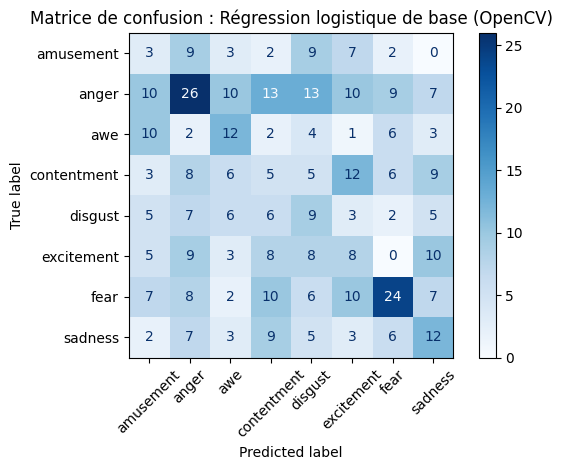

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matrice_reg_openCV = confusion_matrix(
    y_dev_base,
    pred_dev_caracteristiques,
    labels=modele_caracteristiques.classes_
)

affichage = ConfusionMatrixDisplay(
    confusion_matrix=matrice_reg_openCV,
    display_labels=modele_caracteristiques.classes_
)

affichage.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matrice de confusion : Régression logistique de base (OpenCV)")
plt.tight_layout()
plt.show()

matrice de conf montre que le modèle reconnaît mieux anger et fear, mais confond encore plusieurs émotions. Les prédictions correctes restent faibles pour la plupart des classes, notamment amusement et contentment.

In [ ]:
train_labels = labels[labels["film_id"].isin(train_ids)].copy()
film_train = train_labels["film_id"].to_numpy()

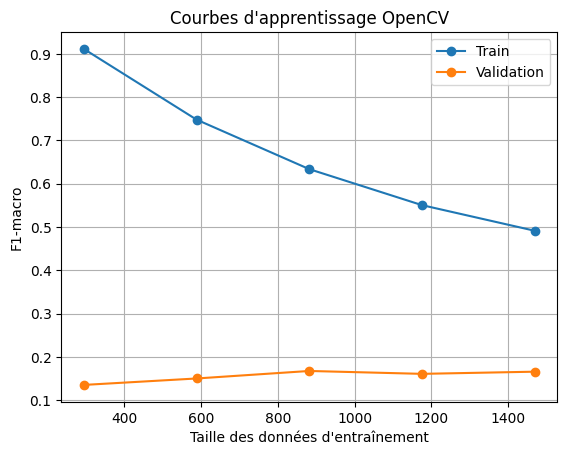

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import learning_curve, GroupKFold

cv = GroupKFold(n_splits=3)

tailles, scores_train, scores_val = learning_curve(
    modele_caracteristiques,
    X_train_base,
    y_train_base,
    groups=film_train,
    cv=cv,
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1, 5),
    n_jobs=-1
)

plt.plot(tailles, scores_train.mean(axis=1), marker="o", label="Train")
plt.plot(tailles, scores_val.mean(axis=1), marker="o", label="Validation")

plt.xlabel("Taille des données d'entraînement")
plt.ylabel("F1-macro")
plt.title("Courbes d'apprentissage OpenCV")
plt.legend()
plt.grid()
plt.show()

Les courbes d'apprentissage montrent que le score de validation reste faible et relativement stable autour de 0,17, tandis que le score d'entraînement diminue à mesure que la taille du jeu de données augmente. L'écart persistant entre les deux courbes traduit une faible capacité de généralisation du modèle. Malgré l'ajout de données d'entraînement, les performances sur les données de validation ne s'améliorent pas significativement,

##Optimisation des hyperparamètres de la régression logistique par Grid Search

In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, GroupKFold

pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

#les hyperparamètres à tester
parametres = {
    "logisticregression__C": [0.001, 0.003, 0.01, 0.1, 1, 10],
    "logisticregression__class_weight": ["balanced", None]
}

#validation croisée par film
cv=StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
#recherche des meilleurs hyperparamètres
recherche = GridSearchCV(
    pipeline,
    parametres,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

#entraîner et optimiser le modèle
recherche.fit(
    X_train_base,
    y_train_base,
    groups=film_train
)

print("Meilleurs paramètres :", recherche.best_params_)
print("Meilleur F1-macro en validation croisée :",round(recherche.best_score_, 4))

predictions_log_optimise = recherche.predict(X_dev_base)


Meilleurs paramètres : {'logisticregression__C': 0.003, 'logisticregression__class_weight': 'balanced'}
Meilleur F1-macro en validation croisée : 0.1902


**Vérifier les performances sur Dev**

In [ ]:
from sklearn.metrics import f1_score, accuracy_score, classification_report

predictions_log_optimise = recherche.predict(X_dev_base)

print("F1-macro Dev :",round(f1_score(y_dev_base, predictions_log_optimise, average="macro"), 4))
print("Accuracy Dev :",round(accuracy_score(y_dev_base, predictions_log_optimise), 4))

print("\nRapport par émotion :")
print(classification_report(
    y_dev_base,
    predictions_log_optimise,
    zero_division=0
))

F1-macro Dev : 0.1887
Accuracy Dev : 0.2014

Rapport par émotion :
              precision    recall  f1-score   support

   amusement       0.03      0.06      0.04        35
       anger       0.32      0.20      0.25        98
         awe       0.14      0.15      0.15        40
 contentment       0.14      0.15      0.15        54
     disgust       0.12      0.19      0.15        43
  excitement       0.15      0.14      0.14        51
        fear       0.44      0.38      0.41        74
     sadness       0.26      0.21      0.23        47

    accuracy                           0.20       442
   macro avg       0.20      0.18      0.19       442
weighted avg       0.23      0.20      0.21       442



Le modèle obtient un F1-macro de 0,19 et une accuracy de 20 % sur Dev. Il reconnaît mieux anger et fear, mais a du mal à distinguer les autres émotions.

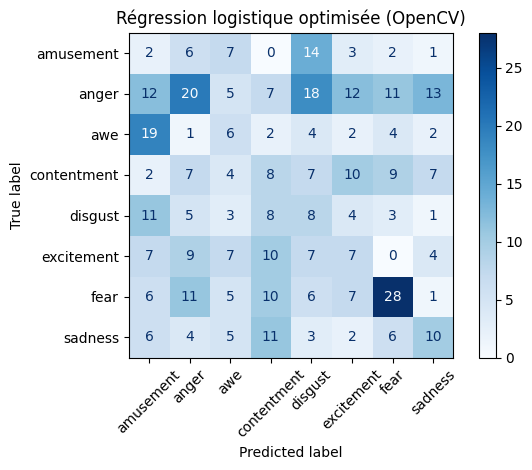

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matrice_log_optimise_OpenCV = confusion_matrix(
    y_dev_base,
    predictions_log_optimise,
    labels=recherche.best_estimator_.classes_
)

affichage = ConfusionMatrixDisplay(
    confusion_matrix=matrice_log_optimise_OpenCV,
    display_labels=recherche.best_estimator_.classes_
)

affichage.plot(cmap="Blues", xticks_rotation=45)
plt.title("Régression logistique optimisée (OpenCV)")
plt.tight_layout()
plt.show()

anger est l'émotion la mieux reconnue : 57 prédictions correctes.
fear est également assez bien reconnue : 32 prédictions correctes.
Les autres émotions sont beaucoup moins bien reconnues.
Le modèle confond notamment plusieurs émotions avec anger : par exemple, 26 clips contentment et 24 clips excitement sont prédits comme anger.

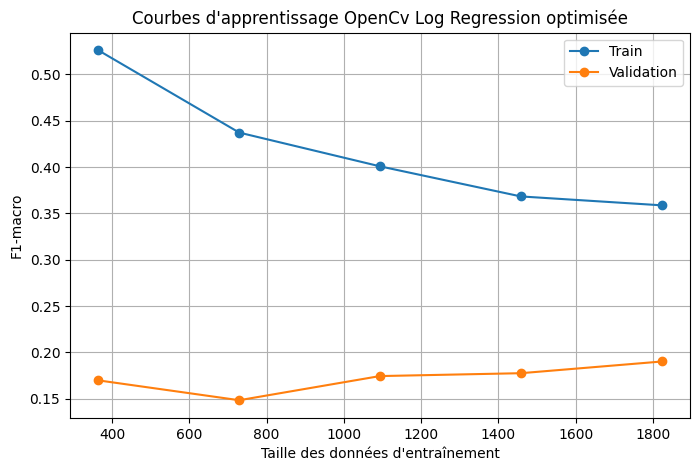

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import learning_curve, GroupKFold

tailles, scores_train, scores_val = learning_curve(
    recherche.best_estimator_,
    X_train_base,
    y_train_base,
    groups=film_train,
    cv=StratifiedGroupKFold(
       n_splits=5,
       shuffle=True,
       random_state=42
    ),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1, 5),
    n_jobs=-1
)

plt.figure(figsize=(8, 5))

plt.plot(tailles, scores_train.mean(axis=1),marker="o", label="Train")

plt.plot(tailles, scores_val.mean(axis=1),marker="o", label="Validation")

plt.xlabel("Taille des données d'entraînement")
plt.ylabel("F1-macro")
plt.title("Courbes d'apprentissage OpenCv Log Regression optimisée")
plt.legend()
plt.grid()
plt.show()

Le score de validation augmente progressivement jusqu'à 0,19, tandis que le score d'entraînement diminue à 0,36. Le modèle améliore légèrement sa capacité de généralisation, mais les performances restent faibles.

##Random Forest sur les caractrestiques visuelles

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report, accuracy_score

foret = RandomForestClassifier(
    n_estimators=400,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

foret.fit(X_train_base, y_train_base)
predictions_rf = foret.predict(X_dev_base)

print("F1-macro :", round(f1_score(y_dev_base, predictions_rf, average="macro"), 4))
print("Accuracy :", round(accuracy_score(y_dev_base, predictions_rf), 4))
print(classification_report(y_dev_base, predictions_rf, zero_division=0))

F1-macro : 0.1879
Accuracy : 0.2285
              precision    recall  f1-score   support

   amusement       0.16      0.11      0.13        35
       anger       0.23      0.45      0.30        98
         awe       0.46      0.15      0.23        40
 contentment       0.11      0.07      0.09        54
     disgust       0.09      0.09      0.09        43
  excitement       0.21      0.06      0.09        51
        fear       0.34      0.36      0.35        74
     sadness       0.26      0.19      0.22        47

    accuracy                           0.23       442
   macro avg       0.23      0.19      0.19       442
weighted avg       0.24      0.23      0.21       442



Random Forest obtient une accuracy de 22,85 % et un F1-macro de 0,1879, donc il est moins performant que la régression logistique.
Il reconnaît surtout fear (F1 = 0,35) et anger (F1 = 0,30), mais distingue mal les autres émotions

##Optimisation des hyperparamètres avec Grid Search pour Random forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import f1_score, classification_report, accuracy_score

foret_rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

parametres_rf = {
    "n_estimators": [200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 4]
}

recherche_rf = GridSearchCV(
    foret_rf,
    parametres_rf,
    scoring="f1_macro",
    cv=StratifiedGroupKFold(
       n_splits=5,
       shuffle=True,
       random_state=42
    ),
    n_jobs=-1
)

recherche_rf.fit(
    X_train_base,
    y_train_base,
    groups=film_train
)

meilleur_rf = recherche_rf.best_estimator_
predictions_rf_optimise = meilleur_rf.predict(X_dev_base)

print("Meilleurs paramètres :", recherche_rf.best_params_)
print("Meilleur F1-macro en validation croisée :", round(recherche_rf.best_score_, 4))
print("Accuracy :", round(accuracy_score(y_dev_base, predictions_rf_optimise), 4))
print("F1-macro :", round(f1_score(y_dev_base, predictions_rf_optimise, average="macro"), 4))

print("\nRapport par émotion :")
print(classification_report(
    y_dev_base,
    predictions_rf_optimise,
    zero_division=0
))

Meilleurs paramètres : {'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 200}
Meilleur F1-macro en validation croisée : 0.2031
Accuracy : 0.2172
F1-macro : 0.198

Rapport par émotion :
              precision    recall  f1-score   support

   amusement       0.15      0.17      0.16        35
       anger       0.23      0.32      0.27        98
         awe       0.25      0.12      0.17        40
 contentment       0.14      0.15      0.14        54
     disgust       0.09      0.12      0.10        43
  excitement       0.30      0.14      0.19        51
        fear       0.32      0.32      0.32        74
     sadness       0.25      0.21      0.23        47

    accuracy                           0.22       442
   macro avg       0.22      0.19      0.20       442
weighted avg       0.23      0.22      0.22       442



Le modèle Random Forest optimisé obtient une accuracy de 21,72 % et un F1-macro de 0,198. Il reconnaît mieux les émotions fear et anger, mais confond encore plusieurs émotions. Les résultats restent faibles et le modèle a des difficultés à reconnaître correctement les huit émotions.

###Matrice de  confusion random forest Opencv

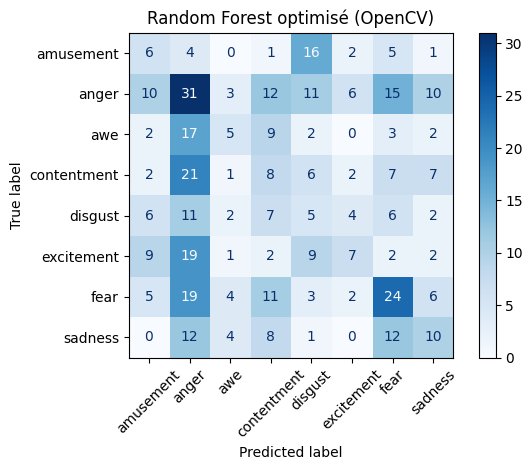

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matrice_rf_OpenCV = confusion_matrix(
    y_dev_base,
    predictions_rf_optimise,
    labels=meilleur_rf.classes_
)

affichage = ConfusionMatrixDisplay(
    confusion_matrix=matrice_rf_OpenCV,
    display_labels=meilleur_rf.classes_
)

affichage.plot(cmap="Blues", xticks_rotation=45)
plt.title("Random Forest optimisé (OpenCV)")
plt.tight_layout()
plt.show()

Le modèle reconnaît mieux anger et fear, mais confond encore plusieurs émotions. Les résultats restent faibles pour la majorité des classes.

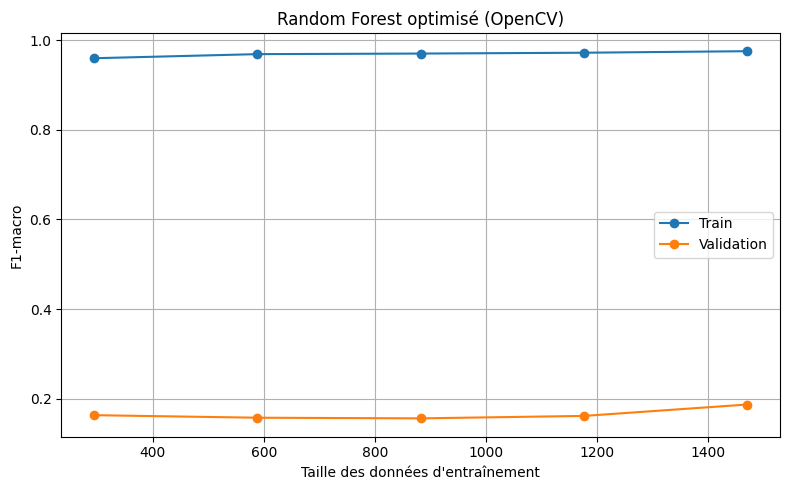

In [ ]:
from sklearn.model_selection import learning_curve, GroupKFold
import numpy as np
import matplotlib.pyplot as plt

tailles_rf, scores_train_rf, scores_val_rf = learning_curve(
    meilleur_rf,
    X_train_base,
    y_train_base,
    groups=film_train,
    cv=GroupKFold(n_splits=3),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1, 5),
    n_jobs=-1
)

plt.figure(figsize=(8, 5))

plt.plot(
    tailles_rf,
    scores_train_rf.mean(axis=1),
    marker="o",
    label="Train"
)

plt.plot(
    tailles_rf,
    scores_val_rf.mean(axis=1),
    marker="o",
    label="Validation"
)

plt.xlabel("Taille des données d'entraînement")
plt.ylabel("F1-macro")
plt.title("Random Forest optimisé (OpenCV)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

Le Random Forest présente un fort surapprentissage : il apprend très bien les données d'entraînement, mais obtient de faibles résultats en validation. Même en augmentant les données, les performances ne s'améliorent presque pas.

##OPENCV AVEC SVM

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import f1_score, classification_report, accuracy_score

svm = make_pipeline(
    StandardScaler(),
    SVC(class_weight="balanced", random_state=42)
)

svm.fit(X_train_base, y_train_base)
predictions_svm_opencv = svm.predict(X_dev_base)

print("Accuracy :", round(accuracy_score(y_dev_base, predictions_svm_opencv), 4))
print("F1-macro :", round(f1_score(y_dev_base, predictions_svm_opencv, average="macro"), 4))
print(classification_report(y_dev_base, predictions_svm_opencv, zero_division=0))

Accuracy : 0.2421
F1-macro : 0.2288
              precision    recall  f1-score   support

   amusement       0.11      0.20      0.14        35
       anger       0.36      0.21      0.27        98
         awe       0.13      0.10      0.11        40
 contentment       0.17      0.20      0.19        54
     disgust       0.12      0.14      0.13        43
  excitement       0.37      0.37      0.37        51
        fear       0.32      0.36      0.34        74
     sadness       0.31      0.26      0.28        47

    accuracy                           0.24       442
   macro avg       0.24      0.23      0.23       442
weighted avg       0.26      0.24      0.25       442



Le SVM avec les caractéristiques OpenCV obtient une accuracy de 24,21 % et un F1-macro de 0,2288.
Il reconnaît mieux excitement (F1 = 0,37) et fear (F1 = 0,34), mais reconnaît mal awe et disgust.

###Matrice de confusion SVM OPENCV

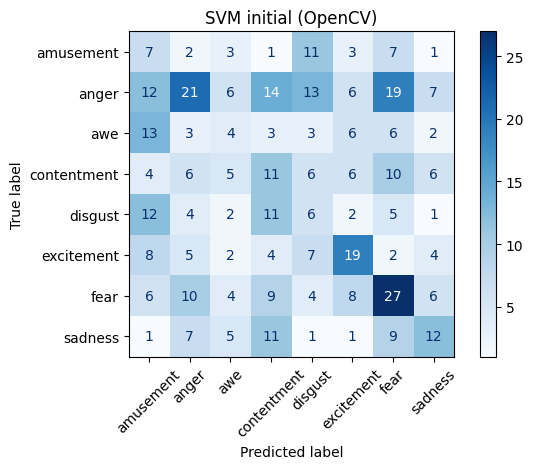

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matrice_svm_opencv= confusion_matrix(
    y_dev_base,
    predictions_svm_opencv,
    labels=svm.classes_
)

affichage_svm = ConfusionMatrixDisplay(
    confusion_matrix=matrice_svm_opencv,
    display_labels=svm.classes_
)

affichage_svm.plot(cmap="Blues", xticks_rotation=45)
plt.title("SVM initial (OpenCV)")
plt.tight_layout()
plt.show()

Le SVM initial reconnaît mieux fear (27 prédictions correctes) et excitement (19), mais confond souvent les émotions entre elles.
Il confond notamment amusement avec disgust (11 fois) et anger avec fear (19 fois)

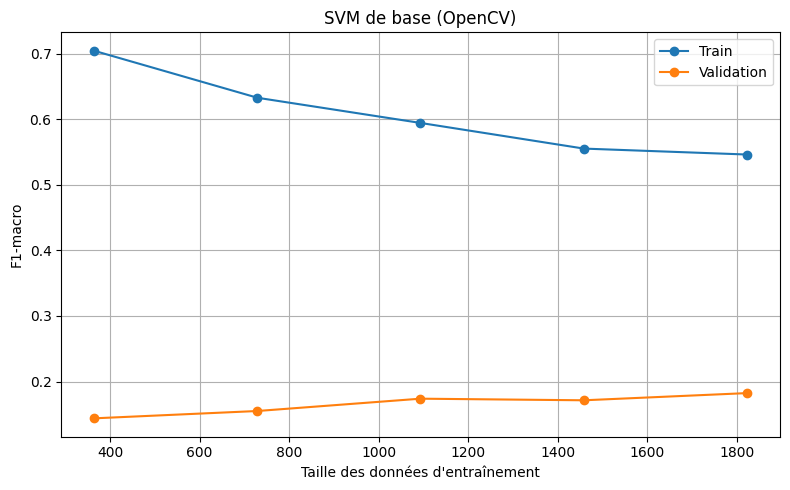

In [ ]:
from sklearn.model_selection import learning_curve, StratifiedGroupKFold
import numpy as np
import matplotlib.pyplot as plt

tailles_svm, scores_train_svm, scores_val_svm = learning_curve(
    svm,
    X_train_base,
    y_train_base,
    groups=film_train,
    cv=StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
    ),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1, 5),
    n_jobs=-1
)

plt.figure(figsize=(8, 5))

plt.plot(tailles_svm, scores_train_svm.mean(axis=1),
         marker="o", label="Train")

plt.plot(tailles_svm, scores_val_svm.mean(axis=1),
         marker="o", label="Validation")

plt.xlabel("Taille des données d'entraînement")
plt.ylabel("F1-macro")
plt.title("SVM de base (OpenCV)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

Le modèle s'améliore un peu lorsque la quantité de données augmente, mais l'écart entre les scores d'entraînement et de validation reste important.

##Trouver hyperparametrs pour SVM

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import f1_score, classification_report, accuracy_score

svm_base = make_pipeline(
    StandardScaler(),
    SVC(class_weight="balanced")
)

parametres_svm = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__kernel": ["linear", "rbf"],
    "svc__gamma": ["scale", 0.01, 0.1]
}

recherche_svm = GridSearchCV(
    svm_base,
    parametres_svm,
    scoring="f1_macro",
    cv=StratifiedGroupKFold(
       n_splits=5,
       shuffle=True,
       random_state=42
    ),
    n_jobs=-1
)

recherche_svm.fit(
    X_train_base,
    y_train_base,
    groups=film_train
)

meilleur_svm = recherche_svm.best_estimator_
predictions_svm_optimise = meilleur_svm.predict(X_dev_base)

print("Meilleurs paramètres :", recherche_svm.best_params_)
print("Meilleur F1-macro en validation croisée :", round(recherche_svm.best_score_, 4))
print("Accuracy :", round(accuracy_score(y_dev_base, predictions_svm_optimise), 4))
print("F1-macro :", round(f1_score(y_dev_base, predictions_svm_optimise, average="macro"), 4))

print("\nRapport par émotion :")
print(classification_report(
    y_dev_base,
    predictions_svm_optimise,
    zero_division=0
))

Le SVM optimisé obtient une accuracy de 22,40 % et un F1-macro de 0,21 sur dev, donc il prédit correctement environ 99 clips sur 442  
Il reconnaît mieux anger (F1 = 0,31) et fear (F1 = 0,30), mais distingue mal disgust (0,12) et sadness (0,15).


Matrice de confusion SVM optimisé

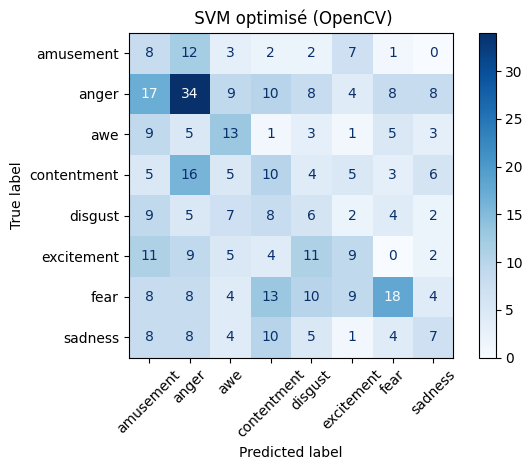

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matrice_svm_optimis_opencv = confusion_matrix(
    y_dev_base,
    predictions_svm_optimise,
    labels=meilleur_svm.classes_
)

affichage_svm_optimise = ConfusionMatrixDisplay(
    confusion_matrix=matrice_svm_optimis_opencv,
    display_labels=meilleur_svm.classes_
)

affichage_svm_optimise.plot(cmap="Blues", xticks_rotation=45)
plt.title(" SVM optimisé (OpenCV)")
plt.tight_layout()
plt.show()

Le SVM optimisé reconnaît mieux anger et fear, mais confond encore plusieurs émotions. Les résultats restent faibles pour certaines classes, notamment disgust et sadness.

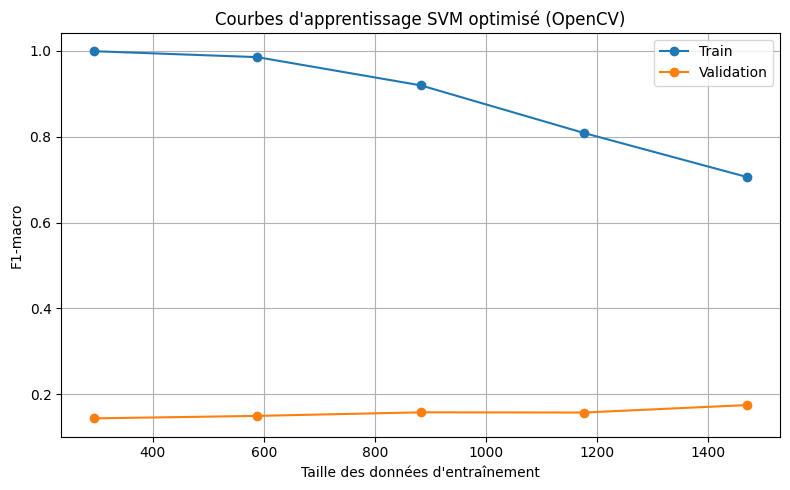

In [ ]:
from sklearn.model_selection import learning_curve, GroupKFold
import numpy as np
import matplotlib.pyplot as plt

tailles_svm, scores_train_svm, scores_val_svm = learning_curve(
    meilleur_svm,
    X_train_base,
    y_train_base,
    groups=film_train,
    cv=GroupKFold(n_splits=3),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1, 5),
    n_jobs=-1
)

plt.figure(figsize=(8, 5))

plt.plot(
    tailles_svm,
    scores_train_svm.mean(axis=1),
    marker="o",
    label="Train"
)

plt.plot(
    tailles_svm,
    scores_val_svm.mean(axis=1),
    marker="o",
    label="Validation"
)

plt.xlabel("Taille des données d'entraînement")
plt.ylabel("F1-macro")
plt.title("Courbes d'apprentissage SVM optimisé (OpenCV)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

La courbe d'entraînement diminue progressivement de 1,00 à environ 0,70 lorsque le nombre d'exemples augmente. En revanche, la courbe de validation augmente légèrement, passant d'environ 0,10 à 0,18, mais reste faible. L'écart entre les deux courbes montre que le SVM optimisé présente encore un surapprentissage et généralise difficilement à de nouveaux films.

## Cmpraison les 3 modeles

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import accuracy_score, f1_score

# Prédictions des trois modèles optimisés
pred_logistique = recherche.best_estimator_.predict(X_dev_base)
pred_rf = meilleur_rf.predict(X_dev_base)
pred_svm = meilleur_svm.predict(X_dev_base)

# Comparaison des performances sur Dev
comparaison_modeles = pd.DataFrame({
    "Modèle": [
        "Régression logistique optimisée",
        "Random Forest optimisé",
        "SVM optimisé"
    ],
    "F1-macro": [
        f1_score(y_dev_base, pred_logistique, average="macro"),
        f1_score(y_dev_base, pred_rf, average="macro"),
        f1_score(y_dev_base, pred_svm, average="macro")
    ],
    "Accuracy": [
        accuracy_score(y_dev_base, pred_logistique),
        accuracy_score(y_dev_base, pred_rf),
        accuracy_score(y_dev_base, pred_svm)
    ]
})

print("Comparaison des trois modèles optimisés :")
display(comparaison_modeles.round(4))

Comparaison des trois modèles optimisés :


,Modèle,F1-macro,Accuracy
0,Régression logistique optimisée,0.2011,0.2670
1,Random Forest optimisé,0.1980,0.2172
2,SVM optimisé,0.2224,0.2376


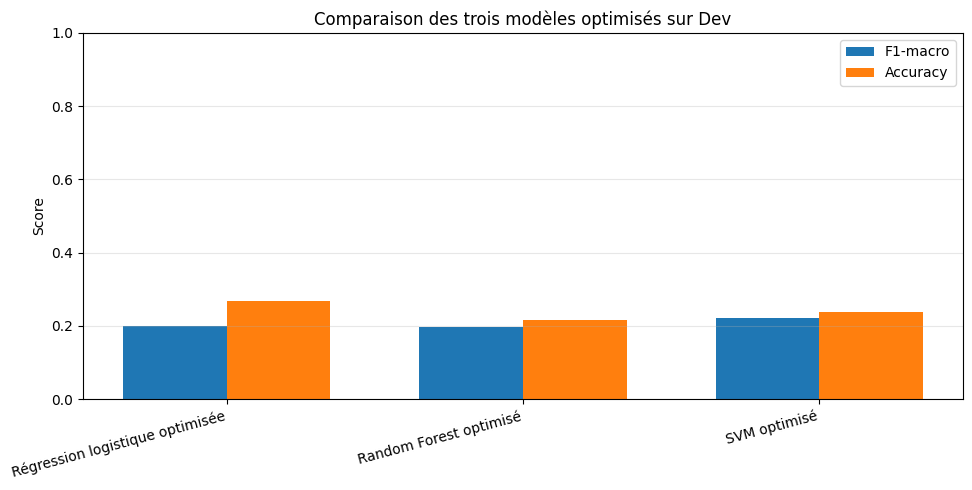

In [ ]:
plt.figure(figsize=(10, 5))

x = np.arange(len(comparaison_modeles))
largeur = 0.35

plt.bar(
    x - largeur/2,
    comparaison_modeles["F1-macro"],
    largeur,
    label="F1-macro"
)

plt.bar(
    x + largeur/2,
    comparaison_modeles["Accuracy"],
    largeur,
    label="Accuracy"
)

plt.xticks(x, comparaison_modeles["Modèle"], rotation=15, ha="right")
plt.ylabel("Score")
plt.title("Comparaison des trois modèles optimisés sur Dev")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Les trois modèles ont des résultats faibles et proches. La régression logistique obtient un résultat légèrement meilleur, mais les trois modèles ont du mal à reconnaître les huit émotions avec les caractéristiques OpenCV

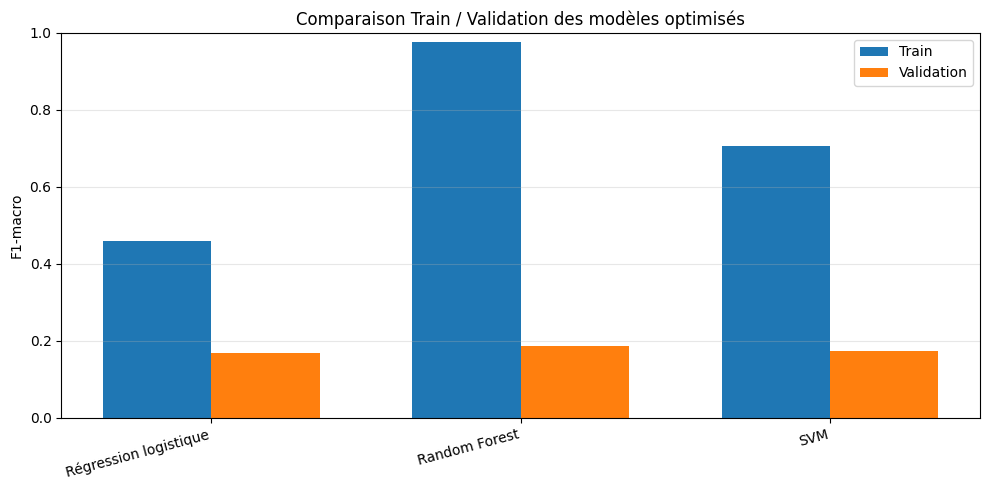

In [ ]:
scores_train_finaux = [
    scores_train.mean(axis=1)[-1],
    scores_train_rf.mean(axis=1)[-1],
    scores_train_svm.mean(axis=1)[-1]
]

scores_val_finaux = [
    scores_val.mean(axis=1)[-1],
    scores_val_rf.mean(axis=1)[-1],
    scores_val_svm.mean(axis=1)[-1]
]

modeles = [
    "Régression logistique",
    "Random Forest",
    "SVM"
]

x = np.arange(len(modeles))
largeur = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - largeur/2, scores_train_finaux, largeur, label="Train")
plt.bar(x + largeur/2, scores_val_finaux, largeur, label="Validation")

plt.xticks(x, modeles, rotation=15, ha="right")
plt.ylabel("F1-macro")
plt.title("Comparaison Train / Validation des modèles optimisés")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

La régression logistique présente un écart modéré, tandis que le Random Forest et le SVM montrent un surapprentissage important et une faible capacité de généralisation.

## Resume sur modeles teste sur caractéristiques OpenCV

Les trois modèles obtiennent des performances faibles, même après optimisation. Cela suggère que les caractéristiques OpenCV sont limitées pour représenter efficacement les huit émotions. De plus, la similarité entre certaines émotions et la variabilité entre les films rendent la classification plus difficile.


#**CLIP**

## Preparation donnees et extraction ...

In [ ]:
# !pip install -q transformers

In [ ]:
import transformers

print("Version de Transformers :", transformers.__version__)
print("Installation réussie !")

Version de Transformers : 5.22.0
Installation réussie !


In [ ]:
import torch

print(torch.__version__)
print(torch.cuda.is_available())

2.11.0+cpu
False


In [ ]:
!pip install torchview graphviz

### **Charger CLIP pré-entraîné**

In [ ]:
import torch
from transformers import CLIPModel, CLIPProcessor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#charger le modèle pré-entraîné et le processeur
nom_modele = "openai/clip-vit-base-patch32"
processor = CLIPProcessor.from_pretrained(nom_modele)
model = CLIPModel.from_pretrained(nom_modele)
# mettrr le modèle en mode évaluation
model = model.to(device)
model.eval()
print("Modèle CLIP chargé avec succès")
print("Appareil utilisé :", device)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Modèle CLIP chargé avec succès
Appareil utilisé : cpu


In [ ]:
print(model)

CLIPModel(
  (text_model): CLIPTextModel(
    (embeddings): CLIPTextEmbeddings(
      (token_embedding): Embedding(49408, 512)
      (position_embedding): Embedding(77, 512)
    )
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=512, out_features=512, bias=True)
            (v_proj): Linear(in_features=512, out_features=512, bias=True)
            (q_proj): Linear(in_features=512, out_features=512, bias=True)
            (out_proj): Linear(in_features=512, out_features=512, bias=True)
          )
          (layer_norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=512, out_features=2048, bias=True)
            (fc2): Linear(in_features=2048, out_features=512, bias=True)
          )
          (layer_norm2): LayerNorm((512,), eps=1e-05, eleme

In [ ]:
from pathlib import Path
import pandas as pd

dossier_features = Path("/content/data/features_baseline")

chemin_labels = dossier_features / "labels_partitions.csv"

print("Chemin :", chemin_labels)
print("Fichier présent :", chemin_labels.exists())

Chemin : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/features_baseline/labels_partitions.csv
Fichier présent : True


In [ ]:
from pathlib import Path
import pandas as pd
dossier_npy = Path("/content/data/extraction_complete/images_npy")
dossier_npy = Path(dossier_npy)   # str -> Path
dossier_features = Path(dossier_features)

chemin_labels = dossier_features / "labels_partitions.csv"
labels = pd.read_csv(chemin_labels, dtype=str)

videos_test = labels.head(20)["video_id"].tolist()

manquants = [v for v in videos_test if not (dossier_npy / f"{v}.npy").exists()]
print("Fichiers manquants :", manquants)
print("Nombre de vidéos sélectionnées :", len(videos_test))
print("Nombre de fichiers NPY présents :", len(videos_test) - len(manquants))
print("Premiers identifiants :", videos_test[:5])

Fichiers manquants : []
Nombre de vidéos sélectionnées : 20
Nombre de fichiers NPY présents : 20
Premiers identifiants : ['00000_clip_001', '00000_clip_002', '00000_clip_006', '00000_clip_009', '00000_clip_012']


**Tester CLIP sur une seule vidéo**

In [ ]:
video_id = videos_test[0]
chemin = dossier_npy / f"{video_id}.npy"
images = np.load(chemin)

image = images[0]
entrees = processor(
    images=image,
    return_tensors="pt"
)
model.eval()

with torch.inference_mode():
    entrees = {k: v.to(device) for k, v in entrees.items()}
    sortie = model.get_image_features(**entrees)
    embedding = sortie.pooler_output if hasattr(sortie, "pooler_output") else sortie

print("Vidéo test :", video_id)
print("Forme de l'embedding :", embedding.shape)
print("Valeurs numériques valides :", torch.isfinite(embedding).all().item())

Calculer embadding sur 8 images des 20 videos

In [ ]:
from tqdm.auto import tqdm

embeddings_test = []
ids_test = []
model.eval()
for video_id in tqdm(videos_test, desc="Test CLIP sur 20 vidéos"):
    chemin = dossier_npy / f"{video_id}.npy"
    images = np.load(chemin)

    entrees = processor(
        images=list(images),
        return_tensors="pt"
    )
    entrees = {k: v.to(device) for k, v in entrees.items()}

    with torch.inference_mode():
        sortie = model.get_image_features(**entrees)
        vecteurs = (
            sortie.pooler_output
            if hasattr(sortie, "pooler_output")
            else sortie
        )

    # Moyenne des 8 images : un vecteur de 512 valeurs par vidéo
    embedding_video = vecteurs.mean(dim=0)
    embeddings_test.append(embedding_video.cpu().numpy())
    ids_test.append(video_id)
X_test_clip = np.vstack(embeddings_test)

print("Nombre de vidéos :", len(ids_test))
print("Forme de la matrice :", X_test_clip.shape)
print("Valeurs numériques valides :", np.isfinite(X_test_clip).all())
print("Première vidéo :", ids_test[0])

Vérifier une image et la sortie CLIP

In [ ]:
video_id = videos_test[0]
images = np.load(dossier_npy / f"{video_id}.npy")

print("Forme des images :", images.shape)
print("Type :", images.dtype)
print("Minimum :", images.min())
print("Maximum :", images.max())

entrees = processor(images=list(images), return_tensors="pt")
entrees = {k: v.to(device) for k, v in entrees.items()}

model.eval()
with torch.inference_mode():
    sortie = model.get_image_features(**entrees)

vecteurs = (
    sortie.pooler_output
    if hasattr(sortie, "pooler_output")
    else sortie
)

print("Type de sortie CLIP :", type(sortie))
print("Forme de la sortie :", vecteurs.shape)

In [ ]:
#la moyenne et l'écart-type des 8 vecteurs CLIP

vecteurs_np = vecteurs.cpu().numpy()
moyenne = vecteurs_np.mean(axis=0)
ecart_type = vecteurs_np.std(axis=0)
embedding_video = np.concatenate([moyenne, ecart_type])
print("Nombre de vecteurs d'images :", vecteurs_np.shape)
print("Forme de la moyenne :", moyenne.shape)
print("Forme de l'écart-type :", ecart_type.shape)
print("Forme finale de la vidéo :", embedding_video.shape)
print("Valeurs finies :", np.isfinite(embedding_video).all())

chaque vidéo sera représentée par 1 024 caractéristiques CLIP, calculées à partir de ses 8 images.

In [ ]:
ids_videos = pd.read_csv(dossier_features / "labels_partitions.csv",dtype=str)["video_id"].tolist()
print("Nombre de vidéos :", len(ids_videos))
print("Exemple :", ids_videos[0])

Nombre de vidéos : 3088
Exemple : 00000_clip_001


In [ ]:
import numpy as np
import torch
from pathlib import Path

dossier_lots = dossier_features / "clip_batches"
dossier_lots.mkdir(parents=True, exist_ok=True)

ids_test = ids_videos[:3]
embeddings_test = []

model.eval()

for video_id in ids_test:
    chemin = dossier_npy / f"{video_id}.npy"
    images = np.load(chemin)

    # verification des 8 images RGB
    assert images.shape == (8, 224, 398, 3), (
        f"Forme inattendue pour {video_id}: {images.shape}"
    )
    assert images.dtype == np.uint8
    assert images.min() >= 0 and images.max() <= 255

    entrees = processor(images=list(images), return_tensors="pt")
    entrees = {k: v.to(device) for k, v in entrees.items()}

    with torch.inference_mode():
        sortie = model.get_image_features(**entrees)
        vecteurs = (
            sortie.pooler_output
            if hasattr(sortie, "pooler_output")
            else sortie
        )

    vecteurs_np = vecteurs.cpu().numpy()
    moyenne = vecteurs_np.mean(axis=0)
    ecart_type = vecteurs_np.std(axis=0)
    embedding = np.concatenate([moyenne, ecart_type]).astype(np.float32)
    assert embedding.shape == (1024,)
    assert np.isfinite(embedding).all()
    embeddings_test.append(embedding)
    print(f"{video_id} : OK — {embedding.shape}")

#sauvegarde du lot de test dans un fichier distinct
fichier_test = dossier_lots / "clip_test_3_videos.npz"
np.savez_compressed(
    fichier_test,
    ids=np.array(ids_test, dtype=str),
    embeddings=np.stack(embeddings_test)
)

#vérifier que le fichier est lisible
with np.load(fichier_test) as donnees:
    print("\nForme des embeddings sauvegardés :", donnees["embeddings"].shape)
    print("Identifiants sauvegardés :", donnees["ids"].tolist())

print("Fichier créé :", fichier_test)

00000_clip_001 : OK — (1024,)
00000_clip_002 : OK — (1024,)
00000_clip_006 : OK — (1024,)

Forme des embeddings sauvegardés : (3, 1024)
Identifiants sauvegardés : ['00000_clip_001', '00000_clip_002', '00000_clip_006']
Fichier créé : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/features_baseline/clip_batches/clip_test_3_videos.npz


#### extraire les caractéristiques CLIP des 3 088 vidéos

In [ ]:
import numpy as np
import torch
import os
from tqdm.auto import tqdm

#dossier de sauvegarde des lots
dossier_lots = dossier_features / "clip_batches"
dossier_lots.mkdir(parents=True, exist_ok=True)

TAILLE_LOT = 50
total_lots = (len(ids_videos) + TAILLE_LOT - 1) // TAILLE_LOT

model.eval()

for numero_lot in range(total_lots):
    debut = numero_lot * TAILLE_LOT
    fin = min(debut + TAILLE_LOT, len(ids_videos))
    ids_lot = ids_videos[debut:fin]

    fichier_lot = dossier_lots / f"clip_batch_{numero_lot:04d}.npz"

    # pour ne pas recalculer un lot déjà sauvegardé
    if fichier_lot.exists():
        print(f"Lot {numero_lot + 1}/{total_lots} déjà sauvegardé : ignoré.")
        continue

    embeddings_lot = []
    ids_ok = []
    erreurs_lot = []

    for video_id in tqdm(
    ids_lot,
    desc=f"Lot {numero_lot + 1}/{total_lots}",
    leave=False
    ):
        try:
            chemin = dossier_npy / f"{video_id}.npy"
            images = np.load(chemin)

            if images.shape != (8, 224, 398, 3):
                raise ValueError(f"Forme inattendue : {images.shape}")

            if images.dtype != np.uint8:
                raise ValueError(f"Type inattendu : {images.dtype}")

            entrees = processor(
                images=list(images),
                return_tensors="pt"
            )
            entrees = {k: v.to(device) for k, v in entrees.items()}

            with torch.inference_mode():
                sortie = model.get_image_features(**entrees)
                vecteurs = (
                    sortie.pooler_output
                    if hasattr(sortie, "pooler_output")
                    else sortie
                )

            vecteurs_np = vecteurs.cpu().numpy()
            moyenne = vecteurs_np.mean(axis=0)
            ecart_type = vecteurs_np.std(axis=0)
            embedding = np.concatenate(
                [moyenne, ecart_type]
            ).astype(np.float32)

            if embedding.shape != (1024,):
                raise ValueError(f"Dimension inattendue : {embedding.shape}")

            if not np.isfinite(embedding).all():
                raise ValueError("Valeurs non finies dans l'embedding")

            embeddings_lot.append(embedding)
            ids_ok.append(video_id)

        except Exception as e:
            erreurs_lot.append((video_id, str(e)[:300]))
            print(f"\nErreur pour {video_id} : {e}")

    #sauvegarde temporaire, puis renommer pour éviter un lot partiel
    fichier_temp = dossier_lots / f"clip_batch_{numero_lot:04d}.tmp"

    with open(fichier_temp, "wb") as f:
        np.savez_compressed(
            f,
            ids=np.array(ids_ok, dtype=str),
            embeddings=np.asarray(
                embeddings_lot, dtype=np.float32
            ).reshape(-1, 1024),
            erreurs_ids=np.array(
                [e[0] for e in erreurs_lot], dtype=str
            ),
            erreurs_messages=np.array(
                [e[1] for e in erreurs_lot], dtype=str
            )
        )

    os.replace(fichier_temp, fichier_lot)

    print(f"Lot {numero_lot + 1}/{total_lots} terminé : "f"{len(ids_ok)} réussies, {len(erreurs_lot)} erreurs.")
print("\nExtraction terminée ou lots déjà sauvegardés.")

Lot 1/62 déjà sauvegardé : ignoré.
Lot 2/62 déjà sauvegardé : ignoré.
Lot 3/62 déjà sauvegardé : ignoré.
Lot 4/62 déjà sauvegardé : ignoré.
Lot 5/62 déjà sauvegardé : ignoré.
Lot 6/62 déjà sauvegardé : ignoré.
Lot 7/62 déjà sauvegardé : ignoré.
Lot 8/62 déjà sauvegardé : ignoré.
Lot 9/62 déjà sauvegardé : ignoré.
Lot 10/62 déjà sauvegardé : ignoré.
Lot 11/62 déjà sauvegardé : ignoré.
Lot 12/62 déjà sauvegardé : ignoré.
Lot 13/62 déjà sauvegardé : ignoré.
Lot 14/62 déjà sauvegardé : ignoré.
Lot 15/62 déjà sauvegardé : ignoré.
Lot 16/62 déjà sauvegardé : ignoré.
Lot 17/62 déjà sauvegardé : ignoré.
Lot 18/62 déjà sauvegardé : ignoré.
Lot 19/62 déjà sauvegardé : ignoré.
Lot 20/62 déjà sauvegardé : ignoré.
Lot 21/62 déjà sauvegardé : ignoré.
Lot 22/62 déjà sauvegardé : ignoré.
Lot 23/62 déjà sauvegardé : ignoré.
Lot 24/62 déjà sauvegardé : ignoré.
Lot 25/62 déjà sauvegardé : ignoré.
Lot 26/62 déjà sauvegardé : ignoré.
Lot 27/62 déjà sauvegardé : ignoré.
Lot 28/62 déjà sauvegardé : ignoré.
L

In [ ]:
from pathlib import Path
import numpy as np

dossier_lots = dossier_features / "clip_batches"
fichiers_lots = sorted(dossier_lots.glob("clip_batch_*.npz"))

print("Nombre de lots trouvés :", len(fichiers_lots))

total_videos = 0
dimensions = {}
erreurs_total = 0
problemes = []

for fichier in fichiers_lots:
    try:
        with np.load(fichier, allow_pickle=False) as donnees:
            ids = donnees["ids"]
            embeddings = donnees["embeddings"]

            forme = embeddings.shape
            dimensions[forme[1] if embeddings.ndim == 2 else "invalide"] = (
                dimensions.get(
                    forme[1] if embeddings.ndim == 2 else "invalide", 0
                ) + 1
            )

            if embeddings.shape != (len(ids), 1024):
                problemes.append(
                    f"{fichier.name} : forme {forme}, IDs {len(ids)}"
                )

            if not np.isfinite(embeddings).all():
                problemes.append(f"{fichier.name} : valeurs non finies")

            total_videos += len(ids)

            if "erreurs_ids" in donnees.files:
                erreurs_total += len(donnees["erreurs_ids"])

    except Exception as e:
        problemes.append(f"{fichier.name} : {e}")

print("Nombre total de vidéos enregistrées :", total_videos)
print("Dimensions des embeddings :", dimensions)
print("Nombre d'erreurs enregistrées :", erreurs_total)
print("Problèmes détectés :", problemes[:10])
print("Nombre de problèmes :", len(problemes))

Nombre de lots trouvés : 62
Nombre total de vidéos enregistrées : 3084
Dimensions des embeddings : {1024: 62}
Nombre d'erreurs enregistrées : 4
Problèmes détectés : []
Nombre de problèmes : 0


In [ ]:
import numpy as np

ids_enregistres = []
for fichier in fichiers_lots:
    with np.load(fichier, allow_pickle=False) as donnees:
        ids_enregistres.extend(donnees["ids"].tolist())

ids_enregistres_set = set(ids_enregistres)
ids_attendus_set = set(ids_videos)

ids_manquants = sorted(ids_attendus_set - ids_enregistres_set)
ids_inconnus = sorted(ids_enregistres_set - ids_attendus_set)

print("Vidéos manquantes :", len(ids_manquants))
print(ids_manquants)

print("\nIdentifiants inattendus :", len(ids_inconnus))
print(ids_inconnus[:10])

print("\nIdentifiants en double :", len(ids_enregistres) - len(ids_enregistres_set))

Vidéos manquantes : 4
['00178_clip_004', '00178_clip_017', '00178_clip_018', '00178_clip_022']

Identifiants inattendus : 0
[]

Identifiants en double : 0


In [ ]:
import numpy as np
import torch
from pathlib import Path

embeddings_recuperes = []
ids_recuperes = []
erreurs_recuperation = []

model.eval()

for video_id in ids_manquants:
    chemin = dossier_npy / f"{video_id}.npy"

    try:
        images = np.load(chemin)

        entrees = processor(
            images=[img for img in images],
            return_tensors="pt"
        )
        entrees = {k: v.to(device) for k, v in entrees.items()}

        # Extraire les embeddings CLIP
        with torch.no_grad():
            sortie = model.get_image_features(**entrees)

            if hasattr(sortie, "pooler_output"):
                features = sortie.pooler_output
            else:
                features = sortie

        features = features.cpu().numpy()
        embedding = np.concatenate([
            features.mean(axis=0),
            features.std(axis=0)
        ]).astype(np.float32)

        embeddings_recuperes.append(embedding)
        ids_recuperes.append(video_id)

        print(f"OK : {video_id} — forme {embedding.shape}")

    except Exception as e:
        erreurs_recuperation.append((video_id, repr(e)))
        print(f"ERREUR : {video_id} — {repr(e)}")

# Sauvegarder séparément les résultats récupérés
fichier_recuperation = dossier_features / "clip_videos_recuperees.npz"

np.savez_compressed(
    fichier_recuperation,
    ids=np.array(ids_recuperes),
    embeddings=np.array(embeddings_recuperes, dtype=np.float32),
    erreurs_ids=np.array([e[0] for e in erreurs_recuperation]),
    erreurs_messages=np.array([e[1] for e in erreurs_recuperation])
)

print("Vidéos récupérées :", len(ids_recuperes))
print("Vidéos encore en erreur :", len(erreurs_recuperation))
print("Fichier sauvegardé :", fichier_recuperation)

OK : 00178_clip_004 — forme (1024,)
OK : 00178_clip_017 — forme (1024,)
OK : 00178_clip_018 — forme (1024,)
OK : 00178_clip_022 — forme (1024,)
Vidéos récupérées : 4
Vidéos encore en erreur : 0
Fichier sauvegardé : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/features_baseline/clip_videos_recuperees.npz


In [ ]:
ids_tous = []

for fichier in sorted(dossier_lots.glob("clip_batch_*.npz")):
    data = np.load(fichier)
    ids_tous.extend(data["ids"].tolist())

#ajouter les 4 vidéos récupérées
data = np.load(fichier_recuperation)
ids_tous.extend(data["ids"].tolist())

# verfier les résultats
print("Nombre total :", len(ids_tous))
print("Nombre sans doublons :", len(set(ids_tous)))
print("Vidéos manquantes :", len(set(ids_videos) - set(ids_tous)))
print("Doublons :", len(ids_tous) - len(set(ids_tous)))

Nombre total : 3088
Nombre sans doublons : 3088
Vidéos manquantes : 0
Doublons : 0


In [ ]:
#regrouper les embeddings
embeddings_tous = []
ids_tous = []

for fichier in sorted(dossier_lots.glob("clip_batch_*.npz")):
    data = np.load(fichier)
    ids_tous.extend(data["ids"].tolist())
    embeddings_tous.extend(data["embeddings"])

#ajouter les 4 vidéos récupérées
data = np.load(fichier_recuperation)
ids_tous.extend(data["ids"].tolist())
embeddings_tous.extend(data["embeddings"])

#créer la matrice finale
X_video = np.array(embeddings_tous)

print("Forme de la matrice :", X_video.shape)
print("Nombre de vidéos :", len(ids_tous))

Forme de la matrice : (3088, 1024)
Nombre de vidéos : 3088


###Fusion des embeddings CLIP avec les labels et les partitions (train/dev/test).

In [ ]:
#créer le tableau des embeddings
df_embeddings = pd.DataFrame(X_video)
df_embeddings.insert(0, "video_id", ids_tous)

#ajouter les partitions et les émotions
df_embeddings = df_embeddings.merge(
    labels,
    on="video_id",
    how="left"
)

print(df_embeddings.shape)
print(df_embeddings["split"].value_counts())
print("Valeurs manquantes :", df_embeddings["split"].isna().sum())

(3088, 1028)
split
train    2207
dev       442
test      439
Name: count, dtype: int64
Valeurs manquantes : 0


In [ ]:
#séparer les données
train = df_embeddings[df_embeddings["split"] == "train"]
dev = df_embeddings[df_embeddings["split"] == "dev"]
test = df_embeddings[df_embeddings["split"] == "test"]

print("Train :", train.shape)
print("Dev :", dev.shape)
print("Test :", test.shape)

Train : (2207, 1028)
Dev : (442, 1028)
Test : (439, 1028)


Séparation des caractéristiques visuelles CLIP (X) et des labels émotionnels (y)

In [ ]:
#1024 caractéristiques CLIP
X_train = train.iloc[:, 1:1025].values
X_dev = dev.iloc[:, 1:1025].values
X_test = test.iloc[:, 1:1025].values

#émotions
y_train = train["emotion"].values
y_dev = dev["emotion"].values
y_test = test["emotion"].values

print("X_train :", X_train.shape)
print("X_dev :", X_dev.shape)
print("X_test :", X_test.shape)

print("Nombre d'émotions train :", len(y_train))
print("Nombre d'émotions dev :", len(y_dev))
print("Nombre d'émotions test :", len(y_test))

X_train : (2207, 1024)
X_dev : (442, 1024)
X_test : (439, 1024)
Nombre d'émotions train : 2207
Nombre d'émotions dev : 442
Nombre d'émotions test : 439


In [ ]:
#sauvegarder les embeddings CLIP mean + std
np.save(dossier_features / "X_video_meanstd.npy",X_video)
print("Matrice sauvegardée :", X_video.shape)
print("Fichier créé :", (dossier_features / "X_video_meanstd.npy").exists())

Matrice sauvegardée : (3088, 1024)
Fichier créé : True


In [ ]:
# Vérifier les fichiers finaux
print("X_video.npy :", (dossier_features / "X_video.npy").exists())
print("X_video_meanstd.npy :", (dossier_features / "X_video_meanstd.npy").exists())

X_video.npy : False
X_video_meanstd.npy : True


In [ ]:
X_verification = np.load(dossier_features / "X_video_meanstd.npy")
print("Forme :", X_verification.shape)
print("Valeurs valides :", np.isfinite(X_verification).all())

Forme : (3088, 1024)
Valeurs valides : True


In [ ]:
import pandas as pd
import numpy as np

#identifiants associés aux labels
fichier_ids = dossier_features / "labels_partitions.csv"
ids_existants = pd.read_csv(fichier_ids, dtype=str)["video_id"].tolist()

#vérifier si les identifiants des embeddings sont enregistrés dans un fichier
print("Nombre d'identifiants des labels :", len(ids_existants))
print("Fichiers présents dans le dossier des lots :")
print([f.name for f in dossier_lots.glob("*")])

Nombre d'identifiants des labels : 3088
Fichiers présents dans le dossier des lots :
['clip_batch_0000.npz', 'clip_batch_0001.npz', 'clip_batch_0002.npz', 'clip_batch_0003.npz', 'clip_batch_0004.npz', 'clip_batch_0005.npz', 'clip_batch_0006.npz', 'clip_batch_0007.npz', 'clip_batch_0008.npz', 'clip_batch_0009.npz', 'clip_batch_0010.npz', 'clip_batch_0011.npz', 'clip_batch_0012.npz', 'clip_batch_0013.npz', 'clip_batch_0014.npz', 'clip_batch_0015.npz', 'clip_batch_0016.npz', 'clip_batch_0017.npz', 'clip_batch_0018.npz', 'clip_batch_0019.npz', 'clip_batch_0020.npz', 'clip_batch_0021.npz', 'clip_batch_0022.npz', 'clip_batch_0023.npz', 'clip_batch_0024.npz', 'clip_batch_0025.npz', 'clip_batch_0026.npz', 'clip_batch_0027.npz', 'clip_batch_0028.npz', 'clip_batch_0029.npz', 'clip_batch_0030.npz', 'clip_batch_0031.npz', 'clip_batch_0032.npz', 'clip_batch_0033.npz', 'clip_batch_0034.npz', 'clip_batch_0035.npz', 'clip_batch_0036.npz', 'clip_batch_0037.npz', 'clip_batch_0038.npz', 'clip_batch_0039.

In [ ]:
set_ids_fichier = set(ids_existants)
set_ids_embeddings = set(ids_tous)

print("Identifiants communs :",
      len(set_ids_fichier & set_ids_embeddings))

print("Présents dans ids_video.csv mais pas dans X_video :",
      len(set_ids_fichier - set_ids_embeddings))

print("Présents dans X_video mais pas dans ids_video.csv :",
      len(set_ids_embeddings - set_ids_fichier))

print("\nPremiers identifiants du fichier :")
print(ids_existants[:5])

print("\nPremiers identifiants des embeddings :")
print(ids_tous[:5])


Identifiants communs : 3088
Présents dans ids_video.csv mais pas dans X_video : 0
Présents dans X_video mais pas dans ids_video.csv : 0

Premiers identifiants du fichier :
['00000_clip_001', '00000_clip_002', '00000_clip_006', '00000_clip_009', '00000_clip_012']

Premiers identifiants des embeddings :
['00000_clip_001', '00000_clip_002', '00000_clip_006', '00000_clip_009', '00000_clip_012']


In [ ]:
print(X_video)

[[-0.3050432  -0.16321982 -0.2535804  ...  0.23112166  0.11504311
   0.08435814]
 [-0.29310793 -0.18010154 -0.26283422 ...  0.11768706  0.08409163
   0.08388446]
 [-0.45457697 -0.19624984 -0.09841322 ...  0.11983655  0.07131317
   0.01930068]
 ...
 [-0.14137217 -0.28972012 -0.24522868 ...  0.13676372  0.11840402
   0.15022627]
 [-0.16157803 -0.36403942 -0.18142883 ...  0.08702141  0.12703173
   0.09881763]
 [-0.13727883 -0.0007484  -0.07703582 ...  0.08652769  0.14427726
   0.08185373]]


In [ ]:
#les embeddings dans l'ordre de ids_video.csv
positions = [ids_tous.index(id) for id in ids_existants]
X_video = X_video[positions]
ids_tous = ids_existants.copy()

print("Dimensions :", X_video.shape)
print("Ordre correct :", ids_tous == ids_existants)

Dimensions : (3088, 1024)
Ordre correct : True


In [ ]:
#recréer le tableau avec les bons identifiants
df_embeddings = pd.DataFrame(X_video)
df_embeddings.insert(0, "video_id", ids_tous)
df_embeddings = df_embeddings.merge(labels, on="video_id", how="left")

print("Nombre de vidéos :", len(df_embeddings))
print("Identifiants uniques :", df_embeddings["video_id"].is_unique)
print("Valeurs manquantes :", df_embeddings[["emotion", "split", "film_id"]].isna().sum().sum())
print("\nPartitions :")
print(df_embeddings["split"].value_counts())

Nombre de vidéos : 3088
Identifiants uniques : True
Valeurs manquantes : 0

Partitions :
split
train    2207
dev       442
test      439
Name: count, dtype: int64


Enregistrer la matrice des embeddings dans le bon ordre

In [ ]:
np.save(dossier_features / "X_video_meanstd.npy", X_video)
print("Matrice enregistrée :", X_video.shape)

Matrice enregistrée : (3088, 1024)


Vérification les deux fichiers embedding et ids videos

In [ ]:
fichier_ids = dossier_features.parent.parent / "ids_video.csv"
fichier_embeddings = dossier_features / "X_video_meanstd.npy"

print("Fichier des identifiants :", fichier_ids.exists())
print("Fichier des embeddings :", fichier_embeddings.exists())

ids = pd.read_csv(fichier_ids)["video_id"]
X = np.load(fichier_embeddings)

print("Nombre d'identifiants :", len(ids))
print("Dimensions des embeddings :", X.shape)
print("Même nombre de lignes :", len(ids) == X.shape[0])

Fichier des identifiants : True
Fichier des embeddings : True
Nombre d'identifiants : 3088
Dimensions des embeddings : (3088, 1024)
Même nombre de lignes : True


In [ ]:
#separer les vidéos d'entraînement et de validation
train = df_embeddings[df_embeddings["split"] == "train"]
dev = df_embeddings[df_embeddings["split"] == "dev"]

#récupérer les 1024 caractéristiques CLIP
X_train = train.iloc[:, 1:1025].values
X_dev = dev.iloc[:, 1:1025].values
y_train = train["emotion"].values
y_dev = dev["emotion"].values

print("X_train :", X_train.shape)
print("X_dev   :", X_dev.shape)
print("y_train :", y_train.shape)
print("y_dev   :", y_dev.shape)
print("Émotions :", sorted(set(y_train)))

X_train : (2207, 1024)
X_dev   : (442, 1024)
y_train : (2207,)
y_dev   : (442,)
Émotions : ['amusement', 'anger', 'awe', 'contentment', 'disgust', 'excitement', 'fear', 'sadness']


## Entraîner le premier classifieur : Regression logistqiue

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline

modele_clip_log = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, C=1)
)

modele_clip_log.fit(X_train, y_train)
predictions_clip_log = modele_clip_log.predict(X_dev)

print("Accuracy :", round(accuracy_score(y_dev, predictions_clip_log), 4))
print("F1-macro :", round(f1_score(y_dev, predictions_clip_log, average="macro"), 4))

Accuracy : 0.3394
F1-macro : 0.3387


La régression logistique avec CLIP obtient une accuracy de 33,94 % et un F1-macro de 0,3387.
Ces résultats sont meilleurs que ceux des modèles OpenCV testés jusqu’ici.

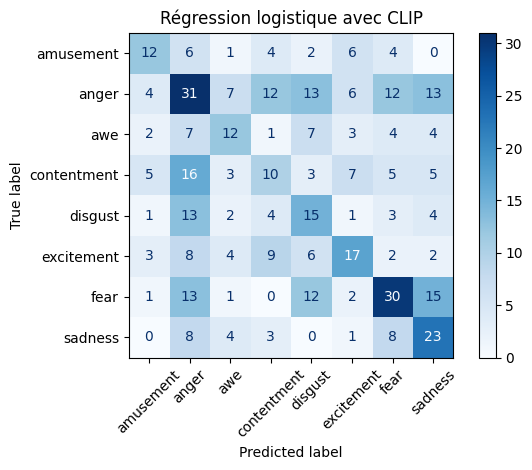

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matrice_clip_log = confusion_matrix(
    y_dev,
    predictions_clip_log,
    labels=modele_clip_log.classes_
)

affichage_clip_log = ConfusionMatrixDisplay(
    confusion_matrix=matrice_clip_log,
    display_labels=modele_clip_log.classes_
)

affichage_clip_log.plot(cmap="Blues", xticks_rotation=45)
plt.title("Régression logistique avec CLIP")
plt.tight_layout()
plt.show()

In [ ]:
film_train = (df_videos[df_videos["split"] == "train"]["dossier"].values)
print("Nombre de vidéos :", len(film_train))
print("Nombre de films :", len(np.unique(film_train)))

Nombre de vidéos : 2207
Nombre de films : 250


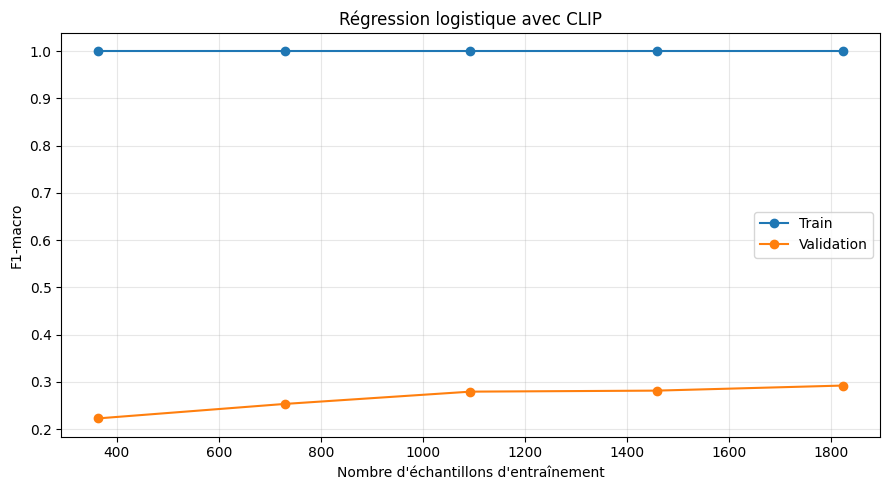

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedGroupKFold

# Calcul de la courbe d'apprentissage
tailles, scores_train_clip, scores_val_clip = learning_curve(
    modele_clip_log,
    X_train,
    y_train,
    groups=film_train,
    cv=StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

# Calcul des moyennes
moyenne_train_clip = scores_train_clip.mean(axis=1)
moyenne_val_clip = scores_val_clip.mean(axis=1)

# Affichage
plt.figure(figsize=(9, 5))

plt.plot(tailles, moyenne_train_clip, marker="o", label="Train")
plt.plot(tailles, moyenne_val_clip, marker="o", label="Validation")

plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("F1-macro")
plt.title("Régression logistique avec CLIP")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La régression logistique avec CLIP présente un surapprentissage important, avec un score F1-macro d'entraînement proche de 1,0. Cependant, le score de validation progresse d'environ 0,20 à 0,30 lorsque la taille des données augmente, ce qui montre une meilleure capacité de généralisation que les modèles basés sur les caractéristiques OpenCV.

##Régression logistique avec CLIP et équilibrage des classes

In [ ]:
modele_clip_bal = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        C=1,
        class_weight="balanced"
    )
)

modele_clip_bal.fit(X_train, y_train)
predictions_clip_bal = modele_clip_bal.predict(X_dev)

print("Accuracy :", round(accuracy_score(y_dev, predictions_clip_bal), 4))
print("F1-macro :", round(f1_score(y_dev, predictions_clip_bal, average="macro"), 4))

Accuracy : 0.3484
F1-macro : 0.3488


Le modèle obtient une accuracy de 34,84 % et un F1-macro de 0,3488.
Il améliore légèrement le modèle précédent, dont le F1-macro était de 0,3387.
La pondération des classes semble donc utile

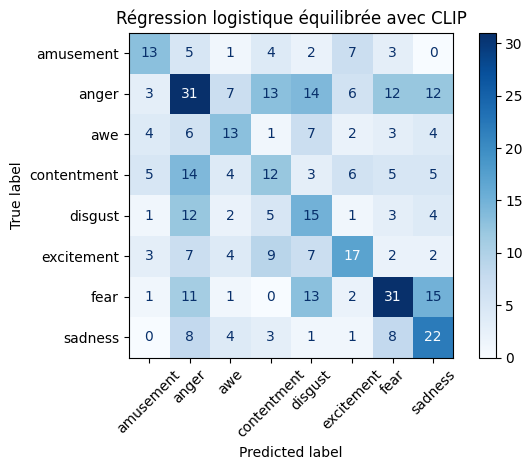

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matrice_clip_bal = confusion_matrix(
    y_dev,
    predictions_clip_bal,
    labels=modele_clip_bal.classes_
)

affichage_clip_bal = ConfusionMatrixDisplay(
    confusion_matrix=matrice_clip_bal,
    display_labels=modele_clip_bal.classes_
)

affichage_clip_bal.plot(cmap="Blues", xticks_rotation=45)
plt.title("Régression logistique équilibrée avec CLIP")
plt.tight_layout()
plt.show()

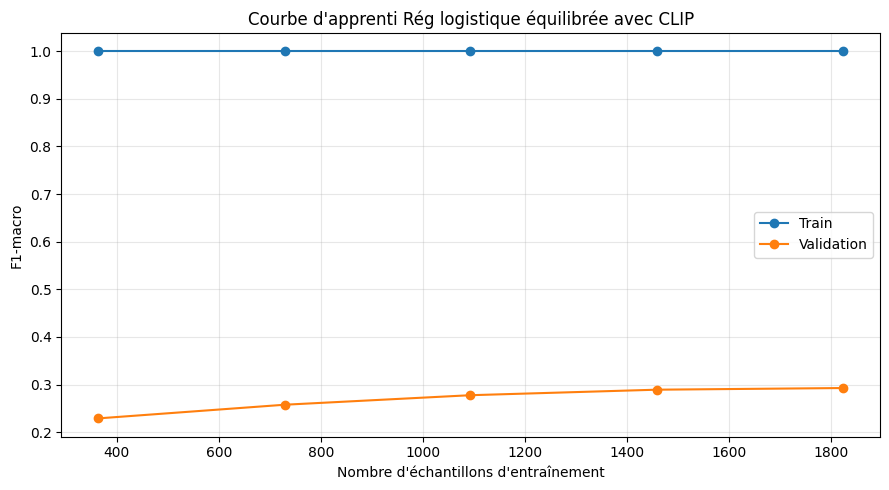

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedGroupKFold

tailles, scores_train_clip_bal, scores_val_clip_bal = learning_curve(
    modele_clip_bal,
    X_train,
    y_train,
    groups=film_train,
    cv=StratifiedGroupKFold(
       n_splits=5,
       shuffle=True,
       random_state=42
    ),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

moyenne_train_clip_bal = scores_train_clip_bal.mean(axis=1)
moyenne_val_clip_bal = scores_val_clip_bal.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(tailles, moyenne_train_clip_bal, marker="o", label="Train")
plt.plot(tailles, moyenne_val_clip_bal, marker="o", label="Validation")

plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("F1-macro")
plt.title("Courbe d'apprenti Rég logistique équilibrée avec CLIP")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La courbe montre un surapprentissage important : le score d'entraînement reste à 1,0, tandis que celui de validation est plus faible. Cependant, le F1-macro de validation progresse de 0,20 à 0,30

##Recherche des hyperparamètres de la régression logistique avec CLIP

In [ ]:
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, GroupKFold

modele_clip = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000)
)

parametres_clip = {
    "logisticregression__C": [0.0001, 0.001, 0.01, 0.1, 1],
    "logisticregression__class_weight": [None, "balanced"]
}

validation_clip = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

recherche_clip = GridSearchCV(
    estimator=modele_clip,
    param_grid=parametres_clip,
    scoring="f1_macro",
    cv=validation_clip,
    n_jobs=-1,
    verbose=1
)

recherche_clip.fit(
    X_train,
    y_train,
    groups=film_train
)

print("Meilleurs paramètres :", recherche_clip.best_params_)
print("Meilleur F1-macro en validation :",
      round(recherche_clip.best_score_, 4))

La meilleure combinaison est C = 0,001 avec class_weight="balanced", avec un F1-macro de 0,35

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

# Récupérer le meilleur modèle trouvé par GridSearchCV
modele_clip_reg_opt = recherche_clip.best_estimator_

# Prédire les émotions sur les données Dev
predictions_clip_reg_opt = modele_clip_reg_opt.predict(X_dev)

accuracy_clip_reg_opt = accuracy_score(y_dev, predictions_clip_reg_opt)
f1_clip_reg_opt = f1_score(y_dev, predictions_clip_reg_opt, average="macro")

print("Accuracy sur Dev :", round(accuracy_clip_reg_opt, 4))
print("F1-macro sur Dev :", round(f1_clip_reg_opt, 4))

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculer la matrice de confusion
matrice_clip_reg_opt = confusion_matrix(
    y_dev,
    predictions_clip_opt,
    labels=modele_clip_opt.classes_
)

# Afficher la matrice
affichage_clip_reg_opt = ConfusionMatrixDisplay(
    confusion_matrix=matrice_clip_reg_opt,
    display_labels=modele_clip_reg_opt.classes_
)

affichage_clip_reg_opt.plot(cmap="Blues", xticks_rotation=45)

plt.title("Matrice de confusion CLIP Reg optimisé")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, GroupKFold

tailles, scores_train_clip_reg_opt, scores_val_clip_reg_opt = learning_curve(
    modele_clip_reg_opt,
    X_train,
    y_train,
    groups=film_train,
    cv=StratifiedGroupKFold(
       n_splits=5,
       shuffle=True,
       random_state=42
    ),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

moyenne_train_clip_reg_opt = scores_train_clip_reg_opt.mean(axis=1)
moyenne_val_clip_reg_opt = scores_val_clip_reg_opt.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(tailles, moyenne_train_clip_reg_opt, marker="o", label="Train")
plt.plot(tailles, moyenne_val_clip_reg_opt, marker="o", label="Validation")

plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("F1-macro")
plt.title("Courbe d'apprentissage CLIP Reg optimisé")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La régression logistique optimisée avec CLIP réduit significativement le surapprentissage observé dans la version initiale. Le score F1-macro de validation atteint 0,35 tandis que le score d'entraînement se stabilise autour de 0,69. L'écart entre les deux courbes demeure présent mais est nettement moins marqué, indiquant une meilleure généralisation du modèle.

Pour info : CLIP 512 résume les informations visuelles moyennes, tandis que CLIP 1024 ajoute des informations sur leurs variations entre les images.

In [ ]:
import numpy as np

#érifier que les données sont chargées
print("Embeddings :", X_video.shape)
print("Labels :", labels.shape)

#séparer les données selon les partitions
X_train_512 = X_video[labels["split"].values == "train", :512]
X_dev_512 = X_video[labels["split"].values == "dev", :512]

y_train = labels.loc[labels["split"] == "train", "emotion"].values
y_dev = labels.loc[labels["split"] == "dev", "emotion"].values

print("X_train_512 :", X_train_512.shape)
print("X_dev_512 :", X_dev_512.shape)
print("y_train :", y_train.shape)
print("y_dev :", y_dev.shape)
print("X_test :", X_test.shape)


## Logistic Regression avec CLIP 512 et SAGA

In [ ]:
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

modele_clip512_saga = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        solver="saga",
        max_iter=5000,
        random_state=42
    )
)

parametres_clip512_saga = {
    "logisticregression__C": [0.001, 0.003, 0.01, 0.03],
    "logisticregression__class_weight": ["balanced"]
}

recherche_clip512_saga = GridSearchCV(
    estimator=modele_clip512_saga,
    param_grid=parametres_clip512_saga,
    scoring="f1_macro",
    cv=StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
  ),
    n_jobs=-1,
    verbose=1
)

recherche_clip512_saga.fit(
    X_train_512,
    y_train,
    groups=film_train
)

# print("Meilleurs paramètres :", recherche_clip512_saga.best_params_)
# print("Meilleur F1-macro en validation :", round(recherche_clip512_saga.best_score_, 4))

In [ ]:
modele_clip512_saga_final = recherche_clip512_saga.best_estimator_

predictions_clip512_saga = modele_clip512_saga_final.predict(X_dev_512)

print("Accuracy :", round(accuracy_score(y_dev, predictions_clip512_saga), 4))
print("F1-macro :", round(f1_score(y_dev, predictions_clip512_saga, average="macro"), 4))

Le modèle CLIP 512 avec SAGA, optimisé sur Train avec StratifiedGroupKFold, obtient une Accuracy de 0,373 et un F1-macro de 0,376 sur Dev.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matrice_clip512_saga = confusion_matrix(
    y_dev,
    predictions_clip512_saga,
    labels=modele_clip512_saga_final.classes_
)

affichage_clip512_saga = ConfusionMatrixDisplay(
    confusion_matrix=matrice_clip512_saga,
    display_labels=modele_clip512_saga_final.classes_
)

affichage_clip512_saga.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matrice de confusion - CLIP 512 avec SAGA optimisé")
plt.tight_layout()
plt.show()

Le modèle reconnaît relativement bien les classes fear, sadness, awe et contentment. Cependant, plusieurs confusions persistent entre des émotions visuellement proches, notamment entre anger et disgust, ou entre fear et sadness.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, GroupKFold

tailles, scores_train, scores_val = learning_curve(
    recherche_clip512_saga.best_estimator_,
    X_train_512,
    y_train,
    groups=film_train,
    cv=StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
    ),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

moyenne_train = scores_train.mean(axis=1)
moyenne_val = scores_val.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(tailles, moyenne_train, marker="o", label="Train")
plt.plot(tailles, moyenne_val, marker="o", label="Validation")

plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("F1-macro")
plt.title("Courbe d'apprentissage - CLIP 512 avec SAGA optimisé")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Le score de validation augmente progressivement jusqu'à 0,36, tandis que le score d'entraînement diminue à 0,66. Le modèle apprend donc à mieux généraliser, mais l'écart entre les deux courbes montre qu'un surapprentissage est encore présent.

## Optimisation de Logistic Regression (SAGA) sur CLIP 512

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

modele_saga = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        solver="saga",
        max_iter=5000,
        random_state=42
    )
)

parametres_saga = {
    "logisticregression__C": [0.0015, 0.002, 0.003, 0.005, 0.007],
    "logisticregression__class_weight": [None, "balanced"]
}

recherche_saga = GridSearchCV(
    estimator=modele_saga,
    param_grid=parametres_saga,
    scoring="f1_macro",
    cv=StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
    ),
    n_jobs=-1,
    verbose=1
)

recherche_saga.fit(
    X_train_512,
    y_train,
    groups=film_train
)

print("Meilleurs paramètres :", recherche_saga.best_params_)
print("Meilleur F1-macro en validation :", round(recherche_saga.best_score_, 4))

Le test montre que CLIP 512 avec SAGA obtient de meilleurs résultats avec C=0.005 et class_weight=balanced, avec F1-macro en validation : 0.3661

In [ ]:
modele_clip512_saga_final = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=0.005,
        class_weight="balanced",
        solver="saga",
        max_iter=5000,
        random_state=42
    )
)

modele_clip512_saga_final.fit(X_train_512, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=0.005, class_weight='balanced',
                                    max_iter=5000, random_state=42,
                                    solver='saga'))])

In [ ]:
predictions_clip512_saga_final = modele_clip512_saga_final.predict(X_dev_512)
print("Accuracy :", round(accuracy_score(y_dev, predictions_clip512_saga_final), 4))
print("F1-macro :", round(f1_score(y_dev, predictions_clip512_saga_final, average="macro"), 4))

Accuracy : 0.3733
F1-macro : 0.3777


Le modèle CLIP 512 avec SAGA, optimisé sur Train à l'aide de StratifiedGroupKFold, obtient une Accuracy de 0,3710 et un F1-macro de 0,3746 sur Dev.

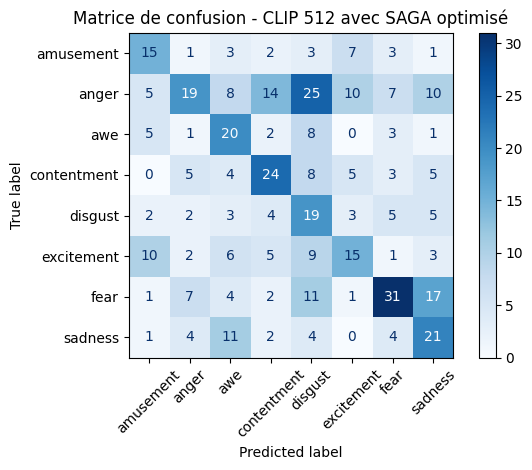

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

modele_clip512_saga_final = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        solver="saga",
        C=0.002,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    )
)

modele_clip512_saga_final.fit(X_train_512, y_train)

predictions_clip512_saga_final = modele_clip512_saga_final.predict(X_dev_512)

matrice = confusion_matrix(
    y_dev,
    predictions_clip512_saga_final,
    labels=modele_clip512_saga_final.classes_
)

affichage = ConfusionMatrixDisplay(
    confusion_matrix=matrice,
    display_labels=modele_clip512_saga_final.classes_
)

affichage.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matrice de confusion - CLIP 512 avec SAGA optimisé")
plt.tight_layout()
plt.show()

Le modèle reconnaît relativement bien les classes fear, contentment, sadness et awe, mais des confusions persistent, notamment entre anger et disgust ainsi qu'entre fear et sadness.

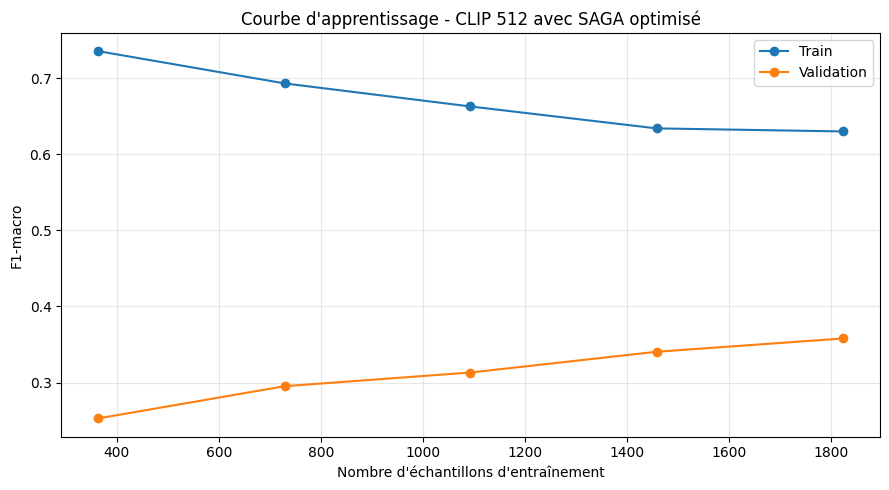

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedGroupKFold

tailles, scores_train, scores_val = learning_curve(
    modele_clip512_saga_final,
    X_train_512,
    y_train,
    groups=film_train,
    cv=StratifiedGroupKFold(
       n_splits=5,
       shuffle=True,
       random_state=42
    ),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

moyenne_train = scores_train.mean(axis=1)
moyenne_val = scores_val.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(tailles, moyenne_train, marker="o", label="Train")
plt.plot(tailles, moyenne_val, marker="o", label="Validation")

plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("F1-macro")
plt.title("Courbe d'apprentissage - CLIP 512 avec SAGA optimisé")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Le score de validation augmente progressivement jusqu'à 0,36, tandis que le score d'entraînement diminue jusqu'à 0,63. Le modèle généralise mieux avec davantage de données, même si un surapprentissage reste présent.

## Recherche du meilleur hyperparamètre GridSearchCV avec C seulement

In [ ]:
# from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
# from sklearn.linear_model import LogisticRegression
# from sklearn.pipeline import make_pipeline
# from sklearn.preprocessing import StandardScaler

# # Récupérer les vidéos d'entraînement dans le même ordre que X_train_512
# train_embeddings = df_embeddings[
#     df_embeddings["split"] == "train"
# ]

# groupes = train_embeddings["film_id"].to_numpy()

# modele = make_pipeline(
#     StandardScaler(),
#     LogisticRegression(
#         solver="saga",
#         max_iter=5000,
#         random_state=42
#     )
# )

# grille = {
#     "logisticregression__C": [0.001, 0.002, 0.003, 0.005, 0.01]
# }

# recherche_grd= GridSearchCV(
#     modele,
#     grille,
#     scoring="f1_macro",
#     cv=StratifiedGroupKFold(
#         n_splits=5,
#         shuffle=True,
#         random_state=42
#     ),
#     n_jobs=-1
# )

# recherche_grd.fit(X_train_512, y_train, groups=groupes)

# print("Meilleur C :", recherche_grd.best_params_)
# print("F1-macro moyen :", recherche_grd.best_score_)

Meilleur C : {'logisticregression__C': 0.005}
F1-macro moyen : 0.3499146262087606


In [ ]:
modele_clip512_saga_grd = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=0.005,
        solver="saga",
        max_iter=5000,
        random_state=42
    )
)

modele_clip512_saga_grd.fit(X_train_512, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=0.005, max_iter=5000, random_state=42,
                                    solver='saga'))])

**Évaluer le meilleur modèle sélectionné par validation croisée**

In [ ]:
predictions_cv_reg_clip = modele_clip512_saga_grd.predict(X_dev_512)

print("Accuracy :", round(accuracy_score(y_dev, predictions_cv_reg_clip), 4))

print("F1-macro :", round(f1_score(y_dev, predictions_cv_reg_clip, average="macro"), 4
))

Accuracy : 0.4118
F1-macro : 0.401


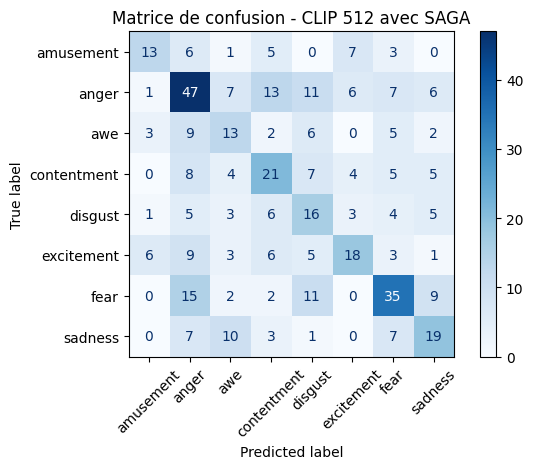

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matrice_confusion_clip_reg_grd = confusion_matrix(
    y_dev,
    predictions_cv_reg_clip,
    labels=modele_clip512_saga_grd.classes_
)

# Afficher la matrice
affichage_clip = ConfusionMatrixDisplay(
    confusion_matrix=matrice_confusion_clip_reg_grd,
    display_labels=modele_clip512_saga_grd.classes_
)

affichage_clip.plot(cmap="Blues", xticks_rotation=45)

plt.title("Matrice de confusion - CLIP 512 avec SAGA")
plt.tight_layout()
plt.show()

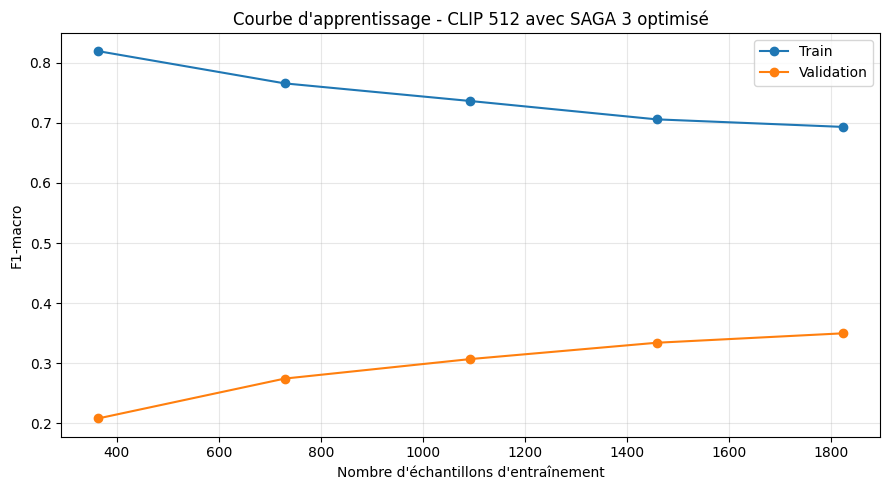

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedGroupKFold


tailles, scores_train, scores_val = learning_curve(
    modele_clip512_saga_grd,
    X_train_512,
    y_train,
    groups=film_train,
    cv=StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

moyenne_train = scores_train.mean(axis=1)
moyenne_val = scores_val.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(tailles, moyenne_train, marker="o", label="Train")
plt.plot(tailles, moyenne_val, marker="o", label="Validation")

plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("F1-macro")
plt.title("Courbe d'apprentissage - CLIP 512 avec SAGA 3 optimisé")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##Meilleure configuration de la régression logistique avec CLIP (512 dimensions)

In [ ]:
import numpy as np
X_video_512 = np.load(dossier_features / "X_video_512.npy")
labels = pd.read_csv(dossier_features / "labels_partitions.csv", dtype=str)
X_train_512 = X_video_512[labels["split"].values == "train"]
y_train = labels.loc[labels["split"] == "train", "emotion"].values
X_dev_512 = X_video_512[labels["split"].values == "dev"]
y_dev = labels.loc[labels["split"] == "dev", "emotion"].values

In [ ]:
film_train = labels.loc[labels["split"] == "train", "film_id"].values

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

modele_clip_512_sans_poids = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        solver="saga",
        C=0.002,
        class_weight=None,
        max_iter=5000,
        random_state=42
    )
)

modele_clip_512_sans_poids.fit(X_train_512, y_train)

predictions_clip_512_sans_poids = (modele_clip_512_sans_poids.predict(X_dev_512))

print("Accuracy :",accuracy_score(y_dev, predictions_clip_512_sans_poids))
print("Accuracy Balanced :",balanced_accuracy_score(y_dev, predictions_clip_512_sans_poids))

print("F1-macro :",f1_score(y_dev, predictions_clip_512_sans_poids, average="macro"))

Accuracy : 0.4230769230769231
Accuracy Balanced : 0.3963582252983274
F1-macro : 0.4058122925440236


Le modèle obtient une Accuracy de 42,31 %, ce qui signifie qu’il prédit correctement environ 42 % des émotions.

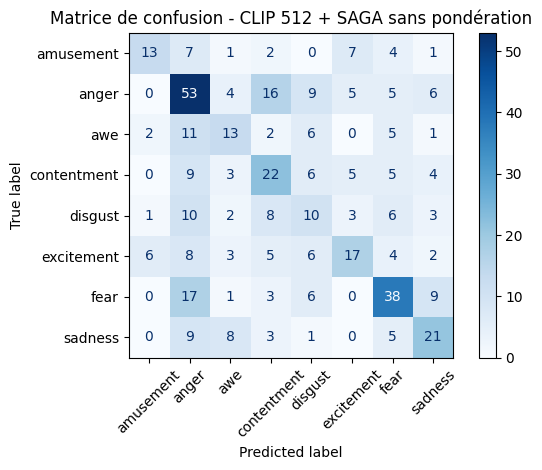

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matrice_clip_sans_poids = confusion_matrix(
    y_dev,
    predictions_clip_512_sans_poids,
    labels=modele_clip_512_sans_poids.classes_
)

affichage = ConfusionMatrixDisplay(
    confusion_matrix=matrice_clip_sans_poids,
    display_labels=modele_clip_512_sans_poids.classes_
)

affichage.plot(cmap="Blues", xticks_rotation=45)

plt.title("Matrice de confusion - CLIP 512 + SAGA sans pondération")
plt.tight_layout()
plt.show()

Le modèle reconnaît le mieux anger (53 clips correctement classés), suivi de fear (38), tandis que disgust est souvent confondu avec anger et contentment. On observe aussi une confusion entre anger et contentment (16 clips), ainsi qu’entre fear et anger (17 clips). Ces résultats montrent que le modèle distingue certaines émotions,

In [ ]:
from sklearn.metrics import classification_report

print("Rapport de classification CLIP 512")
print(classification_report(
    y_dev,
    predictions_clip_512_sans_poids,
    zero_division=0
))

Rapport de classification CLIP 512
              precision    recall  f1-score   support

   amusement       0.59      0.37      0.46        35
       anger       0.43      0.54      0.48        98
         awe       0.37      0.33      0.35        40
 contentment       0.36      0.41      0.38        54
     disgust       0.23      0.23      0.23        43
  excitement       0.46      0.33      0.39        51
        fear       0.53      0.51      0.52        74
     sadness       0.45      0.45      0.45        47

    accuracy                           0.42       442
   macro avg       0.43      0.40      0.41       442
weighted avg       0.43      0.42      0.42       442



Le modèle obtient un F1-score de 0,52 pour fear et de 0,48 pour anger, ce qui montre qu’il reconnaît mieux ces émotions. En revanche, disgust est l’émotion la plus difficile à identifier, avec un F1-score de 0,23. Avec une Accuracy de 42,3 % et un F1-macro de 0,41

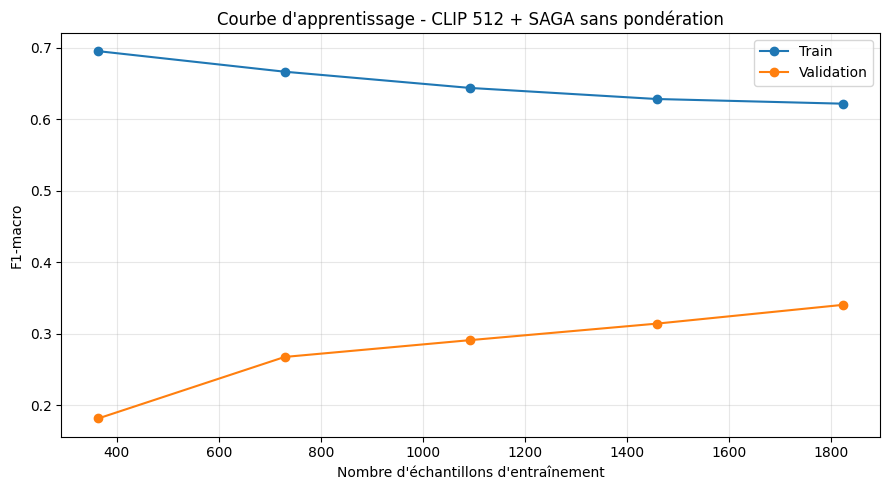

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedGroupKFold

tailles, scores_train, scores_val = learning_curve(
    modele_clip_512_sans_poids,
    X_train_512,
    y_train,
    groups=film_train,
    cv=StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

moyenne_train = scores_train.mean(axis=1)
moyenne_val = scores_val.mean(axis=1)

plt.figure(figsize=(9, 5))

plt.plot(tailles, moyenne_train, marker="o", label="Train")
plt.plot(tailles, moyenne_val, marker="o", label="Validation")

plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("F1-macro")
plt.title("Courbe d'apprentissage - CLIP 512 + SAGA sans pondération")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La courbe d'apprentissage montre que le F1-macro de validation augmente progressivement jusqu'à environ 0,34 lorsque la taille du jeu d'entraînement augmente. En parallèle, le score d'entraînement diminue de 0,69 à 0,62. L'écart entre les deux courbes se réduit légèrement, ce qui indique une amélioration de la généralisation du modèle avec davantage de données.

Parmi les modèles de régression logistique testés, le modèle CLIP 512 avec le solveur SAGA et sans pondération des classes a obtenu les meilleures performances.

##Entraîner plusieurs classifieurs SVM

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

modele_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", class_weight="balanced")
)

parametres_svm = {
    "svc__C": [0.1, 0.3, 1, 3, 10],
    "svc__gamma": ["scale", 0.001, 0.01, 0.1]
}

recherche_svm = GridSearchCV(
    modele_svm,
    parametres_svm,
    scoring="f1_macro",
    cv=StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    n_jobs=-1,
    verbose=1
)

recherche_svm.fit(
    X_train_512,
    y_train,
    groups=film_train
)

print("Meilleurs paramètres :", recherche_svm.best_params_)
print("Meilleur F1 CV :", recherche_svm.best_score_)

évaluer le SVM sur Dev

In [ ]:
# Fitting 5 folds for each of 20 candidates, totalling 100 fits
# Meilleurs paramètres : {'svc__C': 3, 'svc__gamma': 0.001}
# Meilleur F1 CV : 0.3446725034989677
from sklearn.metrics import accuracy_score, f1_score

meilleur_svm = recherche_svm.best_estimator_

predictions_svm = meilleur_svm.predict(X_dev_512)

print("Accuracy :", accuracy_score(y_dev, predictions_svm))
print("F1-macro :", f1_score(y_dev, predictions_svm, average="macro"))

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matrice_svm = confusion_matrix(
    y_dev,
    predictions_svm,
    labels=meilleur_svm.classes_
)

affichage_svm = ConfusionMatrixDisplay(
    confusion_matrix=matrice_svm,
    display_labels=meilleur_svm.classes_
)

affichage_svm.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matrice de confusion - CLIP 512 + SVM RBF")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedGroupKFold

tailles, scores_train, scores_val = learning_curve(
    meilleur_svm,
    X_train_512,
    y_train,
    groups=film_train,
    cv=StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

moyenne_train = scores_train.mean(axis=1)
moyenne_val = scores_val.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(tailles, moyenne_train, marker="o", label="Train")
plt.plot(tailles, moyenne_val, marker="o", label="Validation")

plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("F1-macro")
plt.title("Courbe d'apprentissage CLIP 512 + SVM RBF")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La courbe montre un fort surapprentissage : le score d'entraînement reste élevé, alors que le score de validation atteint seulement 0,35. Toutefois, la validation s'améliore avec davantage de données, ce qui suggère une meilleure généralisation du modèle.

##Optimisation des hyperparamètres du SVM par validation croisée (GridSearchCV)

In [ ]:
# from sklearn.svm import SVC
# from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
# from sklearn.pipeline import make_pipeline
# from sklearn.preprocessing import StandardScaler

# modele_svm = make_pipeline(
#     StandardScaler(),
#     SVC(kernel="rbf", random_state=42)
# )

# grille = {
#     "svc__C": [0.01, 0.1, 1, 3],
#     "svc__gamma": ["scale", 0.001, 0.01],
#     "svc__class_weight": [None, "balanced"]
# }

# recherche_svm = GridSearchCV(
#     modele_svm,
#     grille,
#     scoring="f1_macro",
#     cv=StratifiedGroupKFold(
#         n_splits=5,
#         shuffle=True,
#         random_state=42
#     ),
#     n_jobs=-1,
#     verbose=1
# )

# recherche_svm.fit(
#     X_train_512,
#     y_train,
#     groups=film_train
# )

# print("Meilleurs paramètres :", recherche_svm.best_params_)
# print("F1-macro moyen :", recherche_svm.best_score_)

In [ ]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

meilleur_svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=3,
        gamma=0.001,
        class_weight="balanced",
        random_state=42
    )
)

meilleur_svm.fit(X_train_512, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc',
                 SVC(C=3, class_weight='balanced', gamma=0.001,
                     random_state=42))])

In [ ]:
predictions_svm_cv = meilleur_svm.predict(X_dev_512)
print("Accuracy :", round(accuracy_score(y_dev, predictions_svm_cv), 4))

print("F1-macro :", round(f1_score(y_dev, predictions_svm_cv, average="macro"), 4))

Accuracy : 0.3778
F1-macro : 0.3673


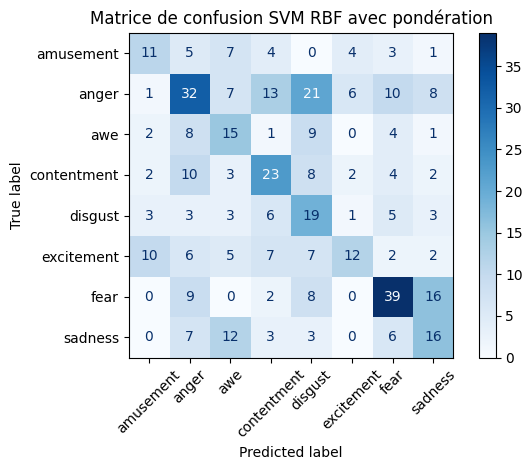

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matrice_svm = confusion_matrix(
    y_dev,
    predictions_svm_cv,
    labels=meilleur_svm.classes_
)

affichage = ConfusionMatrixDisplay(
    confusion_matrix=matrice_svm,
    display_labels=meilleur_svm.classes_
)

affichage.plot(cmap="Blues", xticks_rotation=45)

plt.title("Matrice de confusion SVM RBF avec pondération")
plt.tight_layout()
plt.show()

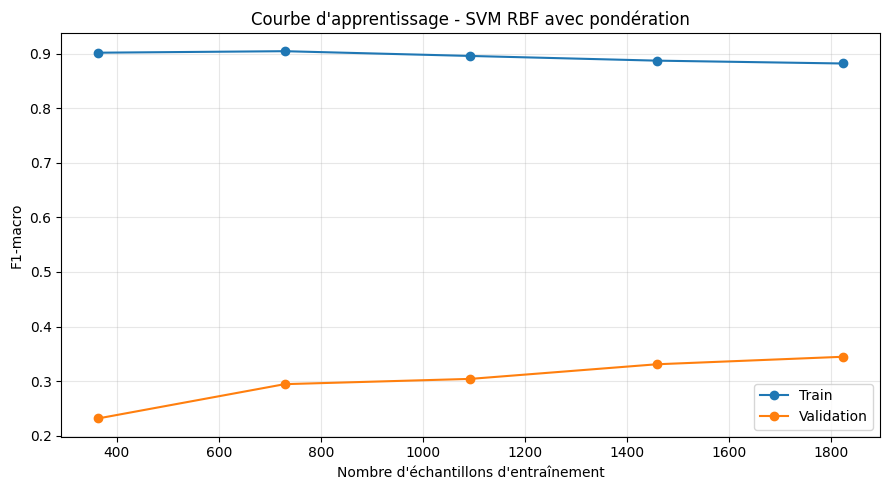

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedGroupKFold

tailles, scores_train_svm, scores_val_svm = learning_curve(
    meilleur_svm,
    X_train_512,
    y_train,
    groups=film_train,
    cv=StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

moyenne_train_svm = scores_train_svm.mean(axis=1)
moyenne_val_svm = scores_val_svm.mean(axis=1)

plt.figure(figsize=(9, 5))

plt.plot(tailles, moyenne_train_svm, marker="o", label="Train")
plt.plot(tailles, moyenne_val_svm, marker="o", label="Validation")

plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("F1-macro")
plt.title("Courbe d'apprentissage - SVM RBF avec pondération")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# MLP

Le MLP nous permettra de vérifier s’il reconnaît mieux les émotions que les deux modèles précédents.

In [ ]:
import numpy as np
import torch
from sklearn.preprocessing import StandardScaler, LabelEncoder

torch.manual_seed(42)
np.random.seed(42)

classes = [
    "amusement", "anger", "awe", "contentment",
    "disgust", "excitement", "fear", "sadness"
]

scaler_mlp = StandardScaler()
Xtr_mlp = scaler_mlp.fit_transform(X_train_512)
Xdv_mlp = scaler_mlp.transform(X_dev_512)

encodeur = LabelEncoder().fit(classes)
ytr_mlp = encodeur.transform(y_train)
ydv_mlp = encodeur.transform(y_dev)

#convertir les données au format PyTorch
Xtr_mlp = torch.tensor(Xtr_mlp, dtype=torch.float32)
Xdv_mlp = torch.tensor(Xdv_mlp, dtype=torch.float32)
ytr_mlp = torch.tensor(ytr_mlp, dtype=torch.long)
ydv_mlp = torch.tensor(ydv_mlp, dtype=torch.long)

print("X train :", Xtr_mlp.shape)
print("X dev   :", Xdv_mlp.shape)
print("Nombre de classes :", len(encodeur.classes_))
print("Ordre des classes :", list(encodeur.classes_))

X train : torch.Size([2207, 512])
X dev   : torch.Size([442, 512])
Nombre de classes : 8
Ordre des classes : [np.str_('amusement'), np.str_('anger'), np.str_('awe'), np.str_('contentment'), np.str_('disgust'), np.str_('excitement'), np.str_('fear'), np.str_('sadness')]


In [ ]:
import random
import numpy as np
import torch

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

**Construire le MLP**

In [ ]:
import torch.nn as nn

mlp = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 8)
)

print(mlp)

Sequential(
  (0): Linear(in_features=512, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.4, inplace=False)
  (3): Linear(in_features=256, out_features=8, bias=True)
)


**Préparer l’apprentissage**

In [ ]:
#calculer les poids des 8 classes
effectifs = np.bincount(ytr_mlp.numpy(), minlength=8)

poids_classes = torch.tensor(
    len(ytr_mlp) / (8 * effectifs),
    dtype=torch.float32
)

# fonction de perte
critere = nn.CrossEntropyLoss(weight=poids_classes)

# ajuste les paramètres du réseau
optimiseur = torch.optim.AdamW(
    mlp.parameters(),
    lr=1e-3, # learning rate
    weight_decay=1e-2# regularisation
)

print("poids des classes :", poids_classes)
print("fonction de perte et optimiseur prêts.")

poids des classes : tensor([1.5855, 0.5712, 1.3392, 1.0410, 1.3075, 1.0947, 0.7436, 1.1260])
fonction de perte et optimiseur prêts.


**entrainer le reseau**

In [ ]:
from sklearn.metrics import f1_score, accuracy_score
import copy
import torch

meilleur_f1 = 0
meilleur_accuracy = 0
meilleur_etat = None

patience = 0
patience_max = 10

# Historiques F1 / Accuracy
historique_f1 = []
historique_accuracy = []

historique_f1_train = []
historique_accuracy_train = []

# Historiques Loss
historique_loss_train = []
historique_loss_dev = []

for epoque in range(200):

    # 1. Entraînement
    mlp.train()
    permutation = torch.randperm(len(Xtr_mlp))

    for i in range(0, len(Xtr_mlp), 64):
        indices = permutation[i:i + 64]

        optimiseur.zero_grad()

        sorties = mlp(Xtr_mlp[indices])
        perte = critere(sorties, ytr_mlp[indices])

        perte.backward()
        optimiseur.step()

    # 2. Évaluation Train et Dev
    mlp.eval()

    with torch.inference_mode():

        # Prédictions
        logits_train = mlp(Xtr_mlp)
        logits_dev = mlp(Xdv_mlp)

        predictions_train = logits_train.argmax(dim=1).cpu().numpy()
        predictions_dev = logits_dev.argmax(dim=1).cpu().numpy()

        # Loss
        loss_train = critere(logits_train, ytr_mlp).item()
        loss_dev = critere(logits_dev, ydv_mlp).item()

    y_train_numpy = ytr_mlp.cpu().numpy()
    y_dev_numpy = ydv_mlp.cpu().numpy()

    # Métriques Train
    f1_train = f1_score(
        y_train_numpy,
        predictions_train,
        average="macro"
    )

    accuracy_train = accuracy_score(
        y_train_numpy,
        predictions_train
    )

    # Métriques Dev
    f1 = f1_score(
        y_dev_numpy,
        predictions_dev,
        average="macro"
    )

    accuracy = accuracy_score(
        y_dev_numpy,
        predictions_dev
    )

    # Sauvegarde historique
    historique_f1_train.append(f1_train)
    historique_accuracy_train.append(accuracy_train)

    historique_f1.append(f1)
    historique_accuracy.append(accuracy)

    historique_loss_train.append(loss_train)
    historique_loss_dev.append(loss_dev)

    # Sauvegarde meilleur modèle
    if f1 > meilleur_f1:
        meilleur_f1 = f1
        meilleur_accuracy = accuracy
        patience = 0

        meilleur_etat = copy.deepcopy(mlp.state_dict())

    else:
        patience += 1

    print(
        f"Époque {epoque + 1} | "
        f"Loss Train : {loss_train:.4f} | "
        f"Loss Dev : {loss_dev:.4f} | "
        f"F1 Train : {f1_train:.4f} | "
        f"F1 Dev : {f1:.4f}"
    )

    if patience >= patience_max:
        print("Arrêt anticipé : le F1-macro ne s'améliore plus.")
        break

# Restauration du meilleur modèle
if meilleur_etat is not None:
    mlp.load_state_dict(meilleur_etat)

print("\n--- Résultats finaux ---")
print("Nombre d'époques :", epoque + 1)
print("Meilleur F1-macro sur Dev :", round(meilleur_f1, 4))
print("Accuracy correspondante :", round(meilleur_accuracy, 4))


Époque 1 | Loss Train : 1.3991 | Loss Dev : 1.7125 | F1 Train : 0.5368 | F1 Dev : 0.3546
Époque 2 | Loss Train : 1.1302 | Loss Dev : 1.6383 | F1 Train : 0.6199 | F1 Dev : 0.3689
Époque 3 | Loss Train : 0.9500 | Loss Dev : 1.6329 | F1 Train : 0.6764 | F1 Dev : 0.3659
Époque 4 | Loss Train : 0.8129 | Loss Dev : 1.6262 | F1 Train : 0.7399 | F1 Dev : 0.3967
Époque 5 | Loss Train : 0.6999 | Loss Dev : 1.6397 | F1 Train : 0.7889 | F1 Dev : 0.3924
Époque 6 | Loss Train : 0.5991 | Loss Dev : 1.6939 | F1 Train : 0.8223 | F1 Dev : 0.3877
Époque 7 | Loss Train : 0.5227 | Loss Dev : 1.7212 | F1 Train : 0.8397 | F1 Dev : 0.3868
Époque 8 | Loss Train : 0.4588 | Loss Dev : 1.7457 | F1 Train : 0.8635 | F1 Dev : 0.3758
Époque 9 | Loss Train : 0.3985 | Loss Dev : 1.8122 | F1 Train : 0.8924 | F1 Dev : 0.3786
Époque 10 | Loss Train : 0.3504 | Loss Dev : 1.8203 | F1 Train : 0.9084 | F1 Dev : 0.3775
Époque 11 | Loss Train : 0.3097 | Loss Dev : 1.9319 | F1 Train : 0.9165 | F1 Dev : 0.3759
Époque 12 | Loss Tr

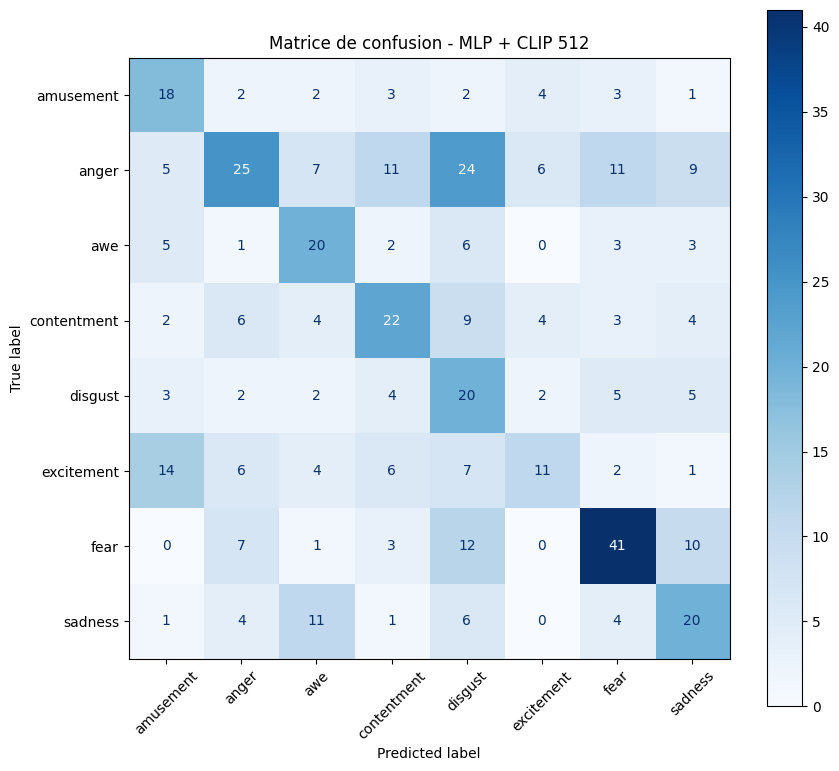

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

mlp.eval()

classes = [
    "amusement", "anger", "awe", "contentment",
    "disgust", "excitement", "fear", "sadness"
]

with torch.inference_mode():
    predictions_dev = mlp(Xdv_mlp).argmax(dim=1).cpu().numpy()

y_dev_numpy = ydv_mlp.cpu().numpy()

matrice = confusion_matrix(
    y_dev_numpy,
    predictions_dev,
    labels=np.arange(len(classes))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matrice,
    display_labels=classes
)

fig, ax = plt.subplots(figsize=(9, 8))
disp.plot(cmap="Blues", xticks_rotation=45, values_format="d", ax=ax)

plt.title("Matrice de confusion - MLP + CLIP 512")
plt.tight_layout()
plt.show()

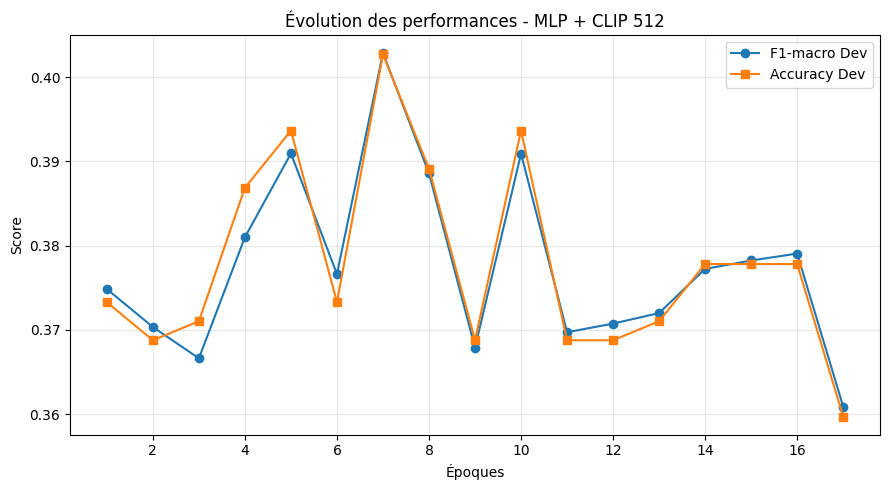

In [ ]:
import matplotlib.pyplot as plt

epoques = range(1, len(historique_f1) + 1)
plt.figure(figsize=(9, 5))
plt.plot(epoques, historique_f1, marker="o", label="F1-macro Dev")
plt.plot(epoques, historique_accuracy, marker="s", label="Accuracy Dev")
plt.xlabel("Époques")
plt.ylabel("Score")
plt.title("Évolution des performances - MLP + CLIP 512")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Les performances restent assez stables au cours des époques. Le meilleur score est atteint vers l'époque 9, avec un F1-macro d'environ 0,38.

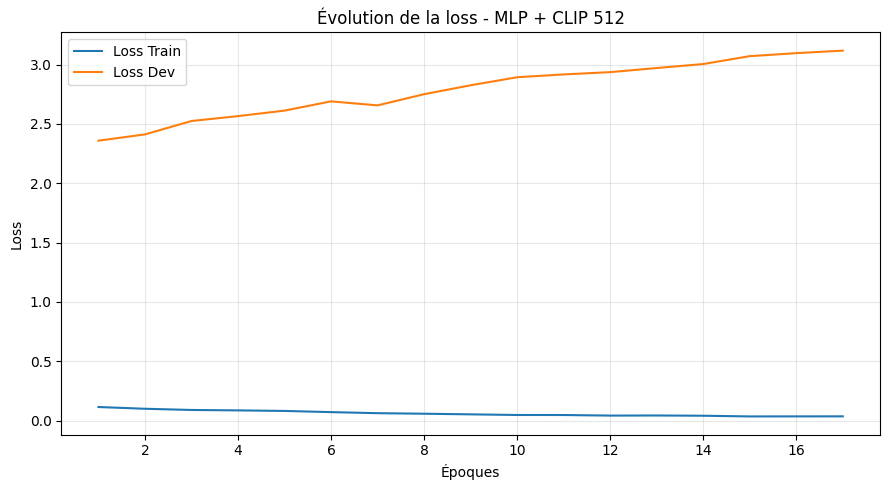

In [ ]:
import matplotlib.pyplot as plt

epoques = range(1, len(historique_loss_train) + 1)

plt.figure(figsize=(9,5))

plt.plot(
    epoques,
    historique_loss_train,
    label="Loss Train"
)

plt.plot(
    epoques,
    historique_loss_dev,
    label="Loss Dev"
)

plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Évolution de la loss - MLP + CLIP 512")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

La Loss Train diminue jusqu'à 0,05, tandis que la Loss Dev augmente au-delà de 3, ce qui montre un fort surapprentissage. Le modèle apprend très bien les données d'entraînement, mais généralise mal sur les nouvelles données.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

predictions_lr = recherche.best_estimator_.predict(X_dev_512)
predictions_svm = recherche_svm.best_estimator_.predict(X_dev_512)

# Les prédictions actuelles correspondent au MLP
mlp.eval()

with torch.inference_mode():
    predictions_mlp_id = mlp(Xdv_mlp).argmax(dim=1).numpy()

predictions_mlp = encodeur.inverse_transform(predictions_mlp_id)
comparaison = pd.DataFrame([
    {
        "Modèle": "Régression logistique",
        "Accuracy": accuracy_score(y_dev, predictions_lr),
        "F1-macro": f1_score(y_dev, predictions_lr, average="macro")
    },
    {
        "Modèle": "SVM",
        "Accuracy": accuracy_score(y_dev, predictions_svm),
        "F1-macro": f1_score(y_dev, predictions_svm, average="macro")
    },
    {
        "Modèle": "MLP",
        "Accuracy": accuracy_score(y_dev, predictions_mlp),
        "F1-macro": f1_score(y_dev, predictions_mlp, average="macro")
    }
])

print(comparaison.round(4).to_string(index=False))

               Modèle  Accuracy  F1-macro
Régression logistique    0.3733    0.3777
                  SVM    0.3824    0.3655
                  MLP    0.4005    0.3967


In [ ]:
print("X train :", Xtr_mlp.shape)
print("X dev :", Xdv_mlp.shape)
print("y train :", ytr_mlp.shape)
print("y dev :", ydv_mlp.shape)
print("Poids des classes :", poids_classes)

X train : torch.Size([2207, 512])
X dev : torch.Size([442, 512])
y train : torch.Size([2207])
y dev : torch.Size([442])
Poids des classes : tensor([1.5855, 0.5712, 1.3392, 1.0410, 1.3075, 1.0947, 0.7436, 1.1260])


Tester les paramètres du MLP

#  MLP testé 5 configurations de paramètres, avec toujours une seule couche cachée.

préparer les configurations

In [ ]:
configurations = [
    (256, 0.4, 0.001),
    (128, 0.3, 0.001),
    (256, 0.3, 0.001),
    (256, 0.5, 0.001),
    (256, 0.4, 0.0005)
]

graines = [42, 1, 2]

resultats = []

In [ ]:
import torch
import torch.nn as nn
import numpy as np
from sklearn.metrics import f1_score, accuracy_score

for neurones, dropout, lr in configurations:

    scores = []
    accuracies = []

    for graine in graines:

        torch.manual_seed(graine)
        np.random.seed(graine)

        mlp_test = nn.Sequential(
            nn.Linear(512, neurones),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(neurones, 8)
        )

        loss = nn.CrossEntropyLoss(weight=poids_classes)

        optimiseur = torch.optim.AdamW(
            mlp_test.parameters(),
            lr=lr,
            weight_decay=0.01
        )

        meilleur_f1 = 0
        patience = 0

        for epoque in range(100):

            # Entraînement
            mlp_test.train()
            ordre = torch.randperm(len(Xtr_mlp))

            for i in range(0, len(Xtr_mlp), 64):
                idx = ordre[i:i+64]

                optimiseur.zero_grad()
                sortie = mlp_test(Xtr_mlp[idx])
                perte = loss(sortie, ytr_mlp[idx])
                perte.backward()
                optimiseur.step()

            # Évaluation
            mlp_test.eval()

            with torch.no_grad():
                pred = mlp_test(Xdv_mlp).argmax(1).numpy()

            score = f1_score(
                ydv_mlp.numpy(),
                pred,
                average="macro"
            )

            accuracy = accuracy_score(
                ydv_mlp.numpy(),
                pred
            )

            if score > meilleur_f1:
                meilleur_f1 = score
                meilleure_accuracy = accuracy
                patience = 0
            else:
                patience += 1

            if patience >= 10:
                break

        scores.append(meilleur_f1)
        accuracies.append(meilleure_accuracy)

    # Résultats moyens
    moyenne_f1 = np.mean(scores)
    ecart_type = np.std(scores, ddof=1)
    moyenne_accuracy = np.mean(accuracies)

    resultats.append([
        neurones,
        dropout,
        lr,
        moyenne_f1,
        ecart_type,
        moyenne_accuracy
    ])

    print(
        f"Neurones={neurones}, Dropout={dropout}, LR={lr} "
        f"| F1 moyen={moyenne_f1:.4f} "
        f"| Écart-type={ecart_type:.4f} "
        f"| Accuracy={moyenne_accuracy:.4f}"
    )

Neurones=256, Dropout=0.4, LR=0.001 | F1 moyen=0.3998 | Écart-type=0.0028 | Accuracy=0.3982
Neurones=128, Dropout=0.3, LR=0.001 | F1 moyen=0.3971 | Écart-type=0.0071 | Accuracy=0.3929
Neurones=256, Dropout=0.3, LR=0.001 | F1 moyen=0.3976 | Écart-type=0.0017 | Accuracy=0.3974
Neurones=256, Dropout=0.5, LR=0.001 | F1 moyen=0.3998 | Écart-type=0.0071 | Accuracy=0.3952
Neurones=256, Dropout=0.4, LR=0.0005 | F1 moyen=0.4018 | Écart-type=0.0052 | Accuracy=0.4005


In [ ]:
import pandas as pd

df_resultats = pd.DataFrame(
    resultats,
    columns=[
        "Neurones",
        "Dropout",
        "Learning rate",
        "F1 moyen",
        "Écart-type",
        "Accuracy moyenne"
    ]
)

df_resultats = df_resultats.sort_values(
    by="F1 moyen",
    ascending=False
)

display(df_resultats)

,Neurones,Dropout,Learning rate,F1 moyen,Écart-type,Accuracy moyenne
4,256,0.4,0.0005,0.401789,0.005213,0.400452
0,256,0.4,0.0010,0.399765,0.002847,0.398190
3,256,0.5,0.0010,0.399752,0.007115,0.395173
2,256,0.3,0.0010,0.397625,0.001737,0.397436
1,128,0.3,0.0010,0.397109,0.007081,0.392911


réentraîne le modèle avec la meilleure configuration avce une couche cache

In [ ]:
import torch
import torch.nn as nn
import copy
from sklearn.metrics import f1_score, accuracy_score

# Création du deuxième MLP
mlp_final_2 = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 8)
)

# Loss et optimiseur
critere_2 = nn.CrossEntropyLoss(weight=poids_classes)

optimiseur_2 = torch.optim.AdamW(
    mlp_final_2.parameters(),
    lr=0.0005,
    weight_decay=0.01
)

# Historiques
historique_loss_train_2 = []
historique_loss_dev_2 = []
historique_f1_train_2 = []
historique_f1_dev_2 = []
historique_accuracy_train_2 = []
historique_accuracy_dev_2 = []

meilleur_f1_2 = 0
meilleur_etat_2 = None
patience_2 = 0

# Entraînement
for epoque_2 in range(100):

    mlp_final_2.train()
    ordre_2 = torch.randperm(len(Xtr_mlp))

    for i_2 in range(0, len(Xtr_mlp), 64):
        idx_2 = ordre_2[i_2:i_2+64]

        optimiseur_2.zero_grad()
        sortie_2 = mlp_final_2(Xtr_mlp[idx_2])
        perte_2 = critere_2(sortie_2, ytr_mlp[idx_2])
        perte_2.backward()
        optimiseur_2.step()

    # Évaluation
    mlp_final_2.eval()

    with torch.no_grad():
        sortie_train_2 = mlp_final_2(Xtr_mlp)
        sortie_dev_2 = mlp_final_2(Xdv_mlp)

        loss_train_2 = critere_2(sortie_train_2, ytr_mlp).item()
        loss_dev_2 = critere_2(sortie_dev_2, ydv_mlp).item()

        pred_train_2 = sortie_train_2.argmax(1).cpu().numpy()
        pred_dev_2 = sortie_dev_2.argmax(1).cpu().numpy()

    y_train_numpy_2 = ytr_mlp.cpu().numpy()
    y_dev_numpy_2 = ydv_mlp.cpu().numpy()

    f1_train_2 = f1_score(y_train_numpy_2, pred_train_2, average="macro")
    f1_dev_2 = f1_score(y_dev_numpy_2, pred_dev_2, average="macro")

    accuracy_train_2 = accuracy_score(y_train_numpy_2, pred_train_2)
    accuracy_dev_2 = accuracy_score(y_dev_numpy_2, pred_dev_2)

    historique_loss_train_2.append(loss_train_2)
    historique_loss_dev_2.append(loss_dev_2)
    historique_f1_train_2.append(f1_train_2)
    historique_f1_dev_2.append(f1_dev_2)
    historique_accuracy_train_2.append(accuracy_train_2)
    historique_accuracy_dev_2.append(accuracy_dev_2)

    # Sauvegarde du meilleur modèle
    if f1_dev_2 > meilleur_f1_2:
        meilleur_f1_2 = f1_dev_2
        meilleur_etat_2 = copy.deepcopy(mlp_final_2.state_dict())
        patience_2 = 0
    else:
        patience_2 += 1

    print(
        f"Époque {epoque_2+1} | "
        f"Loss Train={loss_train_2:.4f} | "
        f"Loss Dev={loss_dev_2:.4f} | "
        f"F1 Train={f1_train_2:.4f} | "
        f"F1 Dev={f1_dev_2:.4f} | "
        f"Accuracy Train={accuracy_train_2:.4f} | "
        f"Accuracy Dev={accuracy_dev_2:.4f}"
    )

    if patience_2 >= 10:
        print("Arrêt anticipé.")
        break

# Restauration du meilleur modèle
if meilleur_etat_2 is not None:
    mlp_final_2.load_state_dict(meilleur_etat_2)

print("\nMeilleur F1-macro Dev :", round(meilleur_f1_2, 4))


Époque 1 | Loss Train=1.6066 | Loss Dev=1.8156 | F1 Train=0.4759 | F1 Dev=0.2985 | Accuracy Train=0.4857 | Accuracy Dev=0.3100
Époque 2 | Loss Train=1.3702 | Loss Dev=1.7107 | F1 Train=0.5520 | F1 Dev=0.3567 | Accuracy Train=0.5546 | Accuracy Dev=0.3620
Époque 3 | Loss Train=1.2124 | Loss Dev=1.6584 | F1 Train=0.6050 | F1 Dev=0.3638 | Accuracy Train=0.6076 | Accuracy Dev=0.3688
Époque 4 | Loss Train=1.0892 | Loss Dev=1.6348 | F1 Train=0.6592 | F1 Dev=0.3858 | Accuracy Train=0.6584 | Accuracy Dev=0.3846
Époque 5 | Loss Train=0.9859 | Loss Dev=1.6390 | F1 Train=0.6907 | F1 Dev=0.3801 | Accuracy Train=0.6896 | Accuracy Dev=0.3778
Époque 6 | Loss Train=0.8972 | Loss Dev=1.6296 | F1 Train=0.7261 | F1 Dev=0.3839 | Accuracy Train=0.7241 | Accuracy Dev=0.3824
Époque 7 | Loss Train=0.8195 | Loss Dev=1.6489 | F1 Train=0.7521 | F1 Dev=0.3848 | Accuracy Train=0.7481 | Accuracy Dev=0.3824
Époque 8 | Loss Train=0.7506 | Loss Dev=1.6527 | F1 Train=0.7776 | F1 Dev=0.3955 | Accuracy Train=0.7744 | Accu

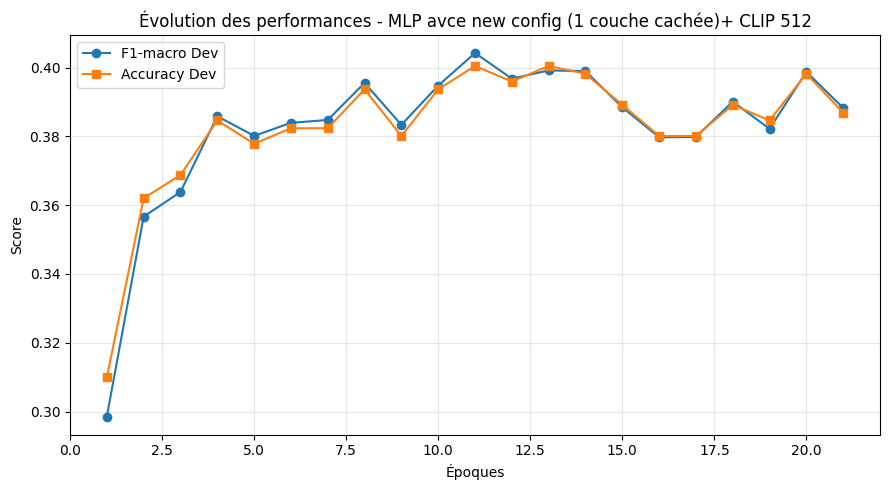

In [ ]:
import matplotlib.pyplot as plt

epoques = range(1, len(historique_f1_dev_2) + 1)
plt.figure(figsize=(9, 5))
plt.plot(epoques, historique_f1_dev_2, marker="o", label="F1-macro Dev")
plt.plot(epoques, historique_accuracy_dev_2, marker="s", label="Accuracy Dev")
plt.xlabel("Époques")
plt.ylabel("Score")
plt.title("Évolution des performances - MLP avce new config (1 couche cachée)+ CLIP 512")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

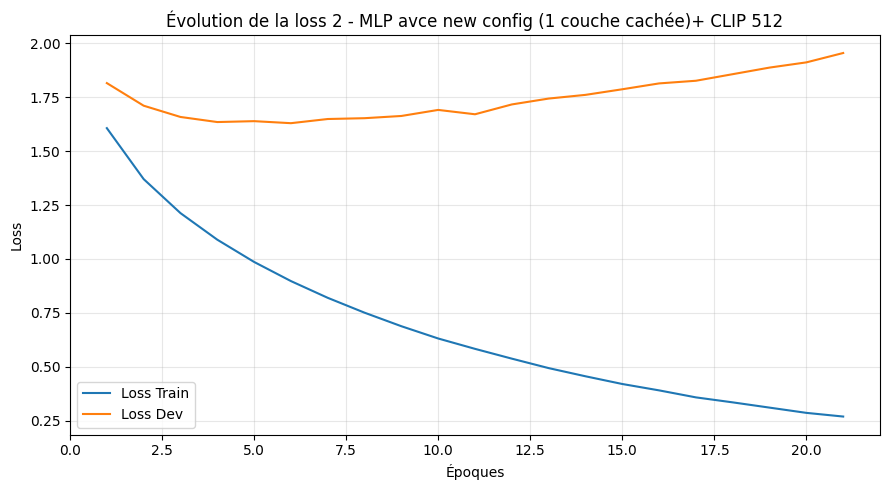

In [ ]:
import matplotlib.pyplot as plt

epoques = range(1, len(historique_loss_train_2) + 1)

plt.figure(figsize=(9,5))

plt.plot(
    epoques,
    historique_loss_train_2,
    label="Loss Train"
)

plt.plot(
    epoques,
    historique_loss_dev_2,
    label="Loss Dev"
)

plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Évolution de la loss 2 - MLP avce new config (1 couche cachée)+ CLIP 512")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


La diminution de la Loss Train et l'augmentation de la Loss Dev après quelques époques révèlent un phénomène de surapprentissage

In [ ]:
!pip install torchview graphviz

In [ ]:
print(mlp_final_2)

Sequential(
  (0): Linear(in_features=512, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.4, inplace=False)
  (3): Linear(in_features=256, out_features=8, bias=True)
)


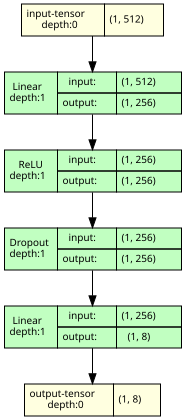

In [ ]:
from torchview import draw_graph

schema_mlp = draw_graph(
    mlp_final_2,
    input_size=(1, 512),
    graph_name="Architecture_MLP_CLIP",
    expand_nested=True
)

schema_mlp.visual_graph

In [ ]:
print(schema_mlp)

In [ ]:
import copy
import torch
import torch.nn as nn
from sklearn.metrics import f1_score, accuracy_score

torch.manual_seed(42)

mlp_final_3 = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 8)
)

loss = nn.CrossEntropyLoss(weight=poids_classes)

optimiseur = torch.optim.AdamW(
    mlp_final_3.parameters(),
    lr=0.0005,
    weight_decay=0.01
)

meilleur_f1 = 0
meilleure_accuracy = 0
meilleurs_poids = None
meilleure_epoque = 0
patience = 0

historique_loss_train_3 = []
historique_loss_dev_3 = []

historique_f1_train_3 = []
historique_f1_dev_3 = []

historique_accuracy_train_3 = []
historique_accuracy_dev_3 = []

for epoque in range(100):

    mlp_final_3.train()

    ordre = torch.randperm(len(Xtr_mlp))

    for i in range(0, len(Xtr_mlp), 64):

        idx = ordre[i:i+64]

        optimiseur.zero_grad()

        sortie = mlp_final_3(Xtr_mlp[idx])
        perte = loss(sortie, ytr_mlp[idx])

        perte.backward()
        optimiseur.step()

    mlp_final_3.eval()

    with torch.no_grad():

        logits_train = mlp_final_3(Xtr_mlp)
        logits_dev = mlp_final_3(Xdv_mlp)

        loss_train = loss(logits_train, ytr_mlp).item()
        loss_dev = loss(logits_dev, ydv_mlp).item()

        pred_train = logits_train.argmax(1).cpu().numpy()
        pred_dev = logits_dev.argmax(1).cpu().numpy()

        f1_train = f1_score(
            ytr_mlp.cpu().numpy(),
            pred_train,
            average="macro"
        )

        f1_dev = f1_score(
            ydv_mlp.cpu().numpy(),
            pred_dev,
            average="macro"
        )

        accuracy_train = accuracy_score(
            ytr_mlp.cpu().numpy(),
            pred_train
        )

        accuracy_dev = accuracy_score(
            ydv_mlp.cpu().numpy(),
            pred_dev
        )

    historique_loss_train_3.append(loss_train)
    historique_loss_dev_3.append(loss_dev)

    historique_f1_train_3.append(f1_train)
    historique_f1_dev_3.append(f1_dev)

    historique_accuracy_train_3.append(accuracy_train)
    historique_accuracy_dev_3.append(accuracy_dev)

    if f1_dev > meilleur_f1:

        meilleur_f1 = f1_dev
        meilleure_accuracy = accuracy_dev
        meilleure_epoque = epoque + 1

        meilleurs_poids = copy.deepcopy(
            mlp_final_3.state_dict()
        )

        patience = 0

    else:
        patience += 1

    print(
        f"Epoch {epoque+1:03d} | "
        f"Loss Train={loss_train:.4f} | "
        f"Loss Dev={loss_dev:.4f} | "
        f"F1 Train={f1_train:.4f} | "
        f"F1 Dev={f1_dev:.4f}"
    )

    if patience >= 10:
        break

mlp_final_3.load_state_dict(meilleurs_poids)

torch.save(
    mlp_final_3.state_dict(),
    "mlp_video_final.pth"
)

print("\nMeilleure époque :", meilleure_epoque)
print("Meilleure Accuracy sur dev :", round(meilleure_accuracy, 4))
print("Meilleur F1-macro sur dev :", round(meilleur_f1, 4))
print("Modèle sauvegardé : mlp_video_final.pth")

Epoch 001 | Loss Train=1.6143 | Loss Dev=1.8101 | F1 Train=0.4859 | F1 Dev=0.3125
Epoch 002 | Loss Train=1.3747 | Loss Dev=1.6926 | F1 Train=0.5564 | F1 Dev=0.3544
Epoch 003 | Loss Train=1.2113 | Loss Dev=1.6403 | F1 Train=0.6071 | F1 Dev=0.3820
Epoch 004 | Loss Train=1.0862 | Loss Dev=1.6275 | F1 Train=0.6515 | F1 Dev=0.4012
Epoch 005 | Loss Train=0.9797 | Loss Dev=1.6023 | F1 Train=0.6943 | F1 Dev=0.3957
Epoch 006 | Loss Train=0.8892 | Loss Dev=1.6082 | F1 Train=0.7243 | F1 Dev=0.3875
Epoch 007 | Loss Train=0.8106 | Loss Dev=1.6129 | F1 Train=0.7502 | F1 Dev=0.3834
Epoch 008 | Loss Train=0.7415 | Loss Dev=1.6235 | F1 Train=0.7837 | F1 Dev=0.3972
Epoch 009 | Loss Train=0.6779 | Loss Dev=1.6331 | F1 Train=0.8098 | F1 Dev=0.3946
Epoch 010 | Loss Train=0.6209 | Loss Dev=1.6400 | F1 Train=0.8275 | F1 Dev=0.3939
Epoch 011 | Loss Train=0.5718 | Loss Dev=1.6704 | F1 Train=0.8363 | F1 Dev=0.4075
Epoch 012 | Loss Train=0.5230 | Loss Dev=1.6981 | F1 Train=0.8595 | F1 Dev=0.3991
Epoch 013 | Loss

Le modèle MLP atteint une accuracy de 40,72 % et un F1-macro de 40,75 % sur les données de validation. Ces résultats montrent que le modèle prédit correctement une partie des émotions, mais qu’il peut encore être amélioré.

In [ ]:
from sklearn.metrics import f1_score, accuracy_score

mlp_final_3.eval()

with torch.no_grad():
    predictions_id = mlp_final_3(Xdv_mlp).argmax(dim=1).cpu().numpy()

y_reel_mlp = ydv_mlp.cpu().numpy()

accuracy_mlp = accuracy_score(y_reel_mlp, predictions_id)
f1_mlp = f1_score(y_reel_mlp, predictions_id, average="macro")

print("Résultats du MLP final sur Dev")
print("Accuracy :", round(accuracy_mlp, 4))
print("F1-macro :", round(f1_mlp, 4))

Résultats du MLP final sur Dev
Accuracy : 0.4072
F1-macro : 0.4075


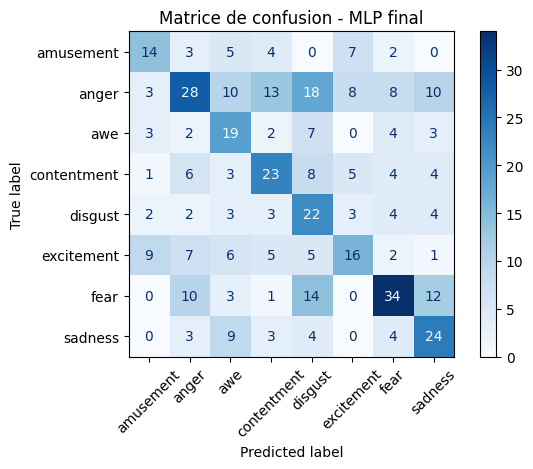

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

noms_emotions = [
    "amusement", "anger", "awe", "contentment",
    "disgust", "excitement", "fear", "sadness"
]

matrice_clip_mlp = confusion_matrix(
    y_reel_mlp,
    predictions_id,
    labels=list(range(8))
)

ConfusionMatrixDisplay(
    confusion_matrix=matrice_clip_mlp,
    display_labels=noms_emotions
).plot(cmap="Blues", xticks_rotation=45, values_format="d")

plt.title("Matrice de confusion - MLP final")
plt.tight_layout()
plt.show()

Fear :est assez bien détectée : 34 sur 74 sont correctement classés.

Contentment: est correctement détectée dans 23 sur 54, et Sadness dans 24 sur 47.

Anger : est souvent confondue avec disgust (18), contentment (13) et awe (10).

Fear est aussi souvent confondue avec disgust (14) et sadness (12).

le modèle reconnaît relativement mieux fear et sadness, mais il confond plusieurs émotions proches, notamment anger et disgust.

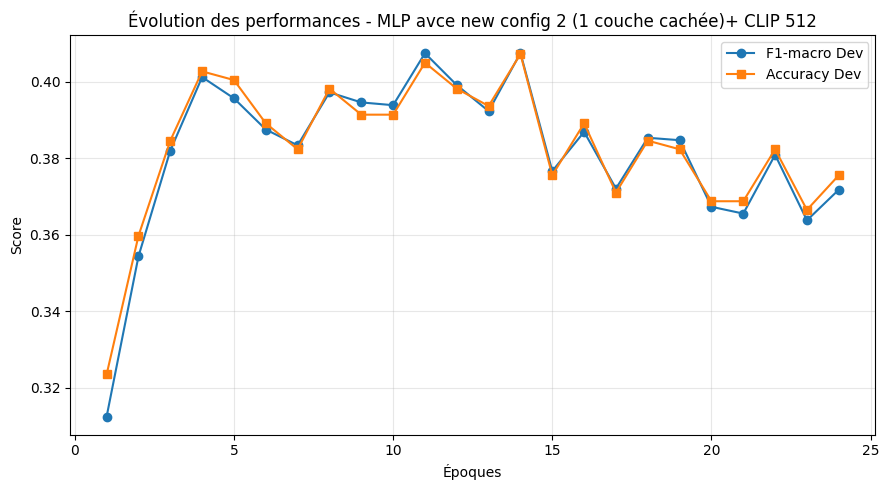

In [ ]:
import matplotlib.pyplot as plt

epoques = range(1, len(historique_f1_dev_3) + 1)
plt.figure(figsize=(9, 5))
plt.plot(epoques, historique_f1_dev_3, marker="o", label="F1-macro Dev")
plt.plot(epoques, historique_accuracy_dev_3, marker="s", label="Accuracy Dev")
plt.xlabel("Époques")
plt.ylabel("Score")
plt.title("Évolution des performances - MLP avce new config 2 (1 couche cachée)+ CLIP 512")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

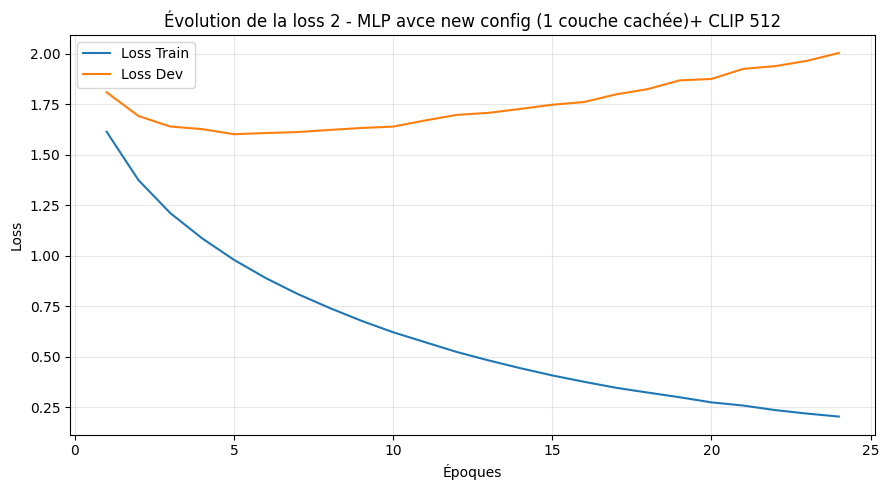

In [ ]:
import matplotlib.pyplot as plt

epoques = range(1, len(historique_loss_train_3) + 1)

plt.figure(figsize=(9,5))

plt.plot(
    epoques,
    historique_loss_train_3,
    label="Loss Train"
)

plt.plot(
    epoques,
    historique_loss_dev_3,
    label="Loss Dev"
)

plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Évolution de la loss 2 - MLP avce new config (1 couche cachée)+ CLIP 512")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [ ]:
import optuna
import torch

print("Optuna :", optuna.__version__)
print("Xtr_mlp :", Xtr_mlp.shape)
print("ytr_mlp :", ytr_mlp.shape)
print("Xdv_mlp :", Xdv_mlp.shape)
print("ydv_mlp :", ydv_mlp.shape)
print("Nombre de classes :", len(torch.unique(ytr_mlp)))
print("Poids des classes :", poids_classes.shape)

Optuna : 5.0.0
Xtr_mlp : torch.Size([2207, 512])
ytr_mlp : torch.Size([2207])
Xdv_mlp : torch.Size([442, 512])
ydv_mlp : torch.Size([442])
Nombre de classes : 8
Poids des classes : torch.Size([8])


**préparer les bibliothèques**

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import optuna

from sklearn.metrics import f1_score

print("Optuna :", optuna.__version__)
print("Données prêtes :", Xtr_mlp.shape, Xdv_mlp.shape)

Optuna : 5.0.0
Données prêtes : torch.Size([2207, 512]) torch.Size([442, 512])


**préparer les données**

In [ ]:
appareil = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_train = Xtr_mlp.to(appareil).float()
y_train = ytr_mlp.to(appareil).long()
X_dev = Xdv_mlp.to(appareil).float()
y_dev = ydv_mlp.to(appareil).long()
poids = poids_classes.to(appareil).float()

#MLP deux couches cachés

In [ ]:
def creer_mlp(n1, n2, dropout):
    modele = nn.Sequential(
        nn.Linear(512, n1),
        nn.ReLU(),
        nn.Dropout(dropout),

        nn.Linear(n1, n2),
        nn.ReLU(),
        nn.Dropout(dropout),

        nn.Linear(n2, 8)
    )
    return modele.to(appareil)

**entrainement MLP deux couches**

In [ ]:
def entrainer_mlp(modele, learning_rate):
    fonction_perte = nn.CrossEntropyLoss(weight=poids)
    optimiseur = torch.optim.AdamW(
        modele.parameters(),
        lr=learning_rate,
        weight_decay=0.01
    )

    meilleur_f1 = 0.0
    meilleurs_poids = None
    patience = 0

    for epoque in range(100):
        modele.train()
        ordre = torch.randperm(len(X_train), device=appareil)
        for i in range(0, len(X_train), 64):
            indices = ordre[i:i + 64]
            optimiseur.zero_grad()
            sorties = modele(X_train[indices])
            perte = fonction_perte(sorties, y_train[indices])
            perte.backward()
            optimiseur.step()
        modele.eval()

        with torch.no_grad():
            predictions = modele(X_dev).argmax(dim=1)

        score = f1_score(
            y_dev.cpu().numpy(),
            predictions.cpu().numpy(),
            average="macro",
            zero_division=0
        )

        #les meilleurs poids
        if score > meilleur_f1:
            meilleur_f1 = score
            meilleurs_poids = {
                nom: valeur.detach().clone()
                for nom, valeur in modele.state_dict().items()
            }
            patience = 0
        else:
            patience += 1

        if patience >= 10:
            break
    modele.load_state_dict(meilleurs_poids)
    return meilleur_f1

##trouver  paramtres utilsant Optuna

In [ ]:
def tester_configuration(essai):
    n1 = essai.suggest_categorical(
        "neurones_1", [128, 256, 512]
    )

    n2 = essai.suggest_categorical(
        "neurones_2", [64, 128, 256]
    )

    dropout = essai.suggest_float(
        "dropout", 0.2, 0.5
    )

    learning_rate = essai.suggest_float(
        "learning_rate", 0.0001, 0.001, log=True
    )
    torch.manual_seed(42)
    np.random.seed(42)

    modele = creer_mlp(n1, n2, dropout)
    score = entrainer_mlp(modele, learning_rate)
    print(
        f"Essai {essai.number + 1} : "
        f"F1-macro = {score:.4f}"
    )
    return score

In [ ]:
etude = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

etude.optimize(
    tester_configuration,
    n_trials=30
)

print("\nMeilleur F1-macro :", round(etude.best_value, 4))
print("\nMeilleurs paramètres :")

print("Nombre de neurones dans la couche 1 :", etude.best_params["neurones_1"])
print("Nombre de neurones dans la couche 2 :", etude.best_params["neurones_2"])
print("Taux de dropout :", round(etude.best_params["dropout"], 3))
print("Taux d'apprentissage :", etude.best_params["learning_rate"])

[I 2026-10-30 17:42:09,472] A new study created in memory with name: no-name-8541b039-fb57-41af-a4f3-c4680a3a523f
[I 2026-10-30 17:42:11,724] Trial 0 finished with value: 0.39071843974763254 and parameters: {'neurones_1': 256, 'neurones_2': 64, 'dropout': 0.21742508365045984, 'learning_rate': 0.0007348118405270452}. Best is trial 0 with value: 0.39071843974763254.


Essai 1 : F1-macro = 0.3907


[I 2026-10-30 17:42:14,098] Trial 1 finished with value: 0.37916240157800507 and parameters: {'neurones_1': 256, 'neurones_2': 64, 'dropout': 0.2545474901621302, 'learning_rate': 0.00015254729458052615}. Best is trial 0 with value: 0.39071843974763254.


Essai 2 : F1-macro = 0.3792


[I 2026-10-30 17:42:17,759] Trial 2 finished with value: 0.394475423650988 and parameters: {'neurones_1': 256, 'neurones_2': 128, 'dropout': 0.2876433945605654, 'learning_rate': 0.0002324672848950435}. Best is trial 2 with value: 0.394475423650988.


Essai 3 : F1-macro = 0.3945


... (50 outputs left out)

[I 2026-10-30 17:44:01,032] Trial 28 finished with value: 0.37748239810327244 and parameters: {'neurones_1': 512, 'neurones_2': 128, 'dropout': 0.43313283419075244, 'learning_rate': 0.00044511609258238063}. Best is trial 13 with value: 0.41326159773569554.


Essai 29 : F1-macro = 0.3775


[I 2026-10-30 17:44:05,016] Trial 29 finished with value: 0.39192394630268296 and parameters: {'neurones_1': 512, 'neurones_2': 64, 'dropout': 0.303439134910665, 'learning_rate': 0.0005242727398492667}. Best is trial 13 with value: 0.41326159773569554.


Essai 30 : F1-macro = 0.3919

Meilleur F1-macro : 0.4133

Meilleurs paramètres :
Nombre de neurones dans la couche 1 : 512
Nombre de neurones dans la couche 2 : 128
Taux de dropout : 0.373
Taux d'apprentissage : 0.0006632860605361873


vérifier si configuration donne des résultats stables.

In [ ]:
from sklearn.metrics import accuracy_score

#Meilleurs paramètres trouvés par Optuna
n1 = 512
n2 = 128
dropout = 0.46285643418769484
lr = 0.0006406879860267918

scores_f1 = []
scores_accuracy = []

# Entraîner le modèle 3 fois
for graine in [42, 1, 2]:
    torch.manual_seed(graine)
    np.random.seed(graine)

    modele = creer_mlp(n1, n2, dropout)
    score_f1 = entrainer_mlp(modele, lr)

    # Calculer l'accuracy sur dev
    modele.eval()
    with torch.no_grad():
        predictions = modele(X_dev).argmax(dim=1)

    accuracy = accuracy_score(
        y_dev.cpu().numpy(),
        predictions.cpu().numpy()
    )

    scores_f1.append(score_f1)
    scores_accuracy.append(accuracy)

    print(f"Graine {graine} : F1-macro = {score_f1:.4f} | Accuracy = {accuracy:.4f}")

print("\nF1-macro moyen :", round(np.mean(scores_f1), 4))
print("Accuracy moyenne :", round(np.mean(scores_accuracy), 4))
print("Écart-type du F1-macro :", round(np.std(scores_f1, ddof=1), 4))

Graine 42 : F1-macro = 0.4039 | Accuracy = 0.4027
Graine 1 : F1-macro = 0.4136 | Accuracy = 0.4050
Graine 2 : F1-macro = 0.3865 | Accuracy = 0.3846

F1-macro moyen : 0.4013
Accuracy moyenne : 0.3974
Écart-type du F1-macro : 0.0137


Le modèle obtient un F1-macro moyen de 40,84 % et une accuracy moyenne de 40,87 %. Les résultats sont assez proches pour les trois graines, ce qui montre que les performances varient peu. L’optimisation avec Optuna améliore légèrement le modèle de base
Le gain reste faible, donc l’ajout d’une couche cachée n’améliore pas beaucoup les performances du modèle.

In [ ]:
import copy
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import f1_score

torch.manual_seed(42)
np.random.seed(42)

n1 = 512
n2 = 128
dropout = 0.46285643418769484
lr = 0.0006406879860267918

modele = creer_mlp(n1, n2, dropout)

criterion = nn.CrossEntropyLoss(weight=poids_classes)

optimiseur = torch.optim.AdamW(
    modele.parameters(),
    lr=lr,
    weight_decay=0.01
)

historique_loss_train = []
historique_loss_dev = []

historique_f1_train = []
historique_f1_dev = []

meilleur_f1 = 0
meilleurs_poids = None
patience = 0
meilleure_epoque = 0

for epoque in range(100):

    modele.train()

    ordre = torch.randperm(len(Xtr_mlp))

    for i in range(0, len(Xtr_mlp), 64):

        idx = ordre[i:i+64]

        optimiseur.zero_grad()

        sortie = modele(Xtr_mlp[idx])

        perte = criterion(
            sortie,
            ytr_mlp[idx]
        )

        perte.backward()
        optimiseur.step()

    modele.eval()

    with torch.no_grad():

        logits_train = modele(Xtr_mlp)
        logits_dev = modele(Xdv_mlp)

        loss_train = criterion(
            logits_train,
            ytr_mlp
        ).item()

        loss_dev = criterion(
            logits_dev,
            ydv_mlp
        ).item()

        pred_train = logits_train.argmax(1)
        pred_dev = logits_dev.argmax(1)

        f1_train = f1_score(
            ytr_mlp.cpu().numpy(),
            pred_train.cpu().numpy(),
            average="macro"
        )

        f1_dev = f1_score(
            ydv_mlp.cpu().numpy(),
            pred_dev.cpu().numpy(),
            average="macro"
        )

    historique_loss_train.append(loss_train)
    historique_loss_dev.append(loss_dev)

    historique_f1_train.append(f1_train)
    historique_f1_dev.append(f1_dev)

    if f1_dev > meilleur_f1:

        meilleur_f1 = f1_dev
        meilleure_epoque = epoque + 1

        meilleurs_poids = copy.deepcopy(
            modele.state_dict()
        )

        patience = 0

    else:
        patience += 1

    print(
        f"Epoch {epoque+1:03d} | "
        f"Loss Train={loss_train:.4f} | "
        f"Loss Dev={loss_dev:.4f} | "
        f"F1 Train={f1_train:.4f} | "
        f"F1 Dev={f1_dev:.4f}"
    )

    if patience >= 10:
        print("Early stopping")
        break

modele.load_state_dict(meilleurs_poids)

print("\nMeilleure époque :", meilleure_epoque)
print("Meilleur F1 Dev :", round(meilleur_f1, 4))

Epoch 001 | Loss Train=1.7508 | Loss Dev=1.8888 | F1 Train=0.4162 | F1 Dev=0.2746
Epoch 002 | Loss Train=1.3939 | Loss Dev=1.7162 | F1 Train=0.5184 | F1 Dev=0.3239
Epoch 003 | Loss Train=1.1559 | Loss Dev=1.6683 | F1 Train=0.5933 | F1 Dev=0.3398
Epoch 004 | Loss Train=0.9807 | Loss Dev=1.6455 | F1 Train=0.6692 | F1 Dev=0.4039
Epoch 005 | Loss Train=0.8365 | Loss Dev=1.6680 | F1 Train=0.7190 | F1 Dev=0.3722
Epoch 006 | Loss Train=0.7266 | Loss Dev=1.6645 | F1 Train=0.7572 | F1 Dev=0.3774
Epoch 007 | Loss Train=0.6326 | Loss Dev=1.7209 | F1 Train=0.7873 | F1 Dev=0.3714
Epoch 008 | Loss Train=0.5535 | Loss Dev=1.7671 | F1 Train=0.8177 | F1 Dev=0.3915
Epoch 009 | Loss Train=0.4933 | Loss Dev=1.8182 | F1 Train=0.8370 | F1 Dev=0.3416
Epoch 010 | Loss Train=0.4222 | Loss Dev=1.8360 | F1 Train=0.8579 | F1 Dev=0.3650
Epoch 011 | Loss Train=0.3681 | Loss Dev=1.9838 | F1 Train=0.8873 | F1 Dev=0.3731
Epoch 012 | Loss Train=0.3273 | Loss Dev=2.0026 | F1 Train=0.8939 | F1 Dev=0.3746
Epoch 013 | Loss

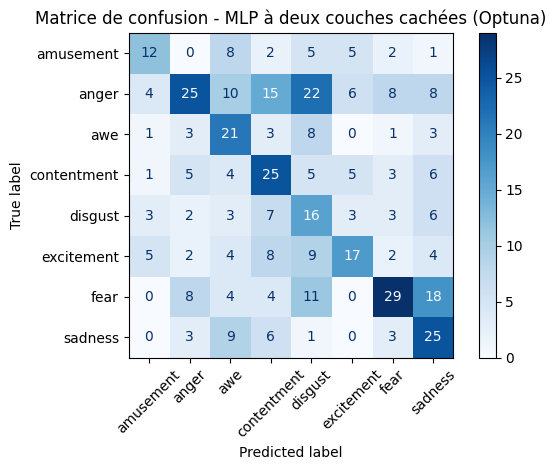

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

noms_emotions = [
    "amusement", "anger", "awe", "contentment",
    "disgust", "excitement", "fear", "sadness"
]

matrice_clip_mlp2= confusion_matrix(
    y_reel_mlp2,
    y_pred_mlp2,
    labels=list(range(8))
)

ConfusionMatrixDisplay(
    confusion_matrix=matrice_clip_mlp2,
    display_labels=noms_emotions
).plot(cmap="Blues", xticks_rotation=45)

plt.title("Matrice de confusion - MLP à deux couches cachées (Optuna)")
plt.tight_layout()
plt.show()


le modèle reconnaît mieux fear (33 clips sur 74), sadness (24 sur 47) et amusement (21 sur 35). En revanche, il a plus de difficultés avec anger et excitement, qu’il confond souvent avec d’autres émotions. La confusion la plus importante concerne anger et disgust, avec 26 clips de anger classés comme disgust

**le modele MLP 2 couches cachés avec Rapport de classification**

In [ ]:
from sklearn.metrics import classification_report
noms_emotions = [
    "amusement", "anger", "awe", "contentment",
    "disgust", "excitement", "fear", "sadness"
]

# Récupérer les prédictions du modèle actuellement
modele.eval()
with torch.no_grad():
    predictions_mlp2 = modele(X_dev).argmax(dim=1)

y_reel_mlp2 = y_dev.detach().cpu().numpy()
y_pred_mlp2 = predictions_mlp2.detach().cpu().numpy()

# Rapport de classification
print("MLP à deux couches cachées (Optuna) — graine 2")
print(classification_report(
    y_reel_mlp2,
    y_pred_mlp2,
    labels=list(range(8)),
    target_names=noms_emotions,
    zero_division=0
))

MLP à deux couches cachées (Optuna) — graine 2
              precision    recall  f1-score   support

   amusement       0.46      0.34      0.39        35
       anger       0.52      0.26      0.34        98
         awe       0.33      0.53      0.41        40
 contentment       0.36      0.46      0.40        54
     disgust       0.21      0.37      0.27        43
  excitement       0.47      0.33      0.39        51
        fear       0.57      0.39      0.46        74
     sadness       0.35      0.53      0.42        47

    accuracy                           0.38       442
   macro avg       0.41      0.40      0.39       442
weighted avg       0.43      0.38      0.39       442



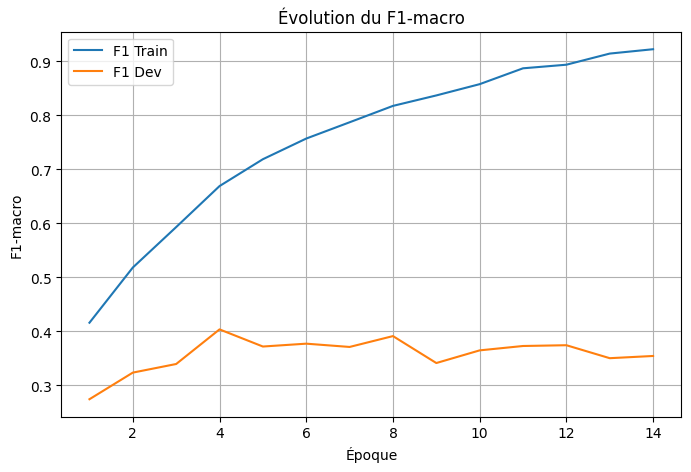

In [ ]:
import matplotlib.pyplot as plt

epoques = range(1, len(historique_f1_train) + 1)

plt.figure(figsize=(8,5))
plt.plot(epoques, historique_f1_train, label="F1 Train")
plt.plot(epoques, historique_f1_dev, label="F1 Dev")
plt.xlabel("Époque")
plt.ylabel("F1-macro")
plt.title("Évolution du F1-macro")
plt.legend()
plt.grid()
plt.show()

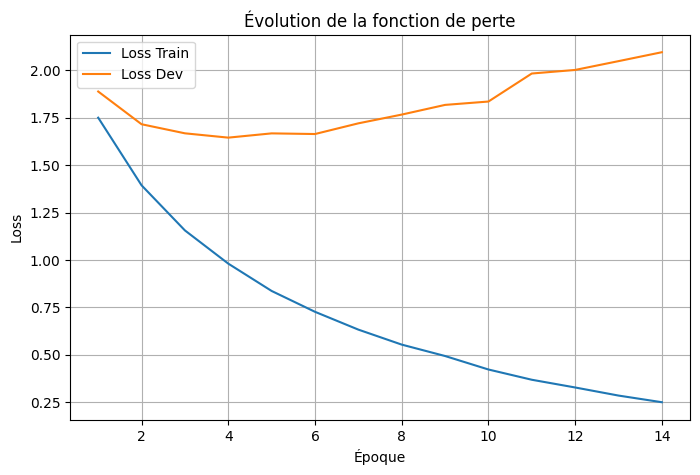

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(epoques, historique_loss_train, label="Loss Train")
plt.plot(epoques, historique_loss_dev, label="Loss Dev")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title("Évolution de la fonction de perte")
plt.legend()
plt.grid()
plt.show()

##Comparaison les deux architectures de MLP

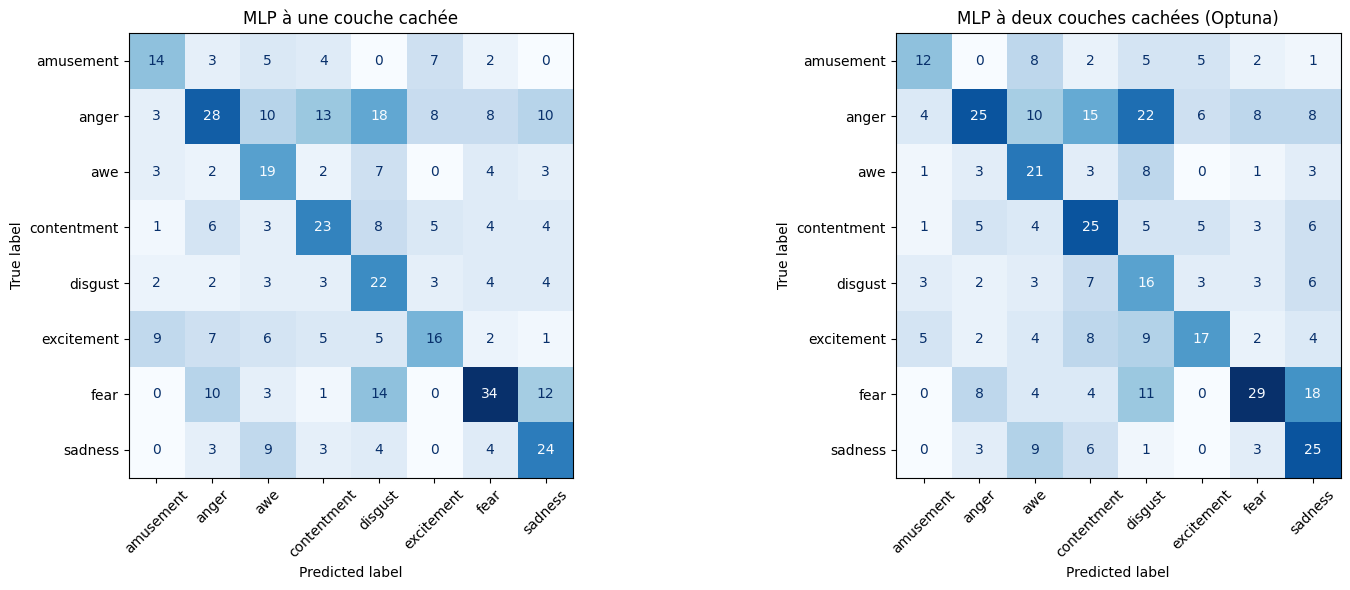

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ConfusionMatrixDisplay(
    confusion_matrix=matrice_clip_mlp,
    display_labels=noms_emotions
).plot(ax=axes[0], cmap="Blues", xticks_rotation=45, colorbar=False)

axes[0].set_title("MLP à une couche cachée")

ConfusionMatrixDisplay(
    confusion_matrix=matrice_clip_mlp2,
    display_labels=noms_emotions
).plot(ax=axes[1], cmap="Blues", xticks_rotation=45, colorbar=False)

axes[1].set_title("MLP à deux couches cachées (Optuna)")

plt.tight_layout()
plt.show()

# Vérifier si images noir ou floue peuvent impacter

In [ ]:
import numpy as np
import pandas as pd
import cv2
from pathlib import Path

dossier_npy = Path("/content/data/extraction_complete/images_npy")
resultats = []

for fichier in sorted(dossier_npy.glob("*.npy")):
    try:
        images = np.load(fichier)

        for numero, image in enumerate(images):
            gris = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
            proportion_sombre = np.mean(gris < 15) * 100
            nettete = cv2.Laplacian(
                gris, cv2.CV_64F
            ).var()

            resultats.append({
                "clip": fichier.stem,
                "image_numero": numero + 1,
                "proportion_sombre_pct": proportion_sombre,
                "nettete": nettete
            })

    except Exception as e:
        print(f"Erreur pour {fichier.name} : {e}")

df_qualite = pd.DataFrame(resultats)

# seuils indicatifs, à confirmer visuellement
df_qualite["presque_noire"] = (
    df_qualite["proportion_sombre_pct"] > 95
)
df_qualite["potentiellement_floue"] = (
    df_qualite["nettete"] < 50
)

print("Nombre de clips :", df_qualite["clip"].nunique())
print("Nombre d'images analysées :", len(df_qualite))
print("Images presque noires :",df_qualite["presque_noire"].sum())
print("Images potentiellement floues :",df_qualite["potentiellement_floue"].sum())

print("Pourcentage presque noires :",round(df_qualite["presque_noire"].mean() * 100, 2), "%")
print("Pourcentage potentiellement floues :",round(df_qualite["potentiellement_floue"].mean() * 100, 2), "%")

display(df_qualite.head())

Nombre de clips : 3088
Nombre d'images analysées : 24704
Images presque noires : 64
Images potentiellement floues : 254
Pourcentage presque noires : 0.26 %
Pourcentage potentiellement floues : 1.03 %


,clip,image_numero,proportion_sombre_pct,nettete,presque_noire,potentiellement_floue
0,00000_clip_001,1,0.008973,284.753083,False,False
1,00000_clip_001,2,0.133480,191.692400,False,False
2,00000_clip_001,3,0.950063,499.512575,False,False
3,00000_clip_001,4,1.079056,388.833545,False,False
4,00000_clip_001,5,0.577665,464.086093,False,False


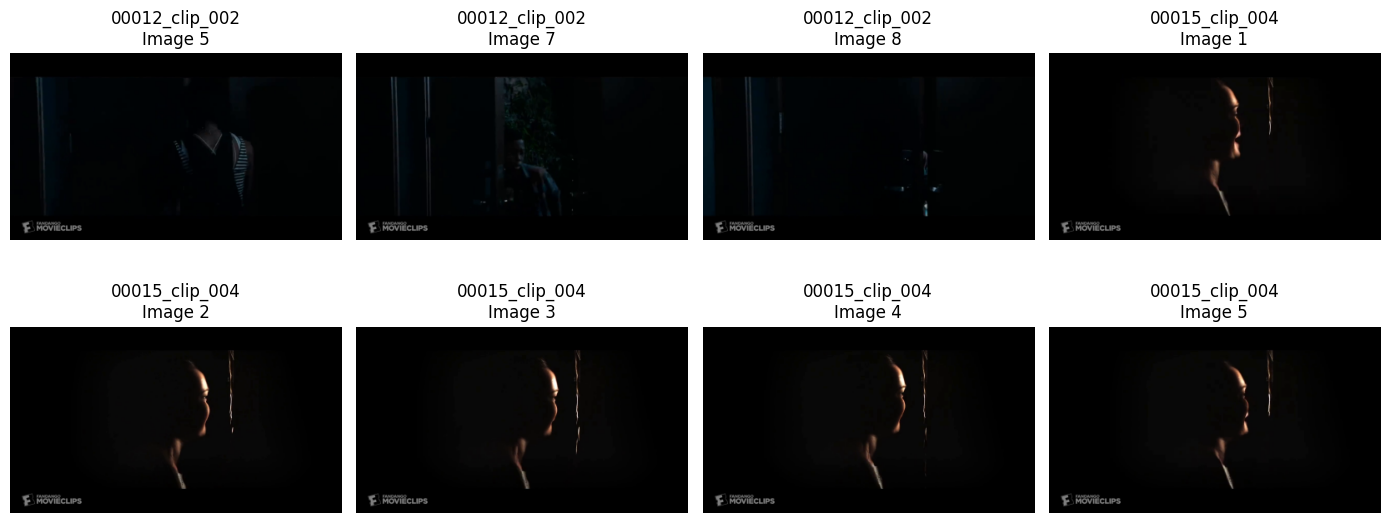

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

noires = df_qualite[df_qualite["presque_noire"]].head(8)

fig, axes = plt.subplots(2, 4, figsize=(14, 6))

for ax, (_, ligne) in zip(axes.flat, noires.iterrows()):
    images = np.load(dossier_npy / f"{ligne['clip']}.npy")
    image = images[int(ligne["image_numero"]) - 1]

    ax.imshow(image)
    ax.set_title(f"{ligne['clip']}\nImage {ligne['image_numero']}")
    ax.axis("off")

for ax in axes.flat[len(noires):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# CLIP avec PCA  et MLP comme classifieur

In [ ]:
X_test_512 = X_video[labels["split"].values == "test", :512]

print("Train :", X_train_512.shape)
print("Dev :", X_dev_512.shape)
print("Test :", X_test_512.shape)

Train : (2207, 512)
Dev : (442, 512)
Test : (439, 512)


In [ ]:
from sklearn.decomposition import PCA

pca_clip = PCA(n_components=128, random_state=42)

X_train_clip_pca = pca_clip.fit_transform(X_train_512)
X_dev_clip_pca = pca_clip.transform(X_dev_512)
X_test_clip_pca = pca_clip.transform(X_test_512)

print("Train après PCA :", X_train_clip_pca.shape)
print("Dev après PCA :", X_dev_clip_pca.shape)
print("Test après PCA :", X_test_clip_pca.shape)

print("Variance expliquée :", round(pca_clip.explained_variance_ratio_.sum() * 100, 2), "%")

Train après PCA : (2207, 128)
Dev après PCA : (442, 128)
Test après PCA : (439, 128)
Variance expliquée : 89.61 %


standardiser les nouvelles données PCA

In [ ]:
scaler_clip_pca = StandardScaler()

X_train_clip_pca_scaled = scaler_clip_pca.fit_transform(X_train_clip_pca)
X_dev_clip_pca_scaled = scaler_clip_pca.transform(X_dev_clip_pca)
X_test_clip_pca_scaled = scaler_clip_pca.transform(X_test_clip_pca)

print("Train :", X_train_clip_pca_scaled.shape)
print("Dev :", X_dev_clip_pca_scaled.shape)
print("Test :", X_test_clip_pca_scaled.shape)

Train : (2207, 128)
Dev : (442, 128)
Test : (439, 128)


Préparer les tenseurs PyTorch

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Encoder les émotions si y_train_encoded n'est pas défini
encodeur = LabelEncoder()
y_train_encoded = encodeur.fit_transform(y_train)
y_dev_encoded = encodeur.transform(y_dev)

X_train_tensor_pca = torch.tensor(
    X_train_clip_pca_scaled, dtype=torch.float32
)
X_dev_tensor_pca = torch.tensor(
    X_dev_clip_pca_scaled, dtype=torch.float32
)
X_test_tensor_pca = torch.tensor(
    X_test_clip_pca_scaled, dtype=torch.float32
)

y_train_tensor = torch.tensor(y_train_encoded, dtype=torch.long)
y_dev_tensor = torch.tensor(y_dev_encoded, dtype=torch.long)

print("Train :", X_train_tensor_pca.shape)
print("Dev :", X_dev_tensor_pca.shape)
print("Test :", X_test_tensor_pca.shape)

Train : torch.Size([2207, 128])
Dev : torch.Size([442, 128])
Test : torch.Size([439, 128])


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset_pca = TensorDataset(
    X_train_tensor_pca, y_train_tensor
)

dev_dataset_pca = TensorDataset(
    X_dev_tensor_pca, y_dev_tensor
)

train_loader_pca = DataLoader(
    train_dataset_pca,
    batch_size=64,
    shuffle=True
)

dev_loader_pca = DataLoader(
    dev_dataset_pca,
    batch_size=64,
    shuffle=False
)

print("Nombre de lots Train :", len(train_loader_pca))
print("Nombre de lots Dev :", len(dev_loader_pca))

Nombre de lots Train : 35
Nombre de lots Dev : 7


MLP adapté à PCA

In [ ]:
import torch.nn as nn

class MLPClipPCA(nn.Module):

    def __init__(self):
        super().__init__()

        self.reseau = nn.Sequential(
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            # nn.Dropout(0.6),
            nn.Linear(128, 8)
        )

    def forward(self, x):
        return self.reseau(x)


modele_clip_pca = MLPClipPCA()

print(modele_clip_pca)

MLPClipPCA(
  (reseau): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=128, out_features=8, bias=True)
  )
)


In [ ]:
fonction_perte_pca = nn.CrossEntropyLoss()

optimiseur_pca = torch.optim.AdamW(
    modele_clip_pca.parameters(),
    lr=0.001,
    #weight_decay=0.01
)

In [ ]:
historique_pca = {
    "train_loss": [],
    "dev_loss": [],
    "train_f1": [],
    "dev_f1": [],
    "train_accuracy": [],
    "dev_accuracy": []
}

meilleur_f1_dev_pca = 0
meilleur_etat_pca = None
meilleure_epoque_pca = 0
compteur_patience_pca = 0
patience_pca = 10

a fonction d'évaluation

In [ ]:
from sklearn.metrics import f1_score, accuracy_score

def evaluer_modele_pca(modele, loader):

    modele.eval()

    pertes = []
    predictions = []
    vraies_valeurs = []

    with torch.no_grad():
        for X_batch, y_batch in loader:

            sorties = modele(X_batch)

            perte = fonction_perte_pca(sorties, y_batch)
            pertes.append(perte.item())

            predictions.extend(
                torch.argmax(sorties, dim=1).numpy()
            )

            vraies_valeurs.extend(
                y_batch.numpy()
            )

    perte_moyenne = np.mean(pertes)

    f1 = f1_score(
        vraies_valeurs,
        predictions,
        average="macro"
    )

    accuracy = accuracy_score(
        vraies_valeurs,
        predictions
    )

    return perte_moyenne, f1, accuracy

fonction d'entraînement

In [ ]:
def entrainer_modele_pca(modele, train_loader, dev_loader, nb_epochs=200):

    meilleur_f1 = 0
    meilleur_etat = None
    meilleure_epoque = 0
    compteur_patience = 0

    for epoque in range(1, nb_epochs + 1):

        modele.train()
        pertes_train = []

        for X_batch, y_batch in train_loader:

            optimiseur_pca.zero_grad()

            sorties = modele(X_batch)
            perte = fonction_perte_pca(sorties, y_batch)

            perte.backward()
            optimiseur_pca.step()

            pertes_train.append(perte.item())

        perte_train = np.mean(pertes_train)

        _, f1_train, accuracy_train = evaluer_modele_pca(
            modele, train_loader
        )

        perte_dev, f1_dev, accuracy_dev = evaluer_modele_pca(
            modele, dev_loader
        )

        historique_pca["train_loss"].append(perte_train)
        historique_pca["dev_loss"].append(perte_dev)

        historique_pca["train_f1"].append(f1_train)
        historique_pca["dev_f1"].append(f1_dev)

        historique_pca["train_accuracy"].append(accuracy_train)
        historique_pca["dev_accuracy"].append(accuracy_dev)

        if f1_dev > meilleur_f1:
            meilleur_f1 = f1_dev
            meilleur_etat = copy.deepcopy(modele.state_dict())
            meilleure_epoque = epoque
            compteur_patience = 0
        else:
            compteur_patience += 1

        print(
            f"Époque {epoque:03d} | "
            f"Train Loss: {perte_train:.4f} | "
            f"Dev Loss: {perte_dev:.4f} | "
            f"Train F1: {f1_train:.4f} | "
            f"Dev F1: {f1_dev:.4f} | "
            f"Train Acc: {accuracy_train:.4f} | "
            f"Dev Acc: {accuracy_dev:.4f}"
        )

        if compteur_patience >= patience_pca:
            print("\nEarly Stopping déclenché.")
            break

    modele.load_state_dict(meilleur_etat)

    print("\nMeilleure époque :", meilleure_epoque)
    print("Meilleur F1-macro Dev :", round(meilleur_f1, 4))

    return modele


Entrainer  CLIP MLP avce PCA

In [ ]:
import copy

modele_clip_pca = entrainer_modele_pca(
    modele_clip_pca,
    train_loader_pca,
    dev_loader_pca,
    nb_epochs=200
)

Époque 001 | Train Loss: 0.6424 | Dev Loss: 1.9551 | Train F1: 0.8948 | Dev F1: 0.3626 | Train Acc: 0.8926 | Dev Acc: 0.3665
Époque 002 | Train Loss: 0.6009 | Dev Loss: 1.9676 | Train F1: 0.9010 | Dev F1: 0.3567 | Train Acc: 0.8981 | Dev Acc: 0.3597
Époque 003 | Train Loss: 0.5918 | Dev Loss: 1.9597 | Train F1: 0.9024 | Dev F1: 0.3659 | Train Acc: 0.9008 | Dev Acc: 0.3688
Époque 004 | Train Loss: 0.5806 | Dev Loss: 1.9772 | Train F1: 0.9099 | Dev F1: 0.3682 | Train Acc: 0.9076 | Dev Acc: 0.3710
Époque 005 | Train Loss: 0.5874 | Dev Loss: 2.0045 | Train F1: 0.9181 | Dev F1: 0.3681 | Train Acc: 0.9153 | Dev Acc: 0.3710
Époque 006 | Train Loss: 0.5736 | Dev Loss: 2.0176 | Train F1: 0.9199 | Dev F1: 0.3599 | Train Acc: 0.9175 | Dev Acc: 0.3643
Époque 007 | Train Loss: 0.5451 | Dev Loss: 2.0295 | Train F1: 0.9271 | Dev F1: 0.3541 | Train Acc: 0.9239 | Dev Acc: 0.3597
Époque 008 | Train Loss: 0.5620 | Dev Loss: 2.0337 | Train F1: 0.9316 | Dev F1: 0.3553 | Train Acc: 0.9289 | Dev Acc: 0.3575


In [ ]:
from sklearn.metrics import accuracy_score

modele_clip_pca.eval()

predictions = []
vraies_valeurs = []

with torch.no_grad():
    for X_batch, y_batch in dev_loader_pca:

        sorties = modele_clip_pca(X_batch)

        predictions.extend(
            torch.argmax(sorties, dim=1).numpy()
        )

        vraies_valeurs.extend(
            y_batch.numpy()
        )

accuracy = accuracy_score(
    vraies_valeurs,
    predictions
)

print("Accuracy Dev :", round(accuracy, 4))

Accuracy Dev : 0.371


In [ ]:
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score

def evaluer_modele_pca(modele, loader):

    modele.eval()

    pertes = []
    y_true = []
    y_pred = []

    with torch.no_grad():
        for X_batch, y_batch in loader:

            sorties = modele(X_batch)
            perte = fonction_perte_pca(sorties, y_batch)

            pertes.append(perte.item())

            predictions = sorties.argmax(dim=1)

            y_true.extend(y_batch.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    perte_moyenne = np.mean(pertes)
    f1 = f1_score(y_true, y_pred, average="macro")
    accuracy = accuracy_score(y_true, y_pred)


    return perte_moyenne, f1, accuracy,

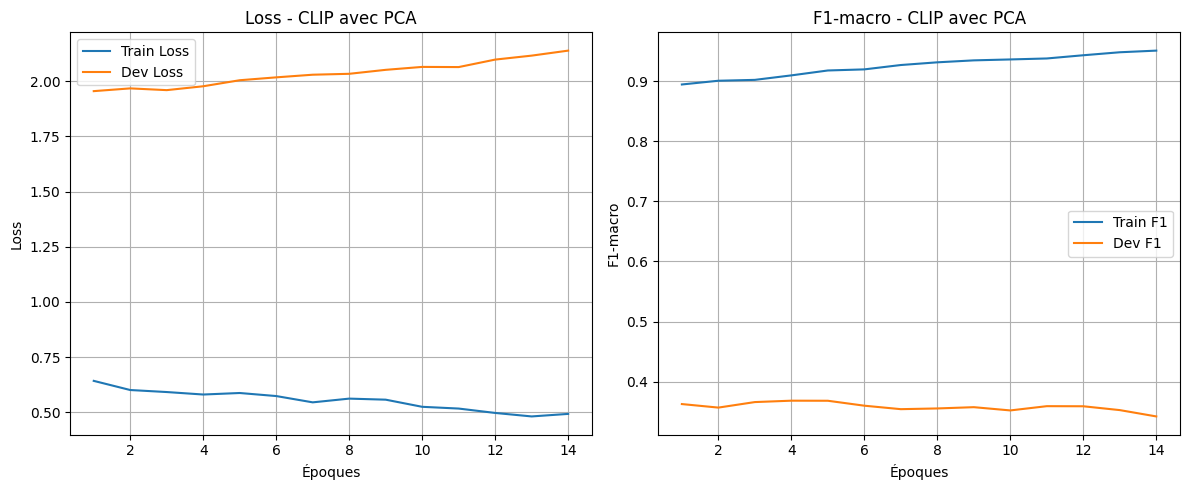

In [ ]:
import matplotlib.pyplot as plt

epoques = range(1, len(historique_pca["train_loss"]) + 1)

plt.figure(figsize=(12, 5))

# Courbe des Loss
plt.subplot(1, 2, 1)
plt.plot(epoques, historique_pca["train_loss"], label="Train Loss")
plt.plot(epoques, historique_pca["dev_loss"], label="Dev Loss")
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Loss - CLIP avec PCA")
plt.legend()
plt.grid()

# Courbe des F1-macro
plt.subplot(1, 2, 2)
plt.plot(epoques, historique_pca["train_f1"], label="Train F1")
plt.plot(epoques, historique_pca["dev_f1"], label="Dev F1")
plt.xlabel("Époques")
plt.ylabel("F1-macro")
plt.title("F1-macro - CLIP avec PCA")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# ResNet-18

## charge les données et prépare pour extraire les caractéristiques des images.

In [ ]:
import torch
import numpy as np
import pandas as pd
from pathlib import Path

base = Path("/content/data")

dossier_images = base / "extraction_complete/images_npy"
fichier_labels = dossier_features / "labels_partitions.csv"

labels = pd.read_csv(fichier_labels, dtype=str)

print("Nombre de clips :", len(labels))
print("Dossier des images présent :", dossier_images.exists())

In [ ]:
from torchvision.models import resnet18, ResNet18_Weights

In [ ]:
#charger ResNet-18
resnet = resnet18(weights=ResNet18_Weights.DEFAULT)
resnet.eval()
for param in resnet.parameters():
    param.requires_grad = False

#l'extracteur de caractéristiques
resnet = torch.nn.Sequential(*list(resnet.children())[:-1])
print("ResNet-18 okk")

Nombre de clips : 3088
Dossier des images présent : True
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 139MB/s]


ResNet-18 okk


tester ResNet-18 sur une seule vidéo

In [ ]:
# poids = ResNet18_Weights.DEFAULT
# transformer = poids.transforms()

# video_id = labels.iloc[0]["video_id"]
# images = np.load(dossier_images / f"{video_id}.npy")

# images_tensor = torch.stack([
#     transformer(torch.from_numpy(image).permute(2, 0, 1))
#     for image in images
# ])

# with torch.no_grad():
#     caracteristiques = resnet(images_tensor)

# print("vidéo :", video_id)
# print("forme :", caracteristiques.shape)

vidéo : 00000_clip_001
forme : torch.Size([8, 512, 1, 1])


extraire les caractéristiques de tous les clips

In [ ]:
dossier_resnet = base / "features_baseline" / "resnet_batches"
dossier_resnet.mkdir(parents=True, exist_ok=True)

# traiter les vidéos par lots de 50
for debut in range(0, len(labels), 50):
    lot = labels.iloc[debut:debut + 50]
    ids = []
    features = []

    # parcourir les vidéos du lot
    for video_id in lot["video_id"]:
        images = np.load(dossier_images / f"{video_id}.npy")

        # préparer les 8 images
        images_tensor = torch.stack([
            transformer(torch.from_numpy(image).permute(2, 0, 1))
            for image in images
        ])

        # extraire les caractéristiques avec resnet
        with torch.no_grad():
            sortie = resnet(images_tensor)

        features.append(
            sortie.squeeze(-1).squeeze(-1).mean(dim=0).numpy()
        )
        ids.append(video_id)

    # sauvegarder les caractéristiques du lot
    np.savez(
        dossier_resnet / f"resnet_batch_{debut // 50:04d}.npz",
        ids=np.array(ids),
        features=np.array(features, dtype=np.float32)
    )
    print("lot terminé :", min(debut + 50, len(labels)), "/", len(labels))

lot terminé : 50 / 3088
lot terminé : 100 / 3088
lot terminé : 150 / 3088
lot terminé : 200 / 3088
lot terminé : 250 / 3088
lot terminé : 300 / 3088
lot terminé : 350 / 3088
lot terminé : 400 / 3088
lot terminé : 450 / 3088
lot terminé : 500 / 3088
lot terminé : 550 / 3088
lot terminé : 600 / 3088
lot terminé : 650 / 3088
lot terminé : 700 / 3088
lot terminé : 750 / 3088
lot terminé : 800 / 3088
lot terminé : 850 / 3088
lot terminé : 900 / 3088
lot terminé : 950 / 3088
lot terminé : 1000 / 3088
lot terminé : 1050 / 3088
lot terminé : 1100 / 3088
lot terminé : 1150 / 3088
lot terminé : 1200 / 3088
lot terminé : 1250 / 3088
lot terminé : 1300 / 3088
lot terminé : 1350 / 3088
lot terminé : 1400 / 3088
lot terminé : 1450 / 3088
lot terminé : 1500 / 3088
lot terminé : 1550 / 3088
lot terminé : 1600 / 3088
lot terminé : 1650 / 3088
lot terminé : 1700 / 3088
lot terminé : 1750 / 3088
lot terminé : 1800 / 3088
lot terminé : 1850 / 3088
lot terminé : 1900 / 3088
lot terminé : 1950 / 3088
lot te

vérifier les caractéristiques sauvegardées

In [ ]:
# charger les lots
fichiers = sorted(dossier_resnet.glob("resnet_batch_*.npz"))

ids = []
features = []

# regrouper les caractéristiques
for fichier in fichiers:
    lot = np.load(fichier)
    ids.extend(lot["ids"].tolist())
    features.extend(lot["features"])

ids = np.array(ids)
features = np.array(features, dtype=np.float32)

print("nombre de lots :", len(fichiers))
print("nombre de clips :", len(ids))
print("forme des caractéristiques :", features.shape)
print("identifiants uniques :", len(set(ids)))
print("valeurs manquantes :", np.isnan(features).sum())
print("tous les clips sont présents :", set(ids) == set(labels["video_id"]))

np.save(base / "features_baseline" / "X_video_resnet_mean.npy", features)
np.save(base / "features_baseline" / "ids_video_resnet.npy", ids)

print("sauvegarde terminée")

vérification des caractéristiques resnet

In [ ]:
X = np.load(base / "features_baseline" / "X_video_resnet_mean.npy")
ids = np.load(base / "features_baseline" / "ids_video_resnet.npy")
donnees = labels.set_index("video_id").loc[ids].reset_index()
print("forme de X :", X.shape)
print("nombre de labels :", len(donnees))
print(donnees["split"].value_counts())
print(donnees["emotion"].value_counts())

##entraîner la régression logistique avec resnet

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X_train = X[donnees["split"].values == "train"]
y_train = donnees.loc[donnees["split"] == "train", "emotion"]
X_dev = X[donnees["split"].values == "dev"]
y_dev = donnees.loc[donnees["split"] == "dev", "emotion"]
modele_resnet = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)
modele_resnet.fit(X_train, y_train)
predictions = modele_resnet.predict(X_dev)
print("accuracy :", accuracy_score(y_dev, predictions))
print("f1 macro :", f1_score(y_dev, predictions, average="macro"))
print(classification_report(y_dev, predictions, zero_division=0))

## ResNet avec MLP

In [ ]:
# charger les caracteristiques resnet
X = np.load(base / "features_baseline" / "X_video_resnet_mean.npy")
ids = np.load(base / "features_baseline" / "ids_video_resnet.npy")

donnees = labels.set_index("video_id").loc[ids].reset_index()

X_train = X[donnees["split"] == "train"]
X_dev = X[donnees["split"] == "dev"]

y_train = donnees.loc[donnees["split"] == "train", "emotion"]
y_dev = donnees.loc[donnees["split"] == "dev", "emotion"]

# normaliser les caracteristiqes
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_dev = scaler.transform(X_dev)

# convertir en tenseurs
encodeur = LabelEncoder().fit(classes)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_dev = torch.tensor(X_dev, dtype=torch.float32)
y_train = torch.tensor(encodeur.transform(y_train), dtype=torch.long)
y_dev = torch.tensor(encodeur.transform(y_dev), dtype=torch.long)
print(X_train.shape, X_dev.shape)

In [ ]:
import torch.nn as nn

mlp = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 8)
)

poids = len(y_train) / (8 * torch.bincount(y_train))
critere = nn.CrossEntropyLoss(weight=poids)
optimiseur = torch.optim.AdamW(mlp.parameters(), lr=0.001, weight_decay=0.01)

In [ ]:
from sklearn.metrics import f1_score

meilleur_f1 = 0
patience = 0

for epoque in range(200):
    mlp.train()
    permutation = torch.randperm(len(X_train))

    for i in range(0, len(X_train), 64):
        idx = permutation[i:i+64]

        optimiseur.zero_grad()
        perte = critere(mlp(X_train[idx]), y_train[idx])
        perte.backward()
        optimiseur.step()

    mlp.eval()
    with torch.no_grad():
        pred = mlp(X_dev).argmax(dim=1)

    f1 = f1_score(y_dev.numpy(), pred.numpy(), average="macro")

    if f1 > meilleur_f1:
        meilleur_f1 = f1
        meilleur_etat = {k: v.clone() for k, v in mlp.state_dict().items()}
        patience = 0
    else:
        patience += 1

    if patience == 10:
        break

mlp.load_state_dict(meilleur_etat)

print("Nombre d'epoques :", epoque + 1)
print("F1 macro sur dev :", round(meilleur_f1, 4))

 ## Combine lescaractéristiques CLIP avec caractéristiques visuelles classiques

Les deux présentations

In [ ]:
import numpy as np
colonnes_clip = list(range(1024))
X_clip = df_embeddings[colonnes_clip].to_numpy(dtype=np.float32)
X_classique = np.load(
    dossier_sortie / "X_video_baseline.npy"
).astype(np.float32)

print("CLIP :", X_clip.shape)
print("Caractéristiques classiques :", X_classique.shape)

Combiner les caractéristiques

In [ ]:
from sklearn.preprocessing import StandardScaler

# Normaliser les caractéristiques classiques
normaliseur = StandardScaler()
X_classique_norm = normaliseur.fit_transform(
    X_classique[splits == "train"]
)

X_train_clip = X_clip[splits == "train"]
X_dev_clip = X_clip[splits == "dev"]

X_train_classique = X_classique_norm
X_dev_classique = normaliseur.transform(
    X_classique[splits == "dev"]
)

X_train_combine = np.concatenate(
    [X_train_clip, X_train_classique], axis=1
)
X_dev_combine = np.concatenate(
    [X_dev_clip, X_dev_classique], axis=1
)
print("Train combiné :", X_train_combine.shape)
print("Dev combiné :", X_dev_combine.shape)

In [ ]:
from sklearn.preprocessing import LabelEncoder

encodage = LabelEncoder()
encodage.fit(y)

y_train_num = encodage.transform(y[splits == "train"])
y_dev_num = encodage.transform(y[splits == "dev"])

## Entraîner le MLP combiné

In [ ]:
import torch
import torch.nn as nn
from sklearn.metrics import f1_score

entree = torch.tensor(X_train_combine, dtype=torch.float32)
validation = torch.tensor(X_dev_combine, dtype=torch.float32)

cibles = torch.tensor(y_train_num, dtype=torch.long)

reseau = nn.Sequential(
    nn.Linear(1165, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 8)
)

optim = torch.optim.Adam(reseau.parameters(), lr=0.001)
fonction_perte = nn.CrossEntropyLoss()

meilleur_score = 0
meilleur_tour = 0
meilleurs_poids = None

for tour in range(30):
    reseau.train()
    optim.zero_grad()

    resultat = reseau(entree)
    erreur = fonction_perte(resultat, cibles)
    erreur.backward()
    optim.step()

    reseau.eval()
    with torch.no_grad():
        choix = reseau(validation).argmax(dim=1).numpy()

    score = f1_score(y_dev_num, choix, average="macro")

    if score > meilleur_score:
        meilleur_score = score
        meilleur_tour = tour + 1
        meilleurs_poids = {
            nom: poids.clone()
            for nom, poids in reseau.state_dict().items()
        }

    if (tour + 1) % 5 == 0:
        print(f"Tour {tour + 1} : F1-macro = {score:.4f}")

reseau.load_state_dict(meilleurs_poids)

print("\nMeilleur F1-macro :", round(meilleur_score, 4))
print("Meilleure époque :", meilleur_tour)

améliorer la classification des 8 émotions à partir des vidéos, en utilisant les embeddings CLIP déjà calculés.

In [ ]:
print("df_videos :", df_videos.shape)
print(df_videos.columns.tolist())
print("\ndf_qualite :", df_qualite.shape)
print(df_qualite.columns.tolist())
print("\ndf_embeddings :", df_embeddings.shape)
print(df_embeddings.columns.tolist())

In [ ]:
print("Forme de X_video :", X_video.shape)
print("Forme de X_train_512 :", X_train_512.shape)
print("Forme de X_dev_512 :", X_dev_512.shape)
print("\nForme des embeddings CLIP :")
print(df_embeddings.shape)

tester si les 135 caractéristiques visuelles complémentaires améliorent les performances du MLP.

In [ ]:
import numpy as np
import pandas as pd

# Charger les caractéristiques classiques déjà sauvegardées
X_baseline = np.load(
    dossier_sortie / "X_video_baseline.npy"
)

# Récupérer les étiquettes et les partitions
y = df_baseline["emotion"].to_numpy()
splits = df_baseline["split"].to_numpy()

# Séparer train, dev et test
X_train_base = X_baseline[splits == "train"]
y_train_base = y[splits == "train"]

X_dev_base = X_baseline[splits == "dev"]
y_dev_base = y[splits == "dev"]

print("Train :", X_train_base.shape, y_train_base.shape)
print("Dev   :", X_dev_base.shape, y_dev_base.shape)
print("Test conservé à part :", (splits == "test").sum())
print("Valeurs finies :", np.isfinite(X_baseline).all())

# ViT-Face-Expression

## Preparation et extraction

In [ ]:
!pip install -q transformers timm

In [ ]:
from transformers import AutoImageProcessor, AutoModelForImageClassification

nom_modele = "trpakov/vit-face-expression"

processeur = AutoImageProcessor.from_pretrained(nom_modele)
modele_face = AutoModelForImageClassification.from_pretrained(nom_modele)

print("Modèle chargé avec succès !")
print("Nombre de classes :", modele_face.config.num_labels)
print("Classes :", modele_face.config.id2label)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Modèle chargé avec succès !
Nombre de classes : 7
Classes : {0: 'angry', 1: 'disgust', 2: 'fear', 3: 'happy', 4: 'neutral', 5: 'sad', 6: 'surprise'}


In [ ]:
print(modele_face)

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (o_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layernorm_before): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (layernorm_after): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (mlp): ViTMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear(in_features=3072, out

In [ ]:
print("Type du modèle :", type(modele_face))
print("Configuration :", modele_face.config)

Type du modèle : <class 'transformers.models.vit.modeling_vit.ViTForImageClassification'>
Configuration : ViTConfig {
  "architectures": [
    "ViTForImageClassification"
  ],
  "attention_probs_dropout_prob": 0.0,
  "dtype": "float32",
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "id2label": {
    "0": "angry",
    "1": "disgust",
    "2": "fear",
    "3": "happy",
    "4": "neutral",
    "5": "sad",
    "6": "surprise"
  },
  "image_size": 224,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "label2id": {
    "angry": "0",
    "disgust": "1",
    "fear": "2",
    "happy": "3",
    "neutral": "4",
    "sad": "5",
    "surprise": "6"
  },
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "pooler_act": "tanh",
  "pooler_output_size": 768,
  "problem_type": "single_label_classification",
  "qkv_bias": true,
  "transformers

In [ ]:
import torch
import numpy as np
import pandas as pd
import time
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

modele_face = modele_face.to(device)
modele_face.eval()

print("Appareil utilisé :", device)

Appareil utilisé : cpu


Extraire les embeddings des 3 088 vidéos



Préparer les dossiers

In [ ]:
from pathlib import Path

dossier_features_face = Path(
    "/content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/features_vit_face"
)

dossier_lots_face = dossier_features_face / "clip_batches"

dossier_lots_face.mkdir(parents=True, exist_ok=True)

print("Dossier créé :", dossier_lots_face.exists())

Dossier créé : True


In [ ]:
embeddings_vit = []
ids_videos_vit = []

debut = time.time()

for video in videos_test:

    video_id = str(video["video_id"])

    chemin = os.path.join(dossier_npy, video_id + ".npy")

    images = np.load(chemin)

    images_pil = [
        Image.fromarray(images[i])
        for i in range(8)
    ]

    entree = processeur(
        images=images_pil,
        return_tensors="pt"
    )

    entree = {
        cle: valeur.to(device)
        for cle, valeur in entree.items()
    }

    with torch.no_grad():
        sortie = modele_face.vit(**entree)

    emb_frames = sortie.last_hidden_state[:, 0, :]

    moyenne = emb_frames.mean(dim=0)
    ecart_type = emb_frames.std(dim=0)

    embedding_video = torch.cat([moyenne, ecart_type])

    embeddings_vit.append(embedding_video.cpu().numpy())
    ids_videos_vit.append(video_id)

    print("Vidéo terminée :", video_id)

embeddings_vit = np.array(embeddings_vit)

print("\nDimensions finales :", embeddings_vit.shape)
print("Temps total :", round((time.time() - debut) / 60, 2), "minutes")

In [ ]:
# print("Forme :", embeddings_vit.shape)
# print("Valeurs NaN :", np.isnan(embeddings_vit).sum())
# print("Valeurs infinies :", np.isinf(embeddings_vit).sum())

In [ ]:
np.save("test_embeddings_vit_face_10.npy", embeddings_vit)

In [ ]:
chemin_test_vit = dossier_features_face / "test_embeddings_vit_face_10.npy"

np.save(chemin_test_vit, embeddings_vit)

print("Fichier sauvegardé :", chemin_test_vit)
print("Dimensions :", np.load(chemin_test_vit).shape)

Fichier sauvegardé : /content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Video/features_vit_face/test_embeddings_vit_face_10.npy
Dimensions : (0,)


In [ ]:
print("Dossier CLIP :", dossier_features.exists())
print("Contenu du dossier :")

for fichier in sorted(dossier_features.iterdir())[:15]:
    print(fichier.name)

Dossier CLIP : True
Contenu du dossier :
X_video_baseline.npy
X_video_meanstd.npy
X_video_resnet_mean.npy
clip_batches
clip_videos_recuperees.npz
ids_video_resnet.npy
labels_partitions.csv
mlp_video_final.pth
noms_caracteristiques.csv
resnet_batches


Préparer les identifiants des vidéos

In [ ]:
import pandas as pd

fichier_labels = dossier_features / "labels_partitions.csv"

labels = pd.read_csv(fichier_labels, dtype=str)
ids_videos = labels["video_id"].tolist()

print("Nombre de vidéos :", len(ids_videos))


Nombre de vidéos : 3088


Extraction par lots

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
modele_face.to(device)

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0-11): 12 x ViTLayer(
        (attention): ViTAttention(
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (o_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layernorm_before): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (layernorm_after): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (mlp): ViTMLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear(in_features=3072, out

In [ ]:
import numpy as np
import torch
from PIL import Image

modele_face.eval()

taille_lot = 50
nb_videos = len(ids_videos)

for debut in range(0, nb_videos, taille_lot):

    fin = min(debut + taille_lot, nb_videos)

    fichier_lot = dossier_lots_face / f"clip_batch_{debut//taille_lot:03d}.npz"

    if fichier_lot.exists():
        print(f"Lot {debut//taille_lot + 1} déjà traité.")
        continue

    embeddings_lot = []
    ids_lot = []

    for video_id in ids_videos[debut:fin]:

        chemin = dossier_npy / f"{video_id}.npy"

        if not chemin.exists():
            print("Fichier absent :", video_id)
            continue

        images = np.load(chemin)

        embeddings_frames = []

        for i in range(len(images)):

            image = Image.fromarray(images[i])
            entree = processeur(images=image, return_tensors="pt")

            # Résolution de l'erreur : Envoyer les données d'entrée sur le même appareil (GPU) que le modèle
            entree = {cle: valeur.to(device) for cle, valeur in entree.items()}

            with torch.no_grad():
                sortie = modele_face.vit(**entree)

            embedding = sortie.last_hidden_state[:, 0, :]
            embeddings_frames.append(embedding.squeeze(0))

        embeddings_frames = torch.stack(embeddings_frames)

        embedding_mean = embeddings_frames.mean(dim=0)
        embedding_std = embeddings_frames.std(dim=0)

        embedding_video = torch.cat(
            [embedding_mean, embedding_std]
        )

        embeddings_lot.append(embedding_video.cpu().numpy())
        ids_lot.append(video_id)

    np.savez_compressed(
        fichier_lot,
        embeddings=np.array(embeddings_lot),
        video_ids=np.array(ids_lot)
    )

    print(
        f"Lot {debut//taille_lot + 1} terminé : "
        f"{len(embeddings_lot)} vidéos réussies."
    )

Lot 1 déjà traité.
Lot 2 déjà traité.
Lot 3 déjà traité.
Lot 4 déjà traité.
Lot 5 déjà traité.
Lot 6 déjà traité.
Lot 7 déjà traité.
Lot 8 déjà traité.
Lot 9 déjà traité.
Lot 10 déjà traité.
Lot 11 déjà traité.
Lot 12 déjà traité.
Lot 13 déjà traité.
Lot 14 déjà traité.
Lot 15 déjà traité.
Lot 16 déjà traité.
Lot 17 déjà traité.
Lot 18 déjà traité.
Lot 19 déjà traité.
Lot 20 déjà traité.
Lot 21 déjà traité.
Lot 22 déjà traité.
Lot 23 déjà traité.
Lot 24 déjà traité.
Lot 25 déjà traité.
Lot 26 déjà traité.
Lot 27 déjà traité.
Lot 28 déjà traité.
Lot 29 déjà traité.
Lot 30 déjà traité.
Lot 31 déjà traité.
Lot 32 déjà traité.
Lot 33 déjà traité.
Lot 34 déjà traité.
Lot 35 déjà traité.
Lot 36 déjà traité.
Lot 37 déjà traité.
Lot 38 déjà traité.
Lot 39 déjà traité.
Lot 40 déjà traité.
Lot 41 déjà traité.
Lot 42 déjà traité.
Lot 43 déjà traité.
Lot 44 déjà traité.
Lot 45 déjà traité.
Lot 46 déjà traité.
Lot 47 déjà traité.
Lot 48 déjà traité.
Lot 49 déjà traité.
Lot 50 déjà traité.
Lot 51 dé

In [ ]:
for fichier in sorted(dossier_lots_face.glob("clip_batch_*.npz")):
    with np.load(fichier) as data:
        print(
            fichier.name,
            "| Embeddings :", data["embeddings"].shape,
            "| Vidéos :", len(data["video_ids"])
        )

clip_batch_000.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_001.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_002.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_003.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_004.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_005.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_006.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_007.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_008.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_009.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_010.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_011.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_012.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_013.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_014.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_015.npz | Embeddings : (50, 1536) | Vidéos : 50
clip_batch_016.npz | Embeddings : (50, 1536) | Vidéos : 

In [ ]:
from pathlib import Path

fichiers = list(dossier_lots_face.glob("clip_batch_*.npz"))

lots_presents = {
    int(f.stem.split("_")[-1])
    for f in fichiers
}

lots_manquants = [
    i for i in range(62)
    if i not in lots_presents
]

print("Lots présents :", len(lots_presents))
print("Lots manquants :", lots_manquants)

Lots présents : 62
Lots manquants : []


tous les embeddings dans une seule matrice

In [ ]:
import numpy as np
from pathlib import Path

# Dossier contenant les 62 lots
dossier_lots = Path(dossier_lots_face)

# Récupération des fichiers dans le bon ordre
fichiers_lots = sorted(dossier_lots.glob("clip_batch_*.npz"))

embeddings_liste = []
ids_liste = []

# Fusion des lots
for fichier in fichiers_lots:
    data = np.load(fichier, allow_pickle=True)

    # Récupération des noms des tableaux
    print(fichier.name, data.files) if fichier == fichiers_lots[0] else None

    # À adapter aux noms réellement présents dans les fichiers
    embeddings_liste.append(data["embeddings"])
    ids_liste.extend(data["video_ids"])

X_vit = np.concatenate(embeddings_liste, axis=0)
ids_videos = np.array(ids_liste)

print("Nombre de lots :", len(fichiers_lots))
print("Dimensions de X_vit :", X_vit.shape)
print("Nombre d'identifiants :", len(ids_videos))
print("Identifiants uniques :", len(np.unique(ids_videos)))
print("Valeurs manquantes :", np.isnan(X_vit).sum())

clip_batch_000.npz ['embeddings', 'video_ids']
Nombre de lots : 62
Dimensions de X_vit : (3088, 1536)
Nombre d'identifiants : 3088
Identifiants uniques : 3088
Valeurs manquantes : 0


Partitions FaceVit

In [ ]:
#Créer le dictionnaire des embeddings
embeddings_face = {
    str(video_id): embedding
    for video_id, embedding in zip(ids_videos, X_vit)
}

print("Nombre d'embeddings :", len(embeddings_face))

# Copier les informations des vidéos
df_face = df_videos.copy()
df_face["video_id"] = df_face["video_id"].astype(str)

#Récupérer les émotions si nécessaire
if "emotion" not in df_face.columns:
    labels["video_id"] = labels["video_id"].astype(str)

    df_face = df_face.merge(
        labels[["video_id", "emotion"]],
        on="video_id",
        how="left"
    )

# Vérifier les embeddings manquants
ids_absents = [
    video_id for video_id in df_face["video_id"]
    if video_id not in embeddings_face
]

print("Vidéos sans embedding :", len(ids_absents))

#les embeddings
df_face["embedding"] = df_face["video_id"].map(embeddings_face)

# Vérifier les données manquantes
print("Emotions manquantes :", df_face["emotion"].isna().sum())
print("Embeddings manquants :", df_face["embedding"].isna().sum())

# Construire les partitions
def preparer_partition(nom_split):
    subset = df_face[df_face["split"] == nom_split].copy()

    X = np.stack(subset["embedding"].values)
    y = subset["emotion"].values
    ids = subset["video_id"].values

    return X, y, ids

#Train, Dev et Test
X_train_face, y_train_face, ids_train_face = preparer_partition("train")
X_dev_face, y_dev_face, ids_dev_face = preparer_partition("dev")
X_test_face, y_test_face, ids_test_face = preparer_partition("test")

# 8. Afficher les dimensions
print("\nDimensions des partitions FaceViT :")
print("Train :", X_train_face.shape, y_train_face.shape)
print("Dev   :", X_dev_face.shape, y_dev_face.shape)
print("Test  :", X_test_face.shape, y_test_face.shape)

print("\nNombre total de vidéos :",
      len(ids_train_face) + len(ids_dev_face) + len(ids_test_face))

Nombre d'embeddings : 3088
Vidéos sans embedding : 0
Emotions manquantes : 0
Embeddings manquants : 0

Dimensions des partitions FaceViT :
Train : (2207, 1536) (2207,)
Dev   : (442, 1536) (442,)
Test  : (439, 1536) (439,)

Nombre total de vidéos : 3088


In [ ]:
from sklearn.preprocessing import StandardScaler

# Normalisation avec les données Train uniquement
scaler_face = StandardScaler()

X_train_face_scaled = scaler_face.fit_transform(X_train_face)
X_dev_face_scaled = scaler_face.transform(X_dev_face)
X_test_face_scaled = scaler_face.transform(X_test_face)

print("Train :", X_train_face_scaled.shape)
print("Dev :", X_dev_face_scaled.shape)
print("Test :", X_test_face_scaled.shape)

Train : (2207, 1536)
Dev : (442, 1536)
Test : (439, 1536)


## Entraîner le classifieur FaceViT Regression logistique

Trouver les hyperparametres

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
valeurs_C = [0.0005, 0.001, 0.003, 0.01]

resultats_face = []

for C in valeurs_C:

    modele = LogisticRegression(
        C=C,
        solver="saga",
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )

    modele.fit(X_train_face_scaled, y_train_face)

    predictions = modele.predict(X_dev_face_scaled)

    accuracy = accuracy_score(y_dev_face, predictions)
    f1 = f1_score(y_dev_face, predictions, average="macro")

    resultats_face.append({
        "C": C,
        "Accuracy Dev": accuracy,
        "F1-score macro Dev": f1
    })

resultats_face = pd.DataFrame(resultats_face)

print(resultats_face.to_string(index=False))

Entraînement et comparaison Train / Dev

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Entraînement du meilleur modèle FaceViT
modele_face_reg = LogisticRegression(
    C=0.003,
    solver="saga",
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)
modele_face_reg.fit(X_train_face_scaled, y_train_face)

LogisticRegression(C=0.003, class_weight='balanced', max_iter=2000,
                   random_state=42, solver='saga')

In [ ]:
y_pred_dev_face = modele_face_reg.predict(X_dev_face_scaled)
print("\n  FaceViT - Dev")
print("Accuracy :", accuracy_score(y_dev_face, y_pred_dev_face))
print("F1-score macro :", f1_score(y_dev_face, y_pred_dev_face, average="macro"))


  FaceViT - Dev
Accuracy : 0.3031674208144796
F1-score macro : 0.2966711578971394


In [ ]:
film_train_face = df_face[df_face["split"] == "train"]["dossier"].values

print("Nombre de films :", len(np.unique(film_train_face)))
print("Nombre de vidéos :", len(film_train_face))

Nombre de films : 250
Nombre de vidéos : 2207


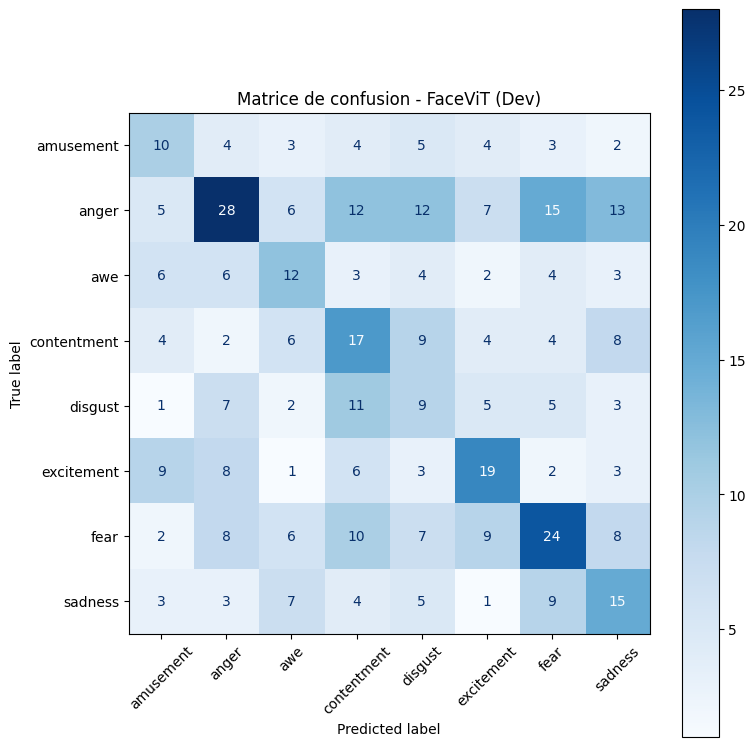

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

emotions = [
    "amusement", "anger", "awe", "contentment",
    "disgust", "excitement", "fear", "sadness"
]

# Calcul de la matrice
cm_face = confusion_matrix(
    y_dev_face,
    y_pred_dev_face,
    labels=emotions
)

# Affichage avec ConfusionMatrixDisplay
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_face,
    display_labels=emotions
)

fig, ax = plt.subplots(figsize=(8, 8))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("Matrice de confusion - FaceViT (Dev)")
plt.tight_layout()
plt.show()

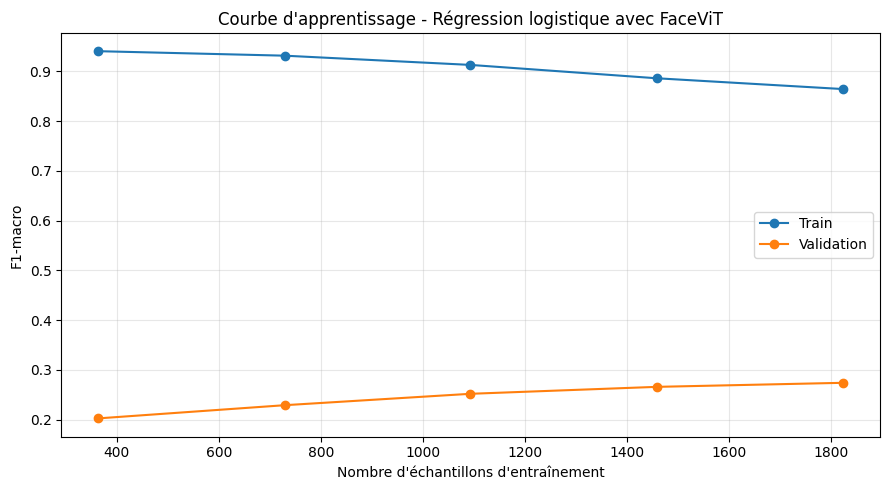

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedGroupKFold

tailles, scores_train_face, scores_val_face = learning_curve(
    modele_face_reg,
    X_train_face_scaled,
    y_train_face,
    groups=film_train_face,
    cv=StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

moyenne_train_face = scores_train_face.mean(axis=1)
moyenne_val_face = scores_val_face.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(tailles, moyenne_train_face, marker="o", label="Train")
plt.plot(tailles, moyenne_val_face, marker="o", label="Validation")

plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("F1-macro")
plt.title("Courbe d'apprentissage - Régression logistique avec FaceViT")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

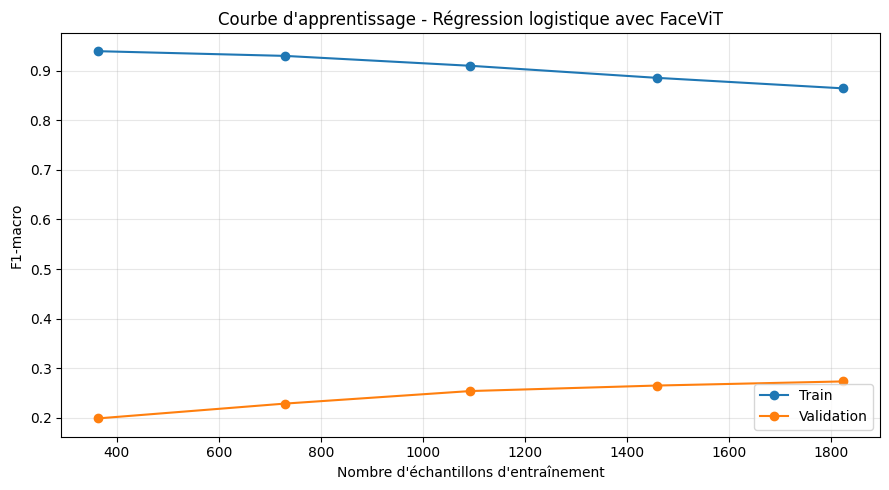

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

modele_face_bal = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=0.003,
        solver="saga",
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
)

tailles, scores_train_face, scores_val_face = learning_curve(
    modele_face_bal,
    X_train_face,
    y_train_face,
    groups=film_train_face,
    cv=StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=-1
)

moyenne_train_face = scores_train_face.mean(axis=1)
moyenne_val_face = scores_val_face.mean(axis=1)

plt.figure(figsize=(9, 5))

plt.plot(
    tailles,
    moyenne_train_face,
    marker="o",
    label="Train"
)

plt.plot(
    tailles,
    moyenne_val_face,
    marker="o",
    label="Validation"
)

plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("F1-macro")
plt.title("Courbe d'apprentissage - Régression logistique avec FaceViT")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Vit Face expression 768

In [ ]:
X_vit_768 = X_vit[:, :768]

print("FaceViT moyenne :", X_vit_768.shape)

FaceViT moyenne : (3088, 768)


In [ ]:
def preparer_partition_vit_768(nom_split):
    subset = df_face[df_face["split"] == nom_split].copy()

    indices = subset.index
    X = X_vit_768[indices]
    y = subset["emotion"].values
    ids = subset["video_id"].values

    return X, y, ids


X_train_vit_768, y_train_vit_768, ids_train_vit_768 = preparer_partition_vit_768("train")
X_dev_vit_768, y_dev_vit_768, ids_dev_vit_768 = preparer_partition_vit_768("dev")
X_test_vit_768, y_test_vit_768, ids_test_vit_768 = preparer_partition_vit_768("test")

print("Train :", X_train_vit_768.shape)
print("Dev :", X_dev_vit_768.shape)
print("Test :", X_test_vit_768.shape)

Train : (2207, 768)
Dev : (442, 768)
Test : (439, 768)


In [ ]:
print("Ordre des vidéos identique :",np.array_equal(ids_videos.astype(str),df_face["video_id"].astype(str).values))

Ordre des vidéos identique : True


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

modele_vit_768 = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=0.003,
        solver="saga",
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    )
)

modele_vit_768.fit(X_train_vit_768, y_train_vit_768)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=0.003, class_weight='balanced',
                                    max_iter=5000, random_state=42,
                                    solver='saga'))])

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_pred_vit_768 = modele_vit_768.predict(X_dev_vit_768)

print("Accuracy :", accuracy_score(y_dev_vit_768, y_pred_vit_768))
print("F1-score macro :", f1_score(y_dev_vit_768, y_pred_vit_768, average="macro"))

print("\nRapport de classification :")
print(classification_report(y_dev_vit_768, y_pred_vit_768))

Accuracy : 0.29638009049773756
F1-score macro : 0.2961549646920903

Rapport de classification :
              precision    recall  f1-score   support

   amusement       0.30      0.29      0.29        35
       anger       0.43      0.22      0.30        98
         awe       0.27      0.40      0.32        40
 contentment       0.20      0.26      0.23        54
     disgust       0.20      0.26      0.22        43
  excitement       0.33      0.35      0.34        51
        fear       0.40      0.28      0.33        74
     sadness       0.28      0.40      0.33        47

    accuracy                           0.30       442
   macro avg       0.30      0.31      0.30       442
weighted avg       0.32      0.30      0.30       442



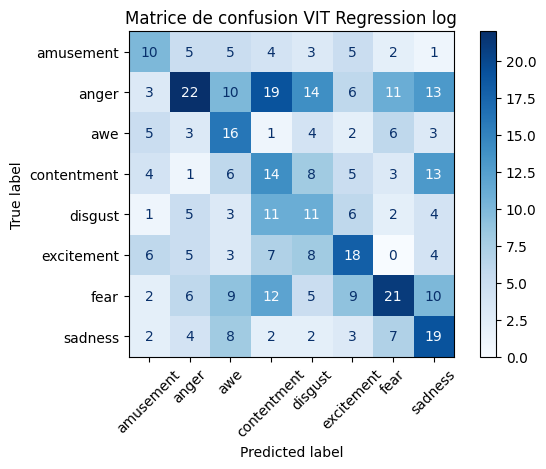

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm_vit_768 = confusion_matrix(
    y_dev_vit_768,
    y_pred_vit_768,
    labels=modele_vit_768.classes_
)

affichage = ConfusionMatrixDisplay(
    confusion_matrix=cm_vit_768,
    display_labels=modele_vit_768.classes_
)
affichage.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matrice de confusion VIT Regression log")
plt.tight_layout()
plt.show()

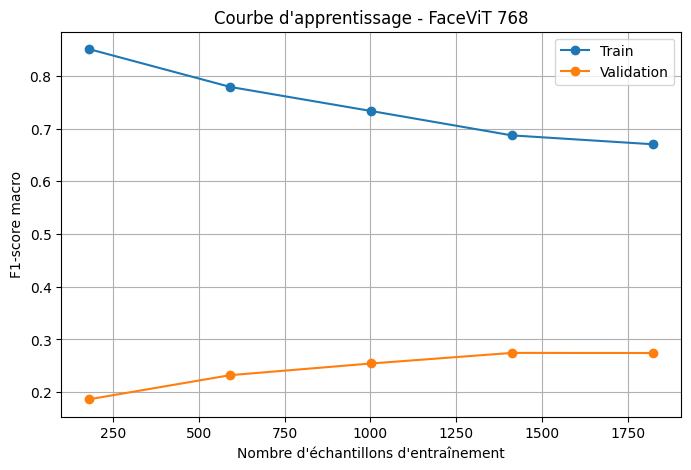

In [ ]:
from sklearn.model_selection import learning_curve, StratifiedGroupKFold
import numpy as np
import matplotlib.pyplot as plt

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

train_sizes, train_scores, dev_scores = learning_curve(
    modele_vit_768,
    X_train_vit_768,
    y_train_vit_768,
    groups=film_train,
    cv=cv,
    scoring="f1_macro",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
dev_mean = dev_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, marker="o", label="Train")
plt.plot(train_sizes, dev_mean, marker="o", label="Validation")

plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("F1-score macro")
plt.title("Courbe d'apprentissage - FaceViT 768")
plt.legend()
plt.grid()
plt.show()

# Fusion CLIP AVEC VIT Face 738

In [ ]:
print("CLIP Train :", X_train_512.shape)
print("CLIP Dev :", X_dev_512.shape)

print("FaceViT Train :", X_train_vit_768.shape)
print("FaceViT Dev :", X_dev_vit_768.shape)

CLIP Train : (2207, 512)
CLIP Dev : (442, 512)
FaceViT Train : (2207, 768)
FaceViT Dev : (442, 768)


In [ ]:
ids_train_512 = df_embeddings[df_embeddings["split"] == "train"]["video_id"].astype(str).values
ids_dev_512 = df_embeddings[df_embeddings["split"] == "dev"]["video_id"].astype(str).values
ids_test_512 = df_embeddings[df_embeddings["split"] == "test"]["video_id"].astype(str).values

print("Train :", len(ids_train_512))
print("Dev :", len(ids_dev_512))
print("Test :", len(ids_test_512))

Train : 2207
Dev : 442
Test : 439


In [ ]:
print("Train :", np.array_equal(ids_train_512, ids_train_vit_768))
print("Dev :", np.array_equal(ids_dev_512, ids_dev_vit_768))
print("Test :", np.array_equal(ids_test_512, ids_test_vit_768))

Train : True
Dev : True
Test : True


In [ ]:
X_test_512 = X_test[:, :512]

print("Test CLIP 512 :", X_test_512.shape)

Test CLIP 512 : (439, 512)


In [ ]:
X_train_fusion = np.concatenate(
    [X_train_512, X_train_vit_768], axis=1
)

X_dev_fusion = np.concatenate(
    [X_dev_512, X_dev_vit_768], axis=1
)

X_test_fusion = np.concatenate(
    [X_test_512, X_test_vit_768], axis=1
)

print("Train :", X_train_fusion.shape)
print("Dev :", X_dev_fusion.shape)
print("Test :", X_test_fusion.shape)

Train : (2207, 1280)
Dev : (442, 1280)
Test : (439, 1280)


In [ ]:
modele_fusion = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=0.003,
        solver="saga",
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    )
)

modele_fusion.fit(X_train_fusion, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=0.003, class_weight='balanced',
                                    max_iter=5000, random_state=42,
                                    solver='saga'))])

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_pred_fusion = modele_fusion.predict(X_dev_fusion)

print("Accuracy :", accuracy_score(y_dev, y_pred_fusion))

print("F1-score macro :",
      f1_score(y_dev, y_pred_fusion, average="macro"))

print("\nRapport de classification :")
print(classification_report(y_dev, y_pred_fusion))

Accuracy : 0.38009049773755654
F1-score macro : 0.379278592291024

Rapport de classification :
              precision    recall  f1-score   support

   amusement       0.40      0.40      0.40        35
       anger       0.49      0.30      0.37        98
         awe       0.36      0.50      0.42        40
 contentment       0.35      0.41      0.38        54
     disgust       0.22      0.35      0.27        43
  excitement       0.40      0.31      0.35        51
        fear       0.54      0.43      0.48        74
     sadness       0.32      0.43      0.37        47

    accuracy                           0.38       442
   macro avg       0.39      0.39      0.38       442
weighted avg       0.41      0.38      0.38       442



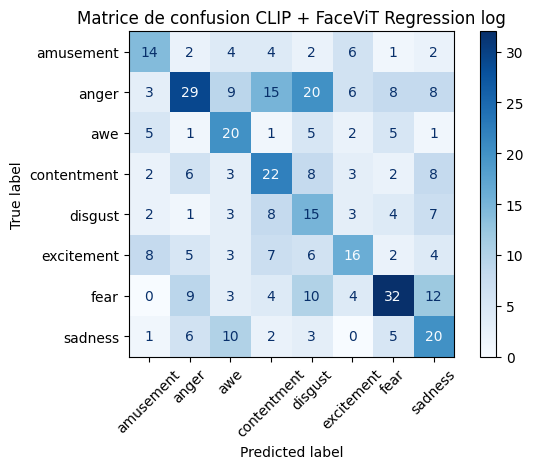

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_fusion = confusion_matrix(
    y_dev,
    y_pred_fusion,
    labels=modele_fusion.classes_
)

affichage = ConfusionMatrixDisplay(
    confusion_matrix=cm_fusion,
    display_labels=modele_fusion.classes_
)

affichage.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matrice de confusion CLIP + FaceViT Regression log")
plt.tight_layout()
plt.show()

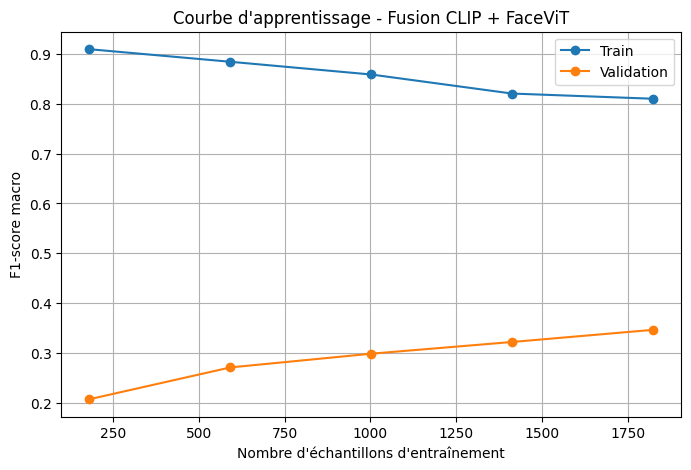

In [ ]:
from sklearn.model_selection import learning_curve, StratifiedGroupKFold
import numpy as np
import matplotlib.pyplot as plt

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_sizes, train_scores, dev_scores = learning_curve(
    modele_fusion,
    X_train_fusion,
    y_train,
    groups=film_train,
    cv=cv,
    scoring="f1_macro",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
dev_mean = dev_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, marker="o", label="Train")
plt.plot(train_sizes, dev_mean, marker="o", label="Validation")

plt.xlabel("Nombre d'échantillons d'entraînement")
plt.ylabel("F1-score macro")
plt.title("Courbe d'apprentissage - Fusion CLIP + FaceViT")
plt.legend()
plt.grid()
plt.show()

# MLP de CLIP + VIT

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import f1_score, accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

import numpy as np

In [ ]:
print("Version PyTorch :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())

Version PyTorch : 2.11.0+cpu
GPU disponible : False


Encoder les émotions

In [ ]:
encodeur = LabelEncoder()

y_train_encoded = encodeur.fit_transform(y_train)
y_dev_encoded = encodeur.transform(y_dev)

print("Correspondance des émotions :", dict(zip(encodeur.classes_, range(len(encodeur.classes_)))))
print("Train :", y_train_encoded.shape)
print("Dev :", y_dev_encoded.shape)

Correspondance des émotions : {'amusement': 0, 'anger': 1, 'awe': 2, 'contentment': 3, 'disgust': 4, 'excitement': 5, 'fear': 6, 'sadness': 7}
Train : (2207,)
Dev : (442,)


In [ ]:
scaler_fusion = StandardScaler()

X_train_scaled = scaler_fusion.fit_transform(X_train_fusion)
X_dev_scaled = scaler_fusion.transform(X_dev_fusion)
X_test_scaled = scaler_fusion.transform(X_test_fusion)

print("Train :", X_train_scaled.shape)
print("Dev :", X_dev_scaled.shape)
print("Test :", X_test_scaled.shape)

Train : (2207, 1280)
Dev : (442, 1280)
Test : (439, 1280)


Préparer les données pour PyTorch

In [ ]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_dev_tensor = torch.tensor(X_dev_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_encoded, dtype=torch.long)
y_dev_tensor = torch.tensor(y_dev_encoded, dtype=torch.long)

print("X_train :", X_train_tensor.shape)
print("y_train :", y_train_tensor.shape)
print("X_dev :", X_dev_tensor.shape)
print("y_dev :", y_dev_tensor.shape)

X_train : torch.Size([2207, 1280])
y_train : torch.Size([2207])
X_dev : torch.Size([442, 1280])
y_dev : torch.Size([442])


In [ ]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
dev_dataset = TensorDataset(X_dev_tensor, y_dev_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=64,
    shuffle=False
)

print("Nombre de batches Train :", len(train_loader))
print("Nombre de batches Dev :", len(dev_loader))

Nombre de batches Train : 35
Nombre de batches Dev : 7


Architecture du MLP

In [ ]:
class MLPFusion(nn.Module):

    def __init__(self):
        super().__init__()

        self.reseau = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, 8)
        )

    def forward(self, x):
        return self.reseau(x)


modele_mlp_fusion = MLPFusion()

print(modele_mlp_fusion)

MLPFusion(
  (reseau): Sequential(
    (0): Linear(in_features=1280, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=256, out_features=8, bias=True)
  )
)


In [ ]:
#fonction de perte
fonction_perte = nn.CrossEntropyLoss()

# Optimiseur
optimiseur = torch.optim.AdamW(
    modele_mlp_fusion.parameters(),
    lr=0.001,
    weight_decay=0.01
)

Svui des performances

In [ ]:
# Créer un nouveau modèle
modele_mlp_simple = MLPFusionSimple()

# Fonction de perte
fonction_perte = nn.CrossEntropyLoss()

# Nouvel optimiseur associé au nouveau modèle
optimiseur = torch.optim.AdamW(
    modele_mlp_simple.parameters(),
    lr=0.0003,
    weight_decay=0.01
)

# Réinitialiser l'historique
historique = {
    "train_loss": [],
    "dev_loss": [],
    "train_f1": [],
    "dev_f1": []
}

# Réinitialiser Early Stopping
meilleur_f1_dev = 0
meilleur_etat = None
meilleure_epoque = 0
patience = 30
compteur_patience = 0

print("Modèle, optimiseur et historique réinitialisés.")

Modèle, optimiseur et historique réinitialisés.


In [ ]:
print("Learning rate :", optimiseur.param_groups[0]["lr"])
print("Weight decay :", optimiseur.param_groups[0]["weight_decay"])
print("Patience :", patience)
print("Nombre de paramètres du modèle :",
      sum(p.numel() for p in modele_mlp_simple.parameters()))

Learning rate : 0.0003
Weight decay : 0.01
Patience : 30
Nombre de paramètres du modèle : 165000


Préparer le mécanisme d'Early Stopping

In [ ]:
import copy

meilleur_etat = None
meilleure_epoque = 0

def sauvegarder_meilleur_modele(modele, f1_dev, epoque):
    global meilleur_f1_dev, meilleur_etat, meilleure_epoque

    if f1_dev > meilleur_f1_dev:
        meilleur_f1_dev = f1_dev
        meilleur_etat = copy.deepcopy(modele.state_dict())
        meilleure_epoque = epoque
        return True

    return False

In [ ]:
from sklearn.metrics import f1_score
import copy

def evaluer_modele(modele, loader):
    modele.eval()

    pertes = []
    predictions = []
    vraies_valeurs = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            sorties = modele(X_batch)
            perte = fonction_perte(sorties, y_batch)

            pertes.append(perte.item())
            predictions.extend(torch.argmax(sorties, dim=1).numpy())
            vraies_valeurs.extend(y_batch.numpy())

    perte_moyenne = np.mean(pertes)
    f1 = f1_score(vraies_valeurs, predictions, average="macro")

    return perte_moyenne, f1


def entrainer_modele(modele, train_loader, dev_loader, nb_epochs=200):
    global meilleur_f1_dev, meilleur_etat, meilleure_epoque
    global compteur_patience, historique

    for epoque in range(1, nb_epochs + 1):

        modele.train()
        pertes_train = []

        for X_batch, y_batch in train_loader:
            optimiseur.zero_grad()

            sorties = modele(X_batch)
            perte = fonction_perte(sorties, y_batch)

            perte.backward()
            optimiseur.step()

            pertes_train.append(perte.item())

        perte_train = np.mean(pertes_train)
        _, f1_train = evaluer_modele(modele, train_loader)

        perte_dev, f1_dev = evaluer_modele(modele, dev_loader)

        historique["train_loss"].append(perte_train)
        historique["dev_loss"].append(perte_dev)
        historique["train_f1"].append(f1_train)
        historique["dev_f1"].append(f1_dev)

        if sauvegarder_meilleur_modele(modele, f1_dev, epoque):
            compteur_patience = 0
        else:
            compteur_patience += 1

        print(
            f"Époque {epoque:03d} | "
            f"Train Loss: {perte_train:.4f} | "
            f"Dev Loss: {perte_dev:.4f} | "
            f"Train F1: {f1_train:.4f} | "
            f"Dev F1: {f1_dev:.4f}"
        )

        if compteur_patience >= patience:
            print("\nEarly Stopping déclenché.")
            break

    modele.load_state_dict(meilleur_etat)

    print("\nMeilleure époque :", meilleure_epoque)
    print("Meilleur F1-macro Dev :", round(meilleur_f1_dev, 4))

    return modele

In [ ]:
modele_mlp_fusion = entrainer_modele(
    modele_mlp_fusion,
    train_loader,
    dev_loader,
    nb_epochs=200
)

Époque 001 | Train Loss: 1.7340 | Dev Loss: 1.7483 | Train F1: 0.5939 | Dev F1: 0.3594
Époque 002 | Train Loss: 1.2116 | Dev Loss: 1.6637 | Train F1: 0.7409 | Dev F1: 0.3742
Époque 003 | Train Loss: 0.9405 | Dev Loss: 1.7321 | Train F1: 0.8269 | Dev F1: 0.3803
Époque 004 | Train Loss: 0.7617 | Dev Loss: 1.7521 | Train F1: 0.8648 | Dev F1: 0.3731
Époque 005 | Train Loss: 0.6156 | Dev Loss: 1.7483 | Train F1: 0.9302 | Dev F1: 0.3932
Époque 006 | Train Loss: 0.4825 | Dev Loss: 1.8634 | Train F1: 0.9420 | Dev F1: 0.3756
Époque 007 | Train Loss: 0.4131 | Dev Loss: 1.9196 | Train F1: 0.9685 | Dev F1: 0.3728
Époque 008 | Train Loss: 0.3255 | Dev Loss: 1.9843 | Train F1: 0.9780 | Dev F1: 0.4008
Époque 009 | Train Loss: 0.2715 | Dev Loss: 2.1536 | Train F1: 0.9793 | Dev F1: 0.3724
Époque 010 | Train Loss: 0.2451 | Dev Loss: 2.1368 | Train F1: 0.9901 | Dev F1: 0.3746
Époque 011 | Train Loss: 0.2030 | Dev Loss: 2.2742 | Train F1: 0.9890 | Dev F1: 0.3639
Époque 012 | Train Loss: 0.1814 | Dev Loss:

Courbes Loss et F1-score

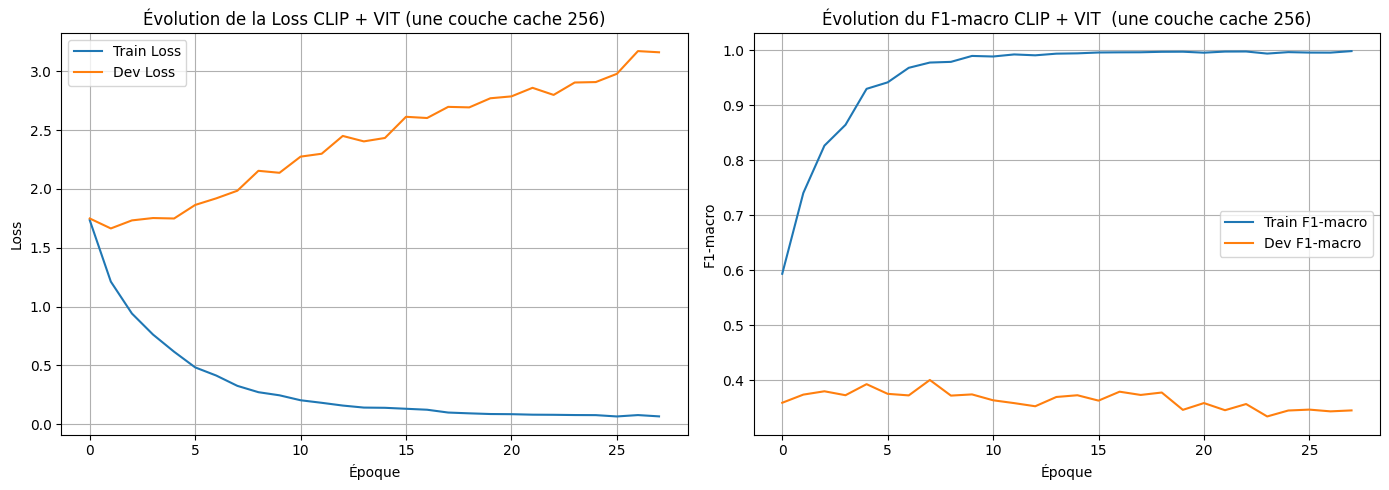

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Courbes Loss
axes[0].plot(historique["train_loss"], label="Train Loss")
axes[0].plot(historique["dev_loss"], label="Dev Loss")
axes[0].set_title("Évolution de la Loss CLIP + VIT (une couche cache 256)")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid()

# Courbes F1-macro
axes[1].plot(historique["train_f1"], label="Train F1-macro")
axes[1].plot(historique["dev_f1"], label="Dev F1-macro")
axes[1].set_title("Évolution du F1-macro CLIP + VIT  (une couche cache 256)")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("F1-macro")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

La diminution continue de la loss d'entraînement et l'augmentation de la loss de validation révèlent un surapprentissage important. De même, le F1-macro atteint presque 1,0 sur l'ensemble d'entraînement, tandis qu'il reste limité à environ 0,39 sur l'ensemble de validation, montrant une faible capacité de généralisation du modèle.

# MLP CLIP+VIT Face expression avce une couche caché 128

In [ ]:
class MLPFusionSimple(nn.Module):

    def __init__(self):
        super().__init__()

        self.reseau = nn.Sequential(
            nn.Linear(1280, 128),
            nn.ReLU(),
            #nn.Dropout(0.5),
            nn.Dropout(0.6),
            nn.Linear(128, 8)
        )

    def forward(self, x):
        return self.reseau(x)


modele_mlp_simple = MLPFusionSimple()

print(modele_mlp_simple)

MLPFusionSimple(
  (reseau): Sequential(
    (0): Linear(in_features=1280, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.6, inplace=False)
    (3): Linear(in_features=128, out_features=8, bias=True)
  )
)


In [ ]:
fonction_perte_simple = nn.CrossEntropyLoss()

optimiseur = torch.optim.AdamW(
    modele_mlp_simple.parameters(),
    lr=0.001,
    # lr=0.0003,
    weight_decay=0.01
    # weight_decay=2e-3

)

In [ ]:
historique = {
    "train_loss": [],
    "dev_loss": [],
    "train_f1": [],
    "dev_f1": []
}

meilleur_f1_dev = 0
meilleur_etat = None
meilleure_epoque = 0
compteur_patience = 0
patience = 30

Entraîner le MLP 2

In [ ]:
modele_mlp_simple = entrainer_modele(
    modele_mlp_simple,
    train_loader,
    dev_loader,
    nb_epochs=200
)

Époque 001 | Train Loss: 1.8624 | Dev Loss: 1.7157 | Train F1: 0.5327 | Dev F1: 0.3380
Époque 002 | Train Loss: 1.4619 | Dev Loss: 1.6548 | Train F1: 0.6449 | Dev F1: 0.3532
Époque 003 | Train Loss: 1.2636 | Dev Loss: 1.6392 | Train F1: 0.7044 | Dev F1: 0.3654
Époque 004 | Train Loss: 1.1372 | Dev Loss: 1.6547 | Train F1: 0.7648 | Dev F1: 0.3693
Époque 005 | Train Loss: 1.0197 | Dev Loss: 1.6700 | Train F1: 0.7949 | Dev F1: 0.3897
Époque 006 | Train Loss: 0.9390 | Dev Loss: 1.6457 | Train F1: 0.8272 | Dev F1: 0.3865
Époque 007 | Train Loss: 0.8544 | Dev Loss: 1.6558 | Train F1: 0.8620 | Dev F1: 0.3960
Époque 008 | Train Loss: 0.8020 | Dev Loss: 1.6785 | Train F1: 0.8842 | Dev F1: 0.3807
Époque 009 | Train Loss: 0.7570 | Dev Loss: 1.6763 | Train F1: 0.9012 | Dev F1: 0.4057
Époque 010 | Train Loss: 0.6617 | Dev Loss: 1.7488 | Train F1: 0.9187 | Dev F1: 0.3844
Époque 011 | Train Loss: 0.6297 | Dev Loss: 1.7706 | Train F1: 0.9320 | Dev F1: 0.3908
Époque 012 | Train Loss: 0.5977 | Dev Loss:

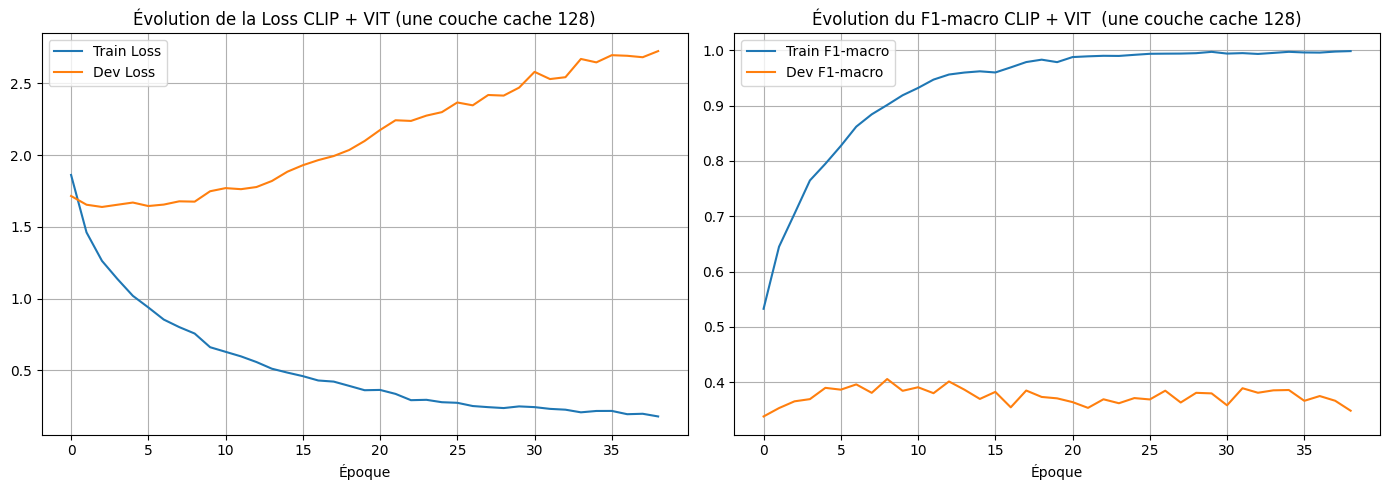

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(historique["train_loss"], label="Train Loss")
axes[0].plot(historique["dev_loss"], label="Dev Loss")
axes[0].set_title("Évolution de la Loss CLIP + VIT (une couche cache 128)")
axes[0].set_xlabel("Époque")
axes[0].legend()
axes[0].grid()

axes[1].plot(historique["train_f1"], label="Train F1-macro")
axes[1].plot(historique["dev_f1"], label="Dev F1-macro")
axes[1].set_title("Évolution du F1-macro CLIP + VIT  (une couche cache 128)")
axes[1].set_xlabel("Époque")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

# Sauvegarde modele final

In [ ]:
import joblib

joblib.dump(
    modele_clip_512_sans_poids,
    dossier_features / "modele_video_clip_512_sans_poids.joblib"
)

print("Modèle sauvegardé !")

Modèle sauvegardé !


In [ ]:
import pandas as pd

fichier_ids = base / "ids_video.csv"
ids_existants = pd.read_csv(
    fichier_ids,
    dtype=str
)["video_id"].tolist()

In [ ]:
X_test_512 = X_video[labels["split"].values == "test", :512]
y_test = labels.loc[labels["split"] == "test", "emotion"].values

In [ ]:
print("Dimensions des features :")
print("Train :", X_train_512.shape)
print("Dev   :", X_dev_512.shape)
print("Test  :", X_test_512.shape)

print("\nNombre de vidéos dans labels :")
print("Train :", (labels["split"] == "train").sum())
print("Dev   :", (labels["split"] == "dev").sum())
print("Test  :", (labels["split"] == "test").sum())

Dimensions des features :
Train : (2207, 512)
Dev   : (442, 512)
Test  : (439, 512)

Nombre de vidéos dans labels :
Train : 2207
Dev   : 442
Test  : 439


In [ ]:
probas_video_dev = modele_clip_512_sans_poids.predict_proba(X_dev_512)
probas_video_test = modele_clip_512_sans_poids.predict_proba(X_test_512)

print("Probabilités vidéo Dev :", probas_video_dev.shape)
print("Probabilités vidéo Test :", probas_video_test.shape)

print("Somme des probabilités Dev :",np.allclose(probas_video_dev.sum(axis=1), 1))

print("Somme des probabilités Test :",np.allclose(probas_video_test.sum(axis=1), 1))

Probabilités vidéo Dev : (442, 8)
Probabilités vidéo Test : (439, 8)
Somme des probabilités Dev : True
Somme des probabilités Test : True


In [ ]:
# Sauvegarder les probabilités
np.save(dossier_features / "probas_video_dev.npy", probas_video_dev)
np.save(dossier_features / "probas_video_test.npy", probas_video_test)

# Sauvegarder les identifiants correspondants
labels.loc[labels["split"] == "dev", ["video_id"]].to_csv(dossier_features / "ids_video_dev.csv", index=False)
labels.loc[labels["split"] == "test", ["video_id"]].to_csv(dossier_features / "ids_video_test.csv", index=False)

# Sauvegarder l'ordre des classes
np.save(dossier_features / "classes_video.npy",modele_clip_512_sans_poids.classes_)

print("Fichiers vidéo sauvegardés avec succès !")

Fichiers vidéo sauvegardés avec succès !


In [ ]:
ids_dev = pd.read_csv(dossier_features / "ids_video_dev.csv",dtype=str)["video_id"].values
ids_test = pd.read_csv(dossier_features / "ids_video_test.csv",dtype=str)["video_id"].values

probs_dev = np.load(dossier_features / "probas_video_dev.npy")
probs_test = np.load(dossier_features / "probas_video_test.npy")

classes = np.load(dossier_features / "classes_video.npy",allow_pickle=True)

df_probas_dev = pd.DataFrame(probs_dev, columns=classes)
df_probas_dev.insert(0, "video_id", ids_dev)
df_probas_test = pd.DataFrame(probs_test, columns=classes)
df_probas_test.insert(0, "video_id", ids_test)

df_probas_dev.to_csv(dossier_features / "probas_video_dev.csv",index=False)
df_probas_test.to_csv(dossier_features / "probas_video_test.csv",index=False)

In [ ]:
# Calculer les probabilités du train
probas_video_train = modele_clip_512_sans_poids.predict_proba(X_train_512)

# Récupérer les IDs du train
ids_train = labels.loc[labels["split"] == "train", "video_id"].values

# Créer le DataFrame
df_probas_train = pd.DataFrame(
    probas_video_train,
    columns=modele_clip_512_sans_poids.classes_
)

df_probas_train.insert(0, "video_id", ids_train)

# Sauvegarder le CSV
df_probas_train.to_csv(
    dossier_features / "probas_video_train.csv",
    index=False
)

print(df_probas_train.shape)

(2207, 9)


Telechargement des embadding de Clip 512 du molele choisi

In [ ]:
print("Meanstd :", X_video_meanstd.shape)
X_video_512 = X_video_meanstd[:, :512]
print("X_video_512 :", X_video_512.shape)
np.save(dossier_features / "X_video_512.npy", X_video_512)
test = np.load(dossier_features / "X_video_512.npy")
print("Fichier sauvegardé :", test.shape)

Meanstd : (3088, 1024)
X_video_512 : (3088, 512)
Fichier sauvegardé : (3088, 512)


In [ ]:
for f in dossier_features.glob("*.npy"):
    arr = np.load(f, allow_pickle=True)
    print(f.name, arr.shape)

X_video_baseline.npy (3088, 141)
ids_video_resnet.npy (3088,)
X_video_resnet_mean.npy (3088, 512)
X_video_meanstd.npy (3088, 1024)
probas_video_dev.npy (442, 8)
probas_video_test.npy (439, 8)
classes_video.npy (8,)
X_video_512.npy (3088, 512)
